# PlantPulse: comprehensive equipment data review

## tl;dr
This review decides what we can build from the supplied daily equipment data. The primary scope is two named RO high-pressure pumps in Plant A and four in Plant B. Production and water-quality records are supporting context.

**Observed findings:** 244 equipment days per plant; Plant A has 25 varying signals and Plant B has 60. There are 21 and 10 adjacent full-reading repeats respectively. Both Plant A runtime counters have a 183-day flat run and a decrease on 3 July. Plant A's power-labelled readings remain positive on all zero-frequency days, so zero frequency cannot safely establish an off state. Plant B's frequency/`a_out` pairs are more coherent, but their units and physical interpretation remain provisional.

**Build decision:** proceed with an equipment data-quality view and explainable, plant-specific trend/change investigation. Treat a calibrated pump-degradation model as conditional on the evidence below. No confirmed fault diagnosis, physical safety thresholds, or demonstrated savings follow from this review.

The first-90-day relationship screen flags 34 of 97 in-range later pairs for Plant B Pump 1 at cutoff 3.5 (22–52 across cutoffs 4.0–3.0). Plant B Pumps 2 and 4 each have only ten later pairs within their training frequency ranges. This is evidence that a fixed early-period baseline needs review, not a basis for deploying fault alerts.

**Historical pattern review:** Plant B Pump 1 has an 11-day period above the earlier response reference, from May 3 to May 13. August plant specific energy is 5.8% lower for Plant A and 3.0% lower for Plant B than July. The final section separates review flags, new frequency ranges, and data problems. It includes charts and checks. These findings do not establish equipment faults or measured savings.


**Energy detection prototype:** the final section compares regression with fixed specific energy using chronological July checks, tests positive CUSUM and supplies a provisional investigation reference. August is an exploratory replay because it has already been inspected. Executed comparison and constructed-check tables report coverage, review events and detection delay. The volume-only baseline remains experimental, particularly for Plant B.

## Context & Methods
Reviewed 12 October 2026. The organisers identify the equipment daily datasets as the AI focus and deliberately leave cleaning to participants. `INFO.md` defines the challenge; `DATA.md` defines source restrictions. Waterhaus/AquaxGo brochures and the reference process flow place the RO high-pressure pump before the RO membranes, but do not map CSV tags to sensors or identify Plant A/B. Do not infer the original plant identities.

### Key assumptions
- Daily rows are observations, not verified daily averages, snapshots or operating hours.
- Tag-based pump grouping is a naming interpretation; the dictionary marks equipment units unconfirmed.
- Raw files remain unchanged. Missing values stay missing; suspicious readings and repeated days are retained and flagged.
- Full-history profiles/correlations are exploratory. The candidate alert screen fits only the first 90 calendar days and evaluates later dates. Historical behaviour is not automatically healthy behaviour.
- No verified failure labels, maintenance logs, controlled AI comparison or water-quality limits are supplied.

### Re-run
Place this notebook beside `Dataset/`, select the project `.venv` Python kernel, and Run All. Dependencies: pandas, NumPy, Matplotlib and IPython; nbformat/nbclient are needed for automated execution only. All figures are embedded in saved outputs. Supporting inputs: `Dataset/data_dictionary.xlsx`, `Dataset/plant_daily_performance.csv`, `Resources/BlueNexus AquaxGo.pdf`, `Resources/BlueNexus Waterhaus.pdf`, and `Resources/Waterhaus Process Flow.pdf`.

In [1]:
from pathlib import Path
from itertools import combinations
from zipfile import ZipFile
from xml.etree import ElementTree as ET
import hashlib
import platform
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from IPython.display import display, HTML

pd.set_option('display.max_columns', 14)
pd.set_option('display.max_rows', 24)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')
plt.rcParams.update({'figure.figsize': (11, 4), 'figure.dpi': 120,
                     'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': .18, 'axes.prop_cycle': plt.cycler(color=['#24658c', '#bd7924'])})
root = Path.cwd()
source_dir = next((p / 'Dataset' for p in [root, root.parent] if (p / 'Dataset').is_dir()), None)
if source_dir is None:
    raise FileNotFoundError('Run beside Dataset/, or set source_dir to its actual path.')
names = {'Plant A': 'plant_A_equipment_daily.csv', 'Plant B': 'plant_B_equipment_daily.csv',
         'Performance': 'plant_daily_performance.csv'}
paths = {key: source_dir / name for key, name in names.items()}
input_paths = list(paths.values()) + [source_dir / 'data_dictionary.xlsx']
source_hashes = {p: hashlib.sha256(p.read_bytes()).hexdigest() for p in input_paths}
raw = {key: pd.read_csv(path, dtype=str, keep_default_na=False) for key, path in paths.items()}
print('Python', platform.python_version(), '| pandas', pd.__version__, '| NumPy', np.__version__)
display(pd.DataFrame([{'Source': p.name, 'SHA256': digest} for p, digest in source_hashes.items()]))

Python 3.14.5 | pandas 3.0.6 | NumPy 2.5.4


,Source,SHA256
0,plant_A_equipment_daily.csv,8b99905f8aced981fd0ea49ea57f6b38f1453d9935a031...
1,plant_B_equipment_daily.csv,a65f08b1fc711e6c3a0e5ae9cdbef6b9f7afa6a5785029...
2,plant_daily_performance.csv,f2204d5fbc6203d6701bd3feaa7467f59857abf9b3eb9b...
3,data_dictionary.xlsx,390a8b4bb3ba536d9947023bc8b78d73e0643b841e9eeb...


## Data
### 1. Parse, audit and validate dates
Strip surrounding whitespace and recognize blank, `NULL` and `/` markers. Record parsing failures before coercion; do not silently turn unknown text into valid measurements. Sort dates, preserve every source row, and reject missing/duplicate daily keys before comparisons. All non-key columns are expected numeric. Infinities are flagged and excluded from calculations.

In [2]:
data, parse_rows, coverage = {}, [], []
for key, frame in raw.items():
    cleaned = frame.apply(lambda col: col.str.strip()).replace({'': np.nan, 'NULL': np.nan, '/': np.nan})
    dates = pd.to_datetime(cleaned['date'], format='mixed', errors='coerce')
    assert dates.notna().all(), f'{key}: invalid/missing dates'
    numeric_columns = cleaned.columns.difference(['date', 'plant'])
    numeric = cleaned[numeric_columns].apply(pd.to_numeric, errors='coerce')
    for field in numeric_columns:
        invalid = cleaned[field].notna() & numeric[field].isna()
        parse_rows.append({'Dataset': key, 'Field': field, 'Missing markers': int(cleaned[field].isna().sum()),
                           'Unparsed values': int(invalid.sum()), 'Infinite values': int(np.isinf(numeric[field]).sum())})
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    numeric['date'] = dates
    if 'plant' in cleaned:
        assert cleaned['plant'].isin(['Plant A', 'Plant B']).all()
        numeric['plant'] = cleaned['plant']
    keys = ['plant', 'date'] if 'plant' in numeric else ['date']
    assert not numeric.duplicated(keys).any(), f'{key}: duplicate daily keys; resolve before joining'
    data[key] = numeric.sort_values(keys).reset_index(drop=True)
    groups = data[key].groupby('plant') if 'plant' in numeric else [(key, data[key])]
    for plant, group in groups:
        expected = pd.date_range(group.date.min(), group.date.max())
        coverage.append({'Dataset': key, 'Plant': plant, 'Rows': len(group), 'Columns': len(frame.columns),
                         'Start': group.date.min().date(), 'End': group.date.max().date(),
                         'Missing calendar days': len(expected.difference(group.date)),
                         'Duplicate keys': int(group.duplicated('date').sum())})
parse_audit = pd.DataFrame(parse_rows)
display(pd.DataFrame(coverage))
print('Unparsed numeric values:', int(parse_audit['Unparsed values'].sum()),
      '| Infinite values:', int(parse_audit['Infinite values'].sum()))
display(parse_audit.loc[(parse_audit['Unparsed values'] + parse_audit['Infinite values']).gt(0)])
equipment = {plant: data[plant].set_index('date') for plant in ['Plant A', 'Plant B']}
performance = data['Performance']

,Dataset,Plant,Rows,Columns,Start,End,Missing calendar days,Duplicate keys
0,Plant A,Plant A,244,47,2026-01-01,2026-09-01,0,0
1,Plant B,Plant B,244,77,2026-01-01,2026-09-01,0,0
2,Performance,Plant A,62,32,2026-07-01,2026-08-31,0,0
3,Performance,Plant B,62,32,2026-07-01,2026-08-31,0,0


Unparsed numeric values: 0 | Infinite values: 0


,Dataset,Field,Missing markers,Unparsed values,Infinite values


### 2. Read the dictionary and audit its coverage
Read the workbook using Python's standard XML/ZIP libraries, so rerunning does not need an Excel engine. Dictionary definitions are source documentation, not independent confirmation of sensor meanings. Compare dictionary missingness counts with actual missing observations.

In [3]:
ns = {'s': 'http://schemas.openxmlformats.org/spreadsheetml/2006/main'}
with ZipFile(source_dir / 'data_dictionary.xlsx') as workbook:
    strings = [''.join(node.itertext()) for node in ET.fromstring(workbook.read('xl/sharedStrings.xml'))] if 'xl/sharedStrings.xml' in workbook.namelist() else []
    dictionary_rows = []
    for row in ET.fromstring(workbook.read('xl/worksheets/sheet1.xml')).findall('.//s:sheetData/s:row', ns):
        values = []
        for cell in row:
            value, inline = cell.find('s:v', ns), cell.find('s:is', ns)
            text = value.text if value is not None else ''.join(inline.itertext()) if inline is not None else ''
            values.append(strings[int(text)] if cell.get('t') == 's' else text)
        dictionary_rows.append(values)
dictionary = pd.DataFrame(dictionary_rows[1:], columns=dictionary_rows[0])
dictionary['Dataset'] = dictionary['File'].map({v: k for k, v in names.items()})
dictionary['Documented missing'] = pd.to_numeric(dictionary['Missingness'].str.extract(r'^(\d+)/')[0], errors='coerce')
dictionary_audit = dictionary.merge(parse_audit, left_on=['Dataset', 'English column'], right_on=['Dataset', 'Field'], how='left', validate='one_to_one')
print('Dictionary entries:', len(dictionary), '| equipment reported units:', dictionary.loc[dictionary.Dataset.isin(equipment), 'Reported unit'].unique())
display(dictionary_audit.loc[dictionary_audit['English column'].ne('date') & dictionary_audit['Documented missing'].notna() & dictionary_audit['Documented missing'].ne(dictionary_audit['Missing markers']),
                             ['Dataset', 'English column', 'Documented missing', 'Missing markers']])
print('Date and plant keys are validated separately in section 1.')

Dictionary entries: 156 | equipment reported units: <StringArray>
['Unconfirmed']
Length: 1, dtype: str


,Dataset,English column,Documented missing,Missing markers


Date and plant keys are validated separately in section 1.


## Results
### 3. Full signal inventory and feature eligibility
All fields remain in `equipment`. The eligibility labels describe analytical use, not sensor health. Varying binary/status-like fields need different treatment from continuous signals. Raw cumulative levels are not consumption features. Unmapped Plant B meter groups stay unmapped.

In [4]:
inventory_rows = []
for plant, frame in equipment.items():
    for field, series in frame.items():
        count, unique = int(series.notna().sum()), int(series.nunique())
        counter = 'cumulative' in field or field.endswith('_ep') or field.startswith('advancedtags')
        binary = count > 0 and set(series.dropna().unique()).issubset({0, 1})
        pump = next((f'RO pump {i}' for i in range(1, 5) if any(token in field for token in [f'{i}_rohigh_pressure_pump', f'ro{i}_high_pressure_pump'])), 'Supporting / unmapped')
        use = 'Exclude: empty' if not count else 'Exclude: constant' if unique == 1 else 'Counter: review differences' if counter else 'Status: sparse/interpretation review' if binary else 'Candidate: validate meaning/regime'
        inventory_rows.append({'Plant': plant, 'Equipment': pump, 'Field': field, 'Populated days': count,
                               'Missing %': 100 * (1 - count / len(series)), 'Unique values': unique,
                               'Zero days': int(series.eq(0).sum()), 'Minimum': series.min(), 'Maximum': series.max(), 'Use': use})
inventory = pd.DataFrame(inventory_rows)
display(pd.crosstab(inventory.Plant, inventory.Use))
for plant in equipment:
    table = inventory.loc[inventory.Plant.eq(plant)].drop(columns='Plant')
    display(HTML(f'<details><summary>{plant}: complete signal inventory ({len(table)} fields)</summary>' + table.to_html(index=False, float_format=lambda v: f'{v:.2f}') + '</details>'))
candidate_signals = {plant: frame.loc[:, frame.nunique().gt(1)] for plant, frame in equipment.items()}
assert all(frame.shape[1] == int(inventory.loc[inventory.Plant.eq(plant), 'Unique values'].gt(1).sum()) for plant, frame in candidate_signals.items())

Use,Candidate: validate meaning/regime,Counter: review differences,Exclude: constant,Exclude: empty,Status: sparse/interpretation review
Plant,,,,,
Plant A,18,4,7,14,3
Plant B,52,8,0,16,0


Equipment,Field,Populated days,Missing %,Unique values,Zero days,Minimum,Maximum,Use
RO pump 1,1_rohigh_pressure_pump_current_feedback_o,244,0.00,1,244,0.00,0.00,Exclude: constant
RO pump 1,1_rohigh_pressure_pump_cz_o,244,0.00,153,38,0.00,4.91,Candidate: validate meaning/regime
RO pump 1,1_rohigh_pressure_pump_frequency_feedback_o,244,0.00,171,56,0.00,48.63,Candidate: validate meaning/regime
RO pump 1,1_rohigh_pressure_pump_hz_temp_o,244,0.00,1,244,0.00,0.00,Exclude: constant
RO pump 1,1_rohigh_pressure_pump_qz_temp_o,244,0.00,198,0,12.14,212.73,Candidate: validate meaning/regime
RO pump 2,2_rohigh_pressure_pump_current_feedback_o,244,0.00,1,244,0.00,0.00,Exclude: constant
RO pump 2,2_rohigh_pressure_pump_cz_o,244,0.00,170,30,0.00,6.67,Candidate: validate meaning/regime
RO pump 2,2_rohigh_pressure_pump_frequency_feedback_o,244,0.00,162,64,0.00,49.88,Candidate: validate meaning/regime
RO pump 2,2_rohigh_pressure_pump_hz_temp_o,244,0.00,1,244,0.00,0.00,Exclude: constant
RO pump 2,2_rohigh_pressure_pump_qz_temp_o,244,0.00,214,0,20.38,66.75,Candidate: validate meaning/regime


Equipment,Field,Populated days,Missing %,Unique values,Zero days,Minimum,Maximum,Use
Supporting / unmapped,advancedtags_1aa3_lj,244,0.00,234,0,2528368.50,3226637.75,Counter: review differences
Supporting / unmapped,advancedtags_1aa4_lj,244,0.00,234,0,2546463.25,3184095.75,Counter: review differences
Supporting / unmapped,advancedtags_2aa2_lj,244,0.00,159,0,2504152.50,2953717.25,Counter: review differences
Supporting / unmapped,advancedtags_2aa3_lj,244,0.00,159,0,2636760.00,3055321.25,Counter: review differences
RO pump 1,c4_m4_ro1_high_pressure_pump_wd,244,0.00,192,0,28.52,56.11,Candidate: validate meaning/regime
RO pump 1,c4_m4_ro1_high_pressure_pump_xsd,244,0.00,4,0,0.10,1.40,Candidate: validate meaning/regime
RO pump 1,c4_m4_ro1_high_pressure_pump_xwy,244,0.00,4,0,0.50,1.20,Candidate: validate meaning/regime
RO pump 1,c4_m4_ro1_high_pressure_pump_ysd,244,0.00,11,0,0.10,6.50,Candidate: validate meaning/regime
RO pump 1,c4_m4_ro1_high_pressure_pump_ywy,244,0.00,22,15,0.00,64.50,Candidate: validate meaning/regime
RO pump 1,c4_m4_ro1_high_pressure_pump_zsd,244,0.00,8,0,0.80,2.10,Candidate: validate meaning/regime


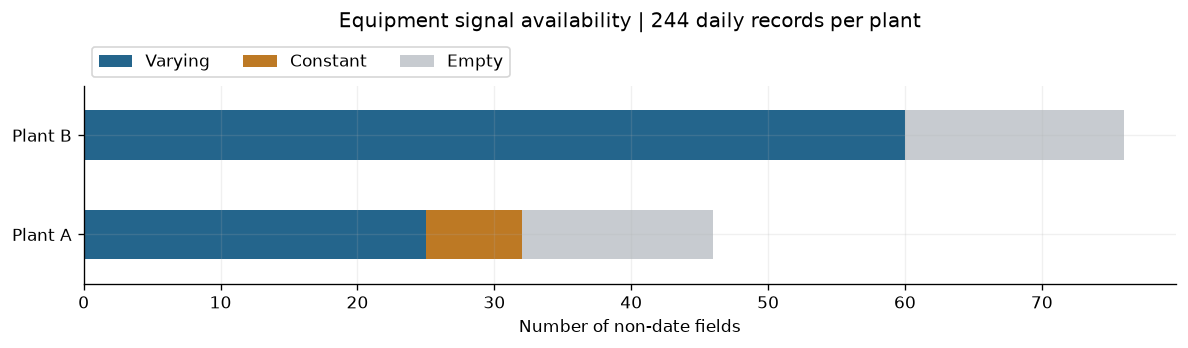

In [5]:
summary = inventory.assign(State=np.where(inventory['Populated days'].eq(0), 'Empty', np.where(inventory['Unique values'].eq(1), 'Constant', 'Varying'))).groupby(['Plant', 'State']).size().unstack(fill_value=0)
ax = summary[['Varying', 'Constant', 'Empty']].plot.barh(stacked=True, color=['#24658c', '#bd7924', '#c7cbd0'], figsize=(10, 3))
ax.set(title='Equipment signal availability | 244 daily records per plant', xlabel='Number of non-date fields', ylabel='')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncols=3)
ax.set_title('Equipment signal availability | 244 daily records per plant', pad=35)
plt.tight_layout(); plt.show()

### 4. Repeated readings, flat runs and duplicate signals
Compare all varying signals, treating paired missing values as equal. Full-row repeats on different dates are suspicious replay/staleness candidates, not duplicate date keys. Flat single signals may be legitimate steady operation or limited resolution. Do not delete them automatically. Exact duplicate-column checks are separate from correlation.

,Plant,Adjacent full-reading repeats,Repeated reading vectors anywhere
0,Plant A,21,21
1,Plant B,10,10


,Plant,Date
0,Plant A,2026-04-20
1,Plant A,2026-04-23
2,Plant A,2026-05-18
3,Plant A,2026-05-19
4,Plant A,2026-05-20
...,...,...
26,Plant B,2026-04-27
27,Plant B,2026-05-21
28,Plant B,2026-06-05
29,Plant B,2026-06-19


,Plant,Field,Longest identical populated run
8,Plant A,p_1_rohigh_pressure_pump_runtime_cumulative,183
10,Plant A,p_2_rohigh_pressure_pump_runtime_cumulative,183
31,Plant B,c4_m4_ro1_high_pressure_pump_xwy,155
30,Plant B,c4_m4_ro1_high_pressure_pump_xsd,119
35,Plant B,c4_m4_ro1_high_pressure_pump_zwy,108
58,Plant B,wg_a_1aa3_a58,108
66,Plant B,wg_a_1aa4_a58,88
81,Plant B,wg_c_2aa3_a58,83
73,Plant B,wg_c_2aa2_a58,83
70,Plant B,wg_c_2aa2_a1,81


Exact duplicate varying signal pairs: 0


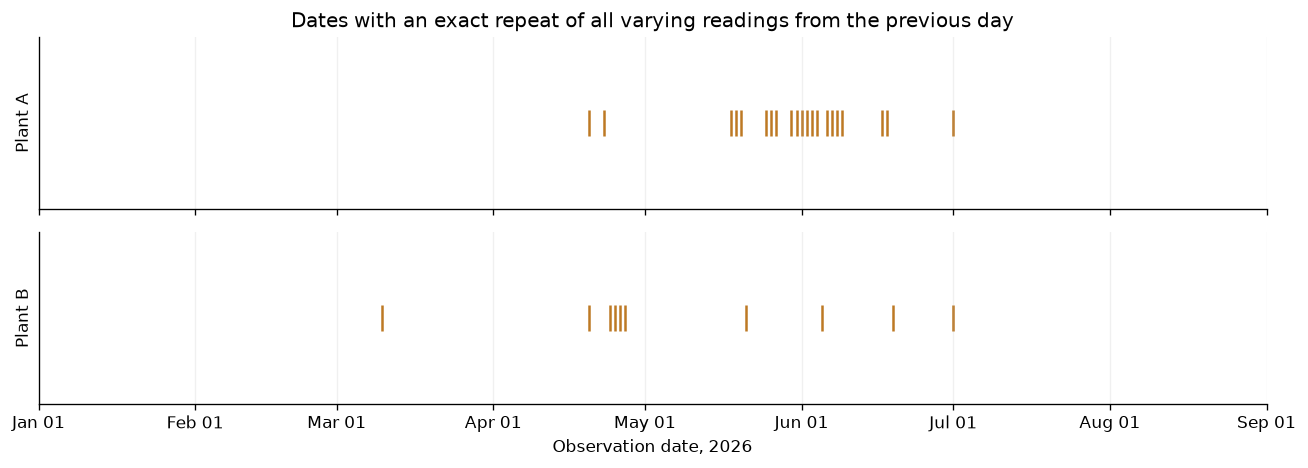

In [6]:
repeat_masks, repeat_rows, flat_rows, duplicate_columns = {}, [], [], []
for plant, frame in candidate_signals.items():
    previous = frame.shift()
    repeated = (frame.eq(previous) | (frame.isna() & previous.isna())).all(axis=1)
    repeated.iloc[0] = False
    repeat_masks[plant] = repeated
    for date in frame.index[repeated]: repeat_rows.append({'Plant': plant, 'Date': date})
    for field, series in frame.items():
        groups = series.ne(series.shift()) | series.isna() | series.shift().isna()
        runs = series.groupby(groups.cumsum()).agg(['size', 'first'])
        flat_rows.append({'Plant': plant, 'Field': field, 'Longest identical populated run': int(runs.loc[runs['first'].notna(), 'size'].max())})
    for first, second in combinations(frame.columns, 2):
        if frame[first].equals(frame[second]): duplicate_columns.append({'Plant': plant, 'First': first, 'Second': second})
repeat_events = pd.DataFrame(repeat_rows, columns=['Plant', 'Date'])
flat_runs = pd.DataFrame(flat_rows)
display(pd.DataFrame([{'Plant': plant, 'Adjacent full-reading repeats': int(mask.sum()),
                       'Repeated reading vectors anywhere': int(candidate_signals[plant].duplicated().sum())} for plant, mask in repeat_masks.items()]))
display(repeat_events)
display(flat_runs.sort_values('Longest identical populated run', ascending=False).head(12))
print('Exact duplicate varying signal pairs:', len(duplicate_columns))
fig, axes = plt.subplots(2, 1, figsize=(11, 4), sharex=True)
for ax, (plant, mask) in zip(axes, repeat_masks.items()):
    ax.scatter(mask.index[mask], np.ones(mask.sum()), marker='|', s=250, color='#bd7924')
    ax.set(yticks=[], ylabel=plant, ylim=(.5, 1.5), xlim=(mask.index.min(), mask.index.max()))
axes[0].set_title('Dates with an exact repeat of all varying readings from the previous day')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[-1].set_xlabel('Observation date, 2026'); plt.tight_layout(); plt.show()

**Interpretation:** unchanged multi-signal rows reduce the number of independent-looking observations. Both plants repeat on 1 July and 20 April; shared dates are evidence for a possible acquisition/reporting issue, not proof of one. Plant A has prolonged runtime-counter flatness despite variation in other signals.

### 5. Counter audit and safe differences
Compute a difference only between consecutive calendar days with two populated readings. Mask negative differences and the first difference after a decrease; do not replace them with zero or impute a reset amount. Mask adjacent full-reading repeats and their next day too, since a fresh value may include a multi-day catch-up. Even retained differences have unknown units and aggregation semantics. These exclusions are conservative analysis decisions, not repairs to the source.

,Plant,Counter,Negative differences,Zero differences,Maximum positive difference
0,Plant A,p_1_rohigh_pressure_pump_runtime_cumulative,1,209,58.350
1,Plant A,p_2_rohigh_pressure_pump_runtime_cumulative,1,212,85.749
2,Plant A,zz_1_rohigh_pressure_pump_ep,2,25,"105,240,200.000"
3,Plant A,zz_2_rohigh_pressure_pump_ep,0,26,"2,032,688.000"
4,Plant B,advancedtags_1aa3_lj,0,10,"15,138.000"
5,Plant B,advancedtags_1aa4_lj,0,10,"10,163.750"
6,Plant B,advancedtags_2aa2_lj,0,85,"12,946.000"
7,Plant B,advancedtags_2aa3_lj,0,85,"12,563.500"
8,Plant B,c_m_ro1_high_pressure_pump_runtime_cumulative,0,10,107.180
9,Plant B,c_m_ro2_high_pressure_pump_runtime_cumulative,0,10,85.564


,Plant,Date,Counter,Before,After,Difference
0,Plant A,2026-07-03,p_1_rohigh_pressure_pump_runtime_cumulative,988.467,6.936,-981.532
1,Plant A,2026-07-03,p_2_rohigh_pressure_pump_runtime_cumulative,992.302,6.906,-985.396
2,Plant A,2026-01-10,zz_1_rohigh_pressure_pump_ep,"64,475,248.000",0.000,"-64,475,248.000"
3,Plant A,2026-05-02,zz_1_rohigh_pressure_pump_ep,"105,219,296.000",0.000,"-105,219,296.000"


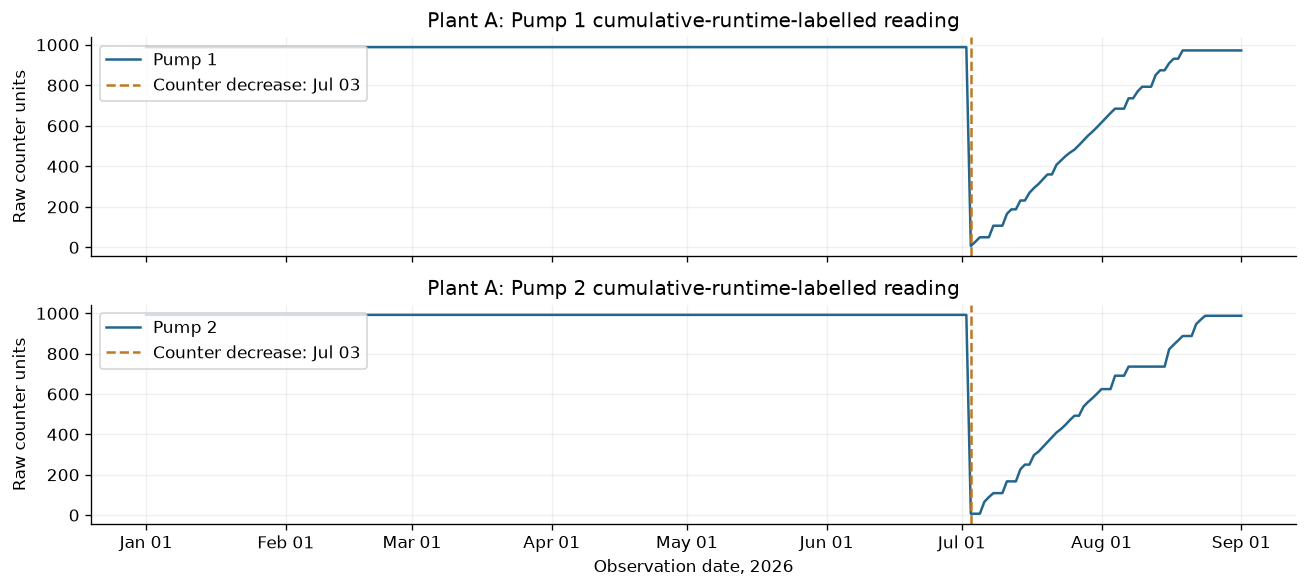

In [7]:
counter_summary, counter_events, counter_deltas = [], [], {}
for plant, frame in equipment.items():
    consecutive = frame.index.to_series().diff().eq(pd.Timedelta(days=1))
    counter_deltas[plant] = pd.DataFrame(index=frame.index)
    for field in inventory.loc[inventory.Plant.eq(plant) & inventory.Use.eq('Counter: review differences'), 'Field']:
        series = frame[field]
        delta = series.diff().where(consecutive)
        negative = delta.lt(0)
        counter_summary.append({'Plant': plant, 'Counter': field, 'Negative differences': int(negative.sum()),
                                'Zero differences': int(delta.eq(0).sum()), 'Maximum positive difference': delta.max()})
        for date in delta.index[negative]:
            counter_events.append({'Plant': plant, 'Date': date, 'Counter': field, 'Before': series.shift().loc[date], 'After': series.loc[date], 'Difference': delta.loc[date]})
        excluded = negative | negative.shift(fill_value=False) | repeat_masks[plant] | repeat_masks[plant].shift(fill_value=False)
        counter_deltas[plant][field] = delta.mask(excluded)
display(pd.DataFrame(counter_summary))
display(pd.DataFrame(counter_events))
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
for i, ax in enumerate(axes, 1):
    field = f'p_{i}_rohigh_pressure_pump_runtime_cumulative'
    ax.plot(equipment['Plant A'].index, equipment['Plant A'][field], label=f'Pump {i}')
    ax.set(ylabel='Raw counter units', title=f'Plant A: Pump {i} cumulative-runtime-labelled reading')
    ax.axvline(pd.Timestamp('2026-07-03'), color='#bd7924', linestyle='--', label='Counter decrease: Jul 03')
    ax.legend(loc='upper left')
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[-1].set_xlabel('Observation date, 2026'); plt.tight_layout(); plt.show()

### Large one-day changes: records to inspect, not automatic deletions
Rank absolute adjacent-day changes by each varying continuous signal's full-history interquartile range (IQR). Exclude cumulative and binary/status fields, missing pairs, repeated rows and their next day. A zero-IQR signal cannot be scaled and is reported separately. This descriptive screen uses full history; it is not a predictive model or a physical outlier rule. Frequency transitions and legitimate operating changes may appear in this list.

In [8]:
change_rows, zero_iqr = [], []
for plant, frame in equipment.items():
    fields = inventory.loc[inventory.Plant.eq(plant) & inventory.Use.eq('Candidate: validate meaning/regime'), 'Field']
    consecutive = frame.index.to_series().diff().eq(pd.Timedelta(days=1))
    fresh_pair = ~repeat_masks[plant] & ~repeat_masks[plant].shift(fill_value=False)
    for field in fields:
        series = frame[field]
        iqr = series.quantile(.75) - series.quantile(.25)
        if iqr <= 0 or not np.isfinite(iqr):
            zero_iqr.append({'Plant': plant, 'Field': field})
            continue
        step = series.diff().where(consecutive & fresh_pair)
        if step.notna().any():
            date = (step.abs() / iqr).idxmax()
            change_rows.append({'Plant': plant, 'Field': field, 'Date': date, 'Previous': series.shift().loc[date],
                                'Current': series.loc[date], 'Absolute change / IQR': abs(step.loc[date]) / iqr})
change_review = pd.DataFrame(change_rows).sort_values('Absolute change / IQR', ascending=False)
display(change_review.head(12))
print('Varying continuous signals with unavailable IQR scale:', len(zero_iqr))
display(pd.DataFrame(zero_iqr))

,Plant,Field,Date,Previous,Current,Absolute change / IQR
2,Plant A,1_rohigh_pressure_pump_qz_temp_o,2026-01-28,212.722,27.167,33.254
26,Plant B,c_m_ro1_high_pressure_pump_fre_out,2026-02-14,47.981,0.000,24.752
32,Plant B,c_m_ro4_high_pressure_pump_fre_out,2026-01-21,0.000,47.981,23.353
22,Plant B,c4_m4_ro1_high_pressure_pump_ywy,2026-05-29,64.500,0.000,17.917
31,Plant B,c_m_ro4_high_pressure_pump_a_out,2026-01-21,0.000,226.222,17.865
25,Plant B,c_m_ro1_high_pressure_pump_a_out,2026-05-17,0.731,233.771,15.818
28,Plant B,c_m_ro2_high_pressure_pump_fre_out,2026-02-20,47.981,0.000,15.681
29,Plant B,c_m_ro3_high_pressure_pump_a_out,2026-06-21,0.000,221.596,15.622
30,Plant B,c_m_ro3_high_pressure_pump_fre_out,2026-01-28,47.997,0.000,15.523
27,Plant B,c_m_ro2_high_pressure_pump_a_out,2026-03-01,0.487,234.745,13.000


Varying continuous signals with unavailable IQR scale: 0


""


### 6. Pump operating proxies and signal relationships
Use named frequency signals and a response signal: power-labelled values for Plant A and `a_out` for Plant B. This pairing does not establish physical efficiency. Zero-frequency and positive-frequency are observational categories, not verified off/on states. In Plant A, positive power-labelled readings on zero-frequency days make a simple off/on classifier unsafe.

,Plant,Pump,Zero-frequency days,Positive response on zero-frequency days,Median response at zero frequency,Fresh positive-frequency paired days,"Pearson correlation, fresh positive-frequency pairs"
0,Plant A,RO pump 1,56,56,175.000,172,0.773
1,Plant A,RO pump 2,64,64,236.000,164,0.703
2,Plant B,RO pump 1,16,16,0.974,218,0.746
3,Plant B,RO pump 2,37,34,0.487,198,0.488
4,Plant B,RO pump 3,17,5,0.000,217,0.928
5,Plant B,RO pump 4,19,4,0.000,216,0.887


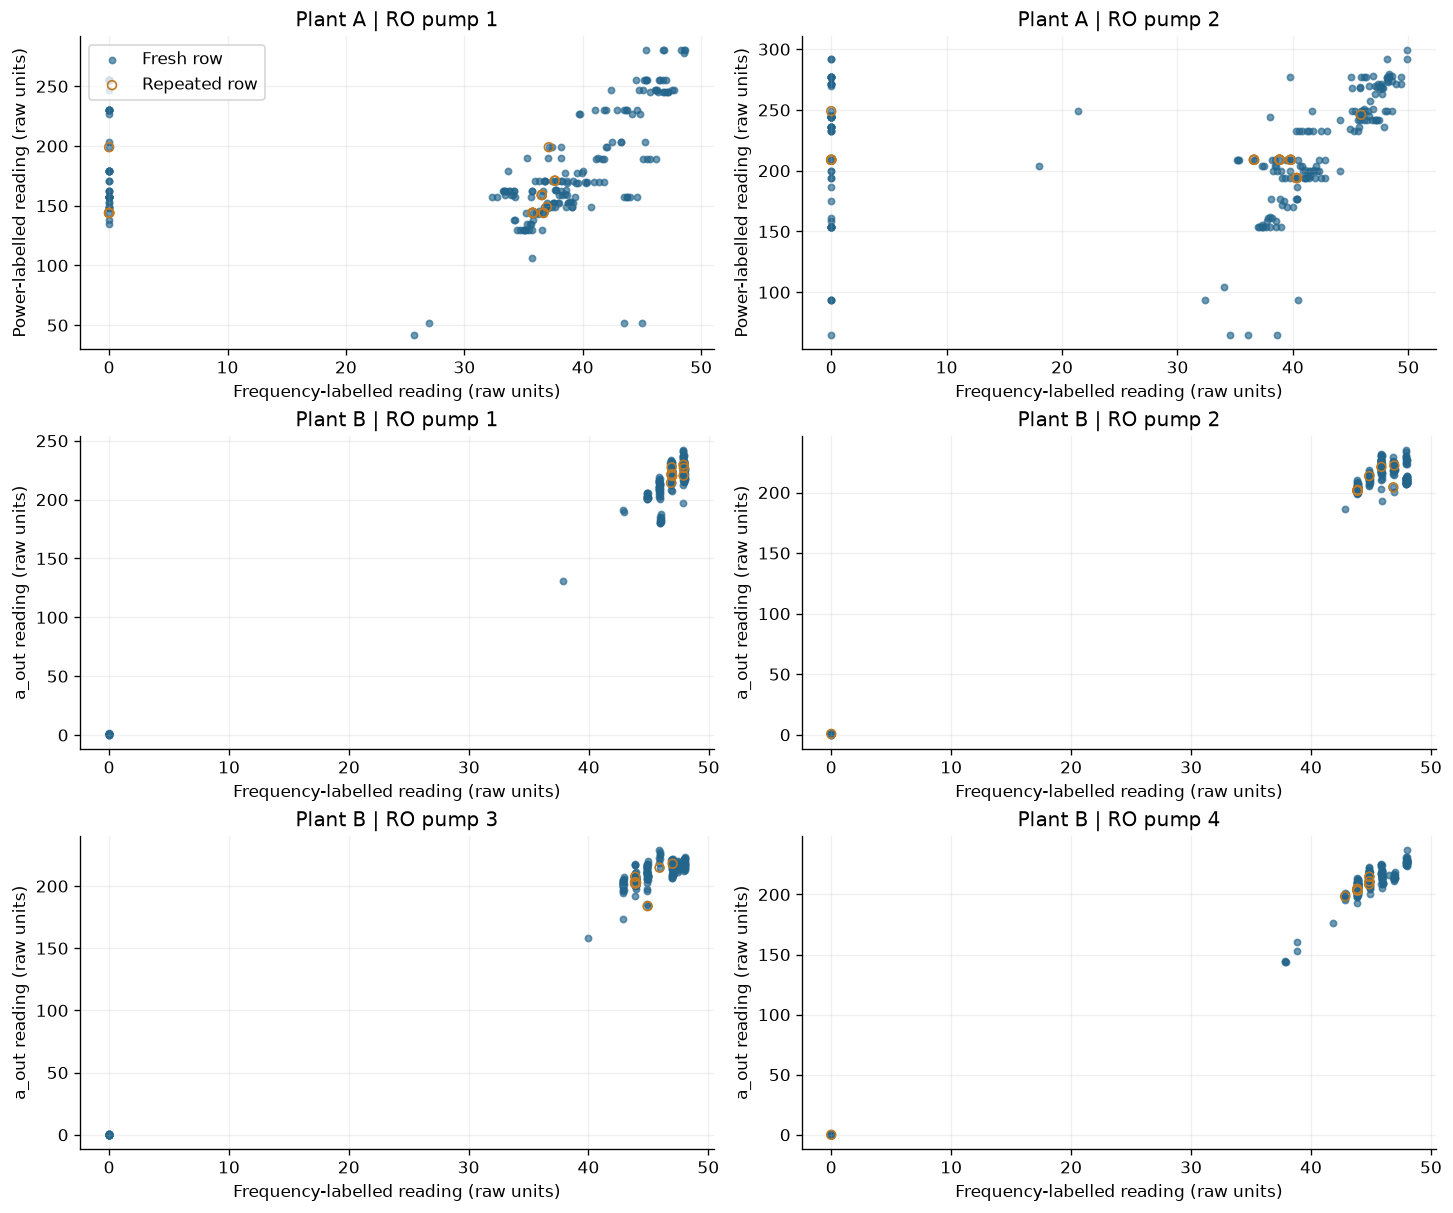

In [9]:
pumps = []
for plant, count in [('Plant A', 2), ('Plant B', 4)]:
    for i in range(1, count + 1):
        pumps.append({'Plant': plant, 'Pump': f'RO pump {i}',
                      'Frequency': f'{i}_rohigh_pressure_pump_frequency_feedback_o' if plant == 'Plant A' else f'c_m_ro{i}_high_pressure_pump_fre_out',
                      'Response': f'zz_{i}_rohigh_pressure_pump_power' if plant == 'Plant A' else f'c_m_ro{i}_high_pressure_pump_a_out',
                      'Response label': 'Power-labelled reading' if plant == 'Plant A' else 'a_out reading'})
regime_rows = []
for pump in pumps:
    frame = equipment[pump['Plant']]
    frequency, response = frame[pump['Frequency']], frame[pump['Response']]
    zero = frequency.eq(0)
    fresh_active = frequency.gt(0) & ~repeat_masks[pump['Plant']]
    regime_rows.append({'Plant': pump['Plant'], 'Pump': pump['Pump'], 'Zero-frequency days': int(zero.sum()),
                        'Positive response on zero-frequency days': int((zero & response.gt(0)).sum()),
                        'Median response at zero frequency': response[zero].median(),
                        'Fresh positive-frequency paired days': int((fresh_active & response.notna()).sum()),
                        'Pearson correlation, fresh positive-frequency pairs': frame.loc[fresh_active, [pump['Frequency'], pump['Response']]].corr().iloc[0, 1]})
regime_summary = pd.DataFrame(regime_rows)
display(regime_summary)
fig, axes = plt.subplots(3, 2, figsize=(12, 10), layout='constrained')
for ax, pump in zip(axes.flat, pumps):
    frame = equipment[pump['Plant']]; fresh = ~repeat_masks[pump['Plant']]
    ax.scatter(frame.loc[fresh, pump['Frequency']], frame.loc[fresh, pump['Response']], s=14, alpha=.65, color='#24658c', label='Fresh row')
    ax.scatter(frame.loc[~fresh, pump['Frequency']], frame.loc[~fresh, pump['Response']], s=28, facecolors='none', edgecolors='#bd7924', label='Repeated row')
    ax.set(title=f"{pump['Plant']} | {pump['Pump']}", xlabel='Frequency-labelled reading (raw units)', ylabel=pump['Response label'] + ' (raw units)')
axes.flat[0].legend(loc='upper left'); plt.show()

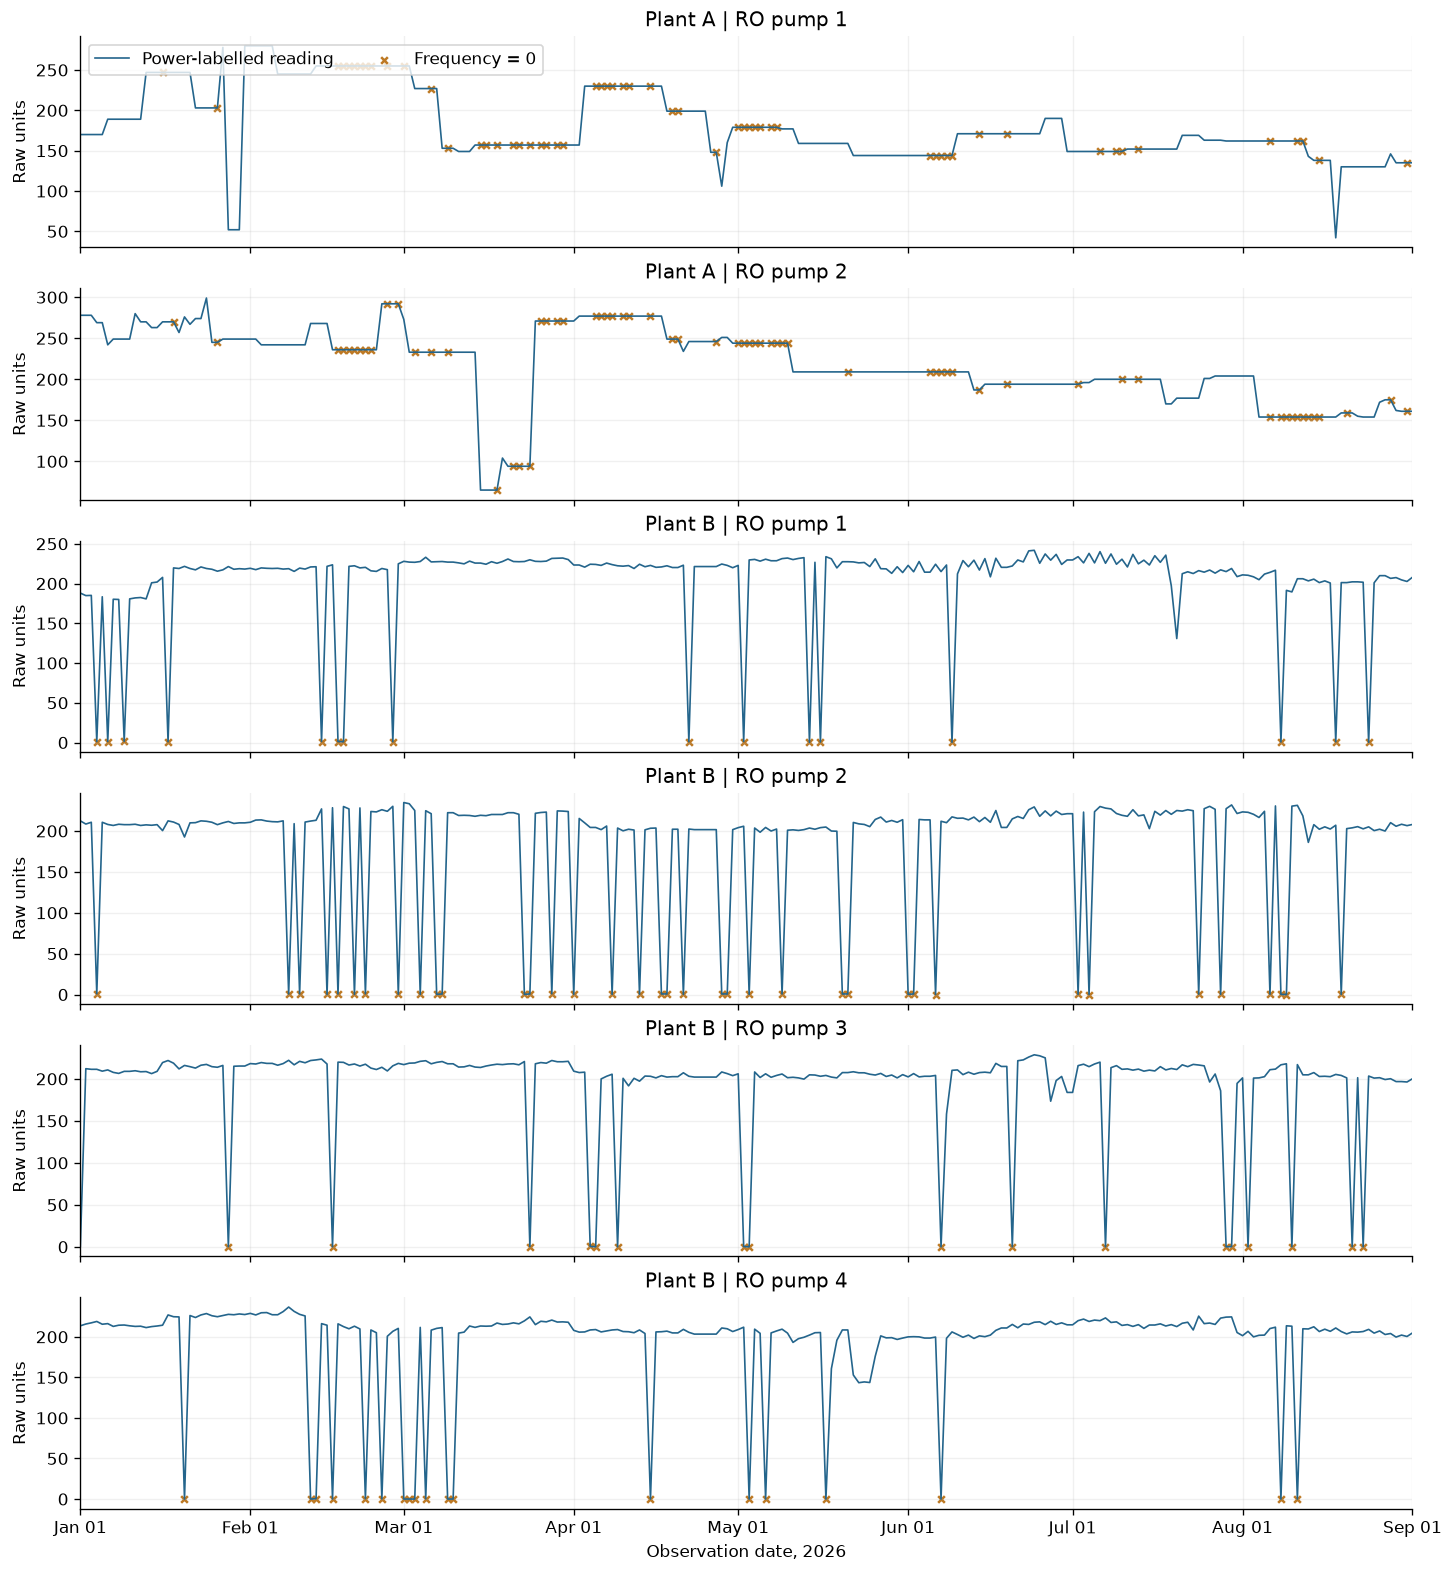

In [10]:
fig, axes = plt.subplots(6, 1, figsize=(12, 13), sharex=True, layout='constrained')
for ax, pump in zip(axes, pumps):
    frame = equipment[pump['Plant']]; response = frame[pump['Response']]
    ax.plot(frame.index, response, linewidth=1, label=pump['Response label'])
    zero = frame[pump['Frequency']].eq(0)
    ax.scatter(frame.index[zero], response[zero], s=16, marker='x', color='#bd7924', label='Frequency = 0')
    ax.set(title=f"{pump['Plant']} | {pump['Pump']}", ylabel='Raw units', xlim=(frame.index.min(), frame.index.max()))
axes[0].legend(loc='upper left', ncols=2)
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
axes[-1].set_xlabel('Observation date, 2026'); plt.show()

### 7. Supporting Plant B signals
UF flux-labelled tags and other supporting measurements can provide process context, but are not automatically mapped to individual RO pumps. Plot raw values without assigning unconfirmed physical units. Zero values may reflect operating changes or data issues. Long flat runs and abrupt changes need review before inclusion in a model.

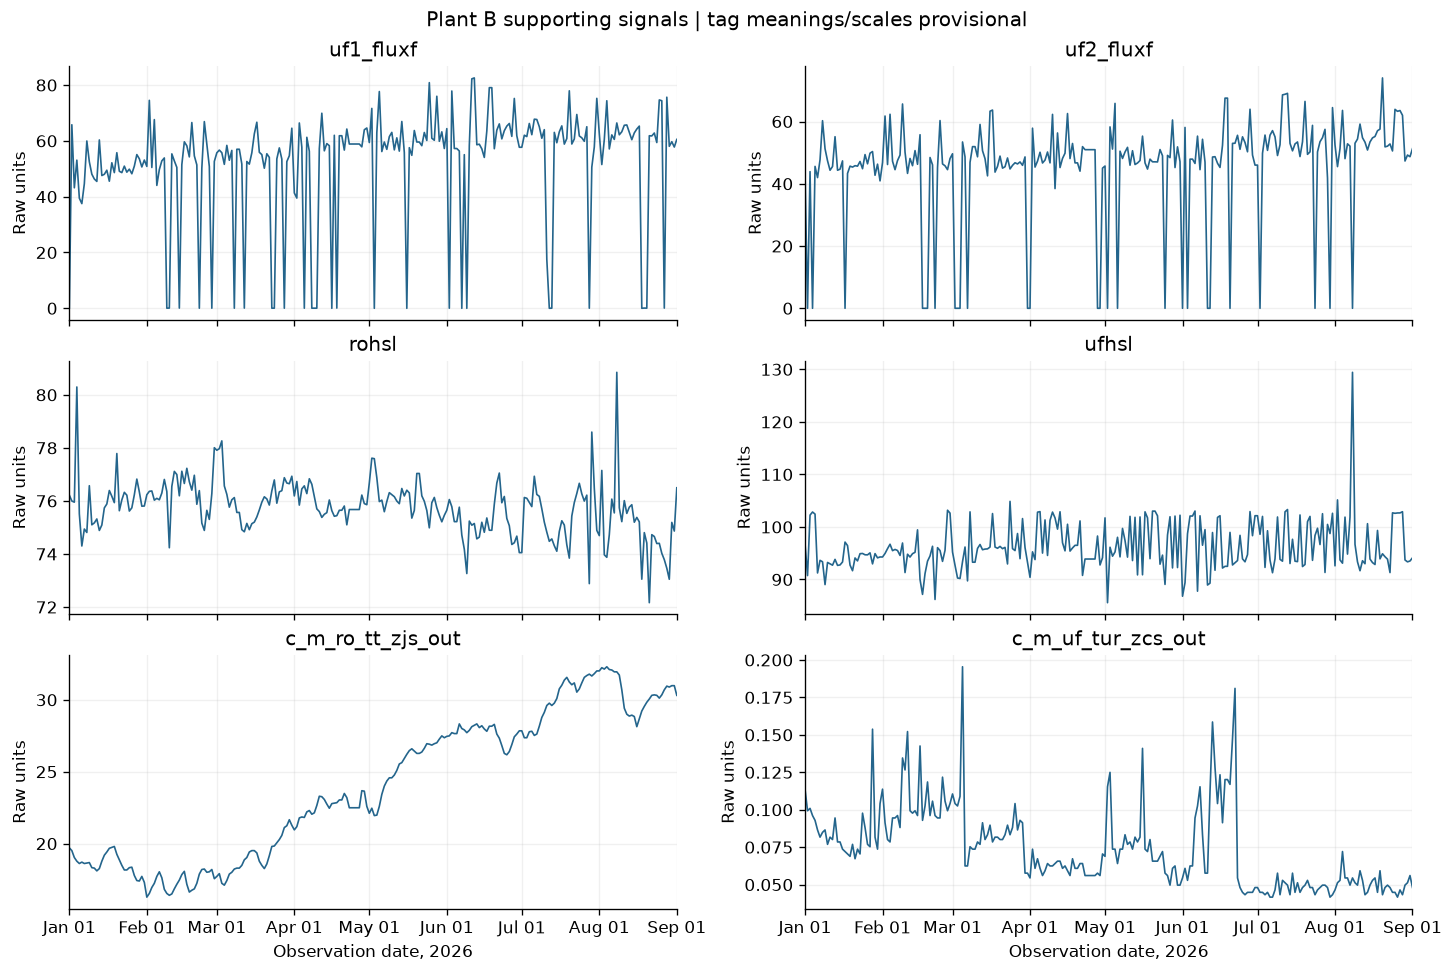

In [11]:
support_fields = ['uf1_fluxf', 'uf2_fluxf', 'rohsl', 'ufhsl', 'c_m_ro_tt_zjs_out', 'c_m_uf_tur_zcs_out']
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, layout='constrained')
for ax, field in zip(axes.flat, support_fields):
    frame = equipment['Plant B']
    ax.plot(frame.index, frame[field], linewidth=1)
    ax.set(title=field, ylabel='Raw units', xlim=(frame.index.min(), frame.index.max()))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
for ax in axes[-1]: ax.set_xlabel('Observation date, 2026')
fig.suptitle('Plant B supporting signals | tag meanings/scales provisional'); plt.show()

### 8. Exploratory chronological alert screen
This tests whether a simple frequency/response relationship is usable, not whether pumps are faulty. Fit a linear response on fresh positive-frequency pairs in the first 90 calendar days. Centre training residuals by their median and scale by 1.4826 × median absolute deviation (MAD). Flag later residual scores above 3.5 in absolute value. Require at least 30 training pairs, at least three distinct frequencies and nonzero residual scale; otherwise mark the screen unavailable. Out-of-training frequency ranges are separate extrapolation flags, not degradation alerts.

The cutoff, 90-day window and linear form are exploratory choices, not calibrated operating limits. No test-period data are used to fit the screen. Repeated full rows and zero-frequency days are excluded. Pair-level repeated values can still remain. Count persistent flags only on adjacent calendar days. Compare cutoffs 3.0, 3.5 and 4.0 to expose sensitivity. Multiple screens increase the chance of false alerts; no accuracy or failure lead time is claimed.

,Plant,Pump,Training pairs,Later pairs,Status,Training through,"Residual scale, raw units",Out-of-range later pairs,Flagged days at 3.5,Consecutive flag days
0,Plant A,RO pump 1,67,105,Exploratory only,2026-03-31,31.231,1,0,0
1,Plant A,RO pump 2,68,96,Exploratory only,2026-03-31,17.649,1,1,0
2,Plant B,RO pump 1,81,137,Exploratory only,2026-03-31,6.052,40,34,17
3,Plant B,RO pump 2,75,123,Exploratory only,2026-03-31,6.361,113,0,0
4,Plant B,RO pump 3,86,131,Exploratory only,2026-03-31,5.064,0,7,1
5,Plant B,RO pump 4,78,138,Exploratory only,2026-03-31,3.853,128,0,0


,Plant,Pump,Cutoff,Eligible later pairs,Flagged days
0,Plant A,RO pump 1,3.000,104,0
1,Plant A,RO pump 1,3.500,104,0
2,Plant A,RO pump 1,4.000,104,0
3,Plant A,RO pump 2,3.000,95,1
4,Plant A,RO pump 2,3.500,95,1
5,Plant A,RO pump 2,4.000,95,0
6,Plant B,RO pump 1,3.000,97,52
7,Plant B,RO pump 1,3.500,97,34
8,Plant B,RO pump 1,4.000,97,22
9,Plant B,RO pump 2,3.000,10,0


,date,Plant,Pump,Frequency,Observed response,Expected response,Residual score,In training frequency range,Flag,Consecutive flag
238,2026-05-17,Plant B,RO pump 1,46.844,233.771,201.028,5.410,True,True,False
236,2026-05-13,Plant B,RO pump 1,46.860,232.554,201.329,5.159,True,True,True
246,2026-05-26,Plant B,RO pump 1,46.796,231.093,200.125,5.117,True,True,False
235,2026-05-12,Plant B,RO pump 1,46.860,231.580,201.329,4.998,True,True,True
239,2026-05-18,Plant B,RO pump 1,46.860,231.093,201.329,4.918,True,True,True
233,2026-05-10,Plant B,RO pump 1,46.924,232.067,202.534,4.880,True,True,True
227,2026-05-04,Plant B,RO pump 1,46.860,230.362,201.329,4.797,True,True,True
229,2026-05-06,Plant B,RO pump 1,46.876,230.606,201.630,4.788,True,True,True
516,2026-06-08,Plant B,RO pump 3,39.939,158.039,182.148,-4.761,True,True,False
232,2026-05-09,Plant B,RO pump 1,46.940,231.336,202.835,4.709,True,True,True


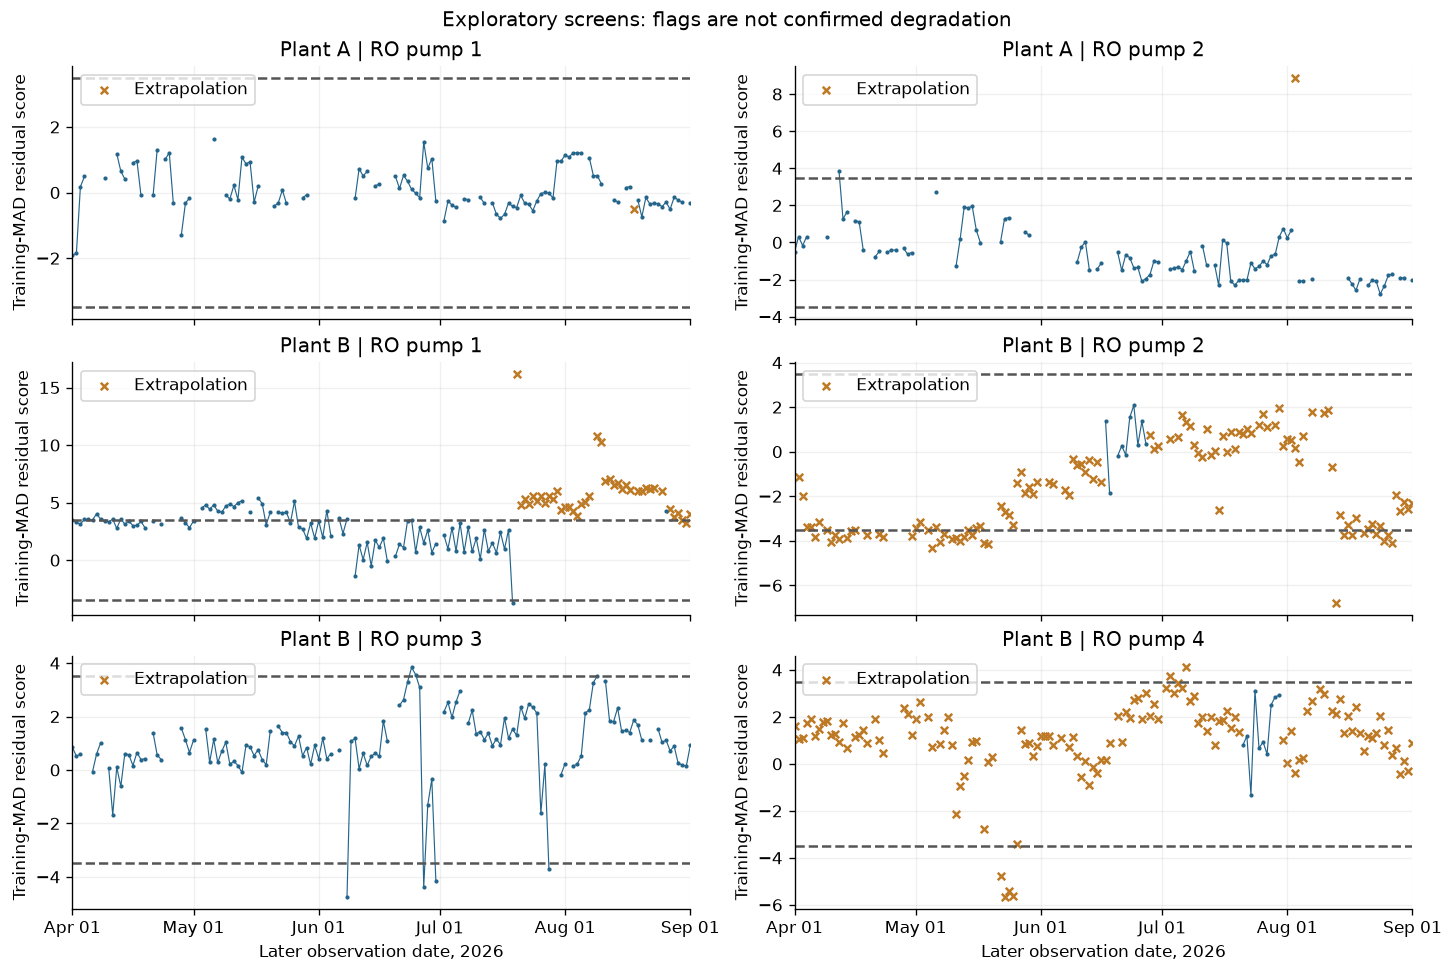

In [12]:
def residual_scale(values):
    center = np.median(values)
    return center, 1.4826 * np.median(np.abs(values - center))

assert residual_scale(np.array([1., 1., 1.])) == (1., 0.)
assert np.isclose(residual_scale(np.array([-1., 0., 1.]))[1], 1.4826)

screen_rows, score_tables, sensitivity_rows = [], [], []
pump_references = {}
for pump in pumps:
    frame = equipment[pump['Plant']]
    pair = frame[[pump['Frequency'], pump['Response']]].dropna()
    pair = pair.loc[pair[pump['Frequency']].gt(0) & ~repeat_masks[pump['Plant']].reindex(pair.index)]
    split = frame.index.min() + pd.Timedelta(days=90)
    train, test = pair.loc[pair.index < split], pair.loc[pair.index >= split]
    row = {'Plant': pump['Plant'], 'Pump': pump['Pump'], 'Training pairs': len(train), 'Later pairs': len(test)}
    if len(train) < 30 or train[pump['Frequency']].nunique() < 3:
        screen_rows.append({**row, 'Status': 'Unavailable: insufficient training variation/pairs'})
        continue
    matrix = np.column_stack([np.ones(len(train)), train[pump['Frequency']]])
    coefficients = np.linalg.lstsq(matrix, train[pump['Response']], rcond=None)[0]
    center, scale = residual_scale(train[pump['Response']].to_numpy() - matrix @ coefficients)
    if not np.isfinite(scale) or scale <= 0:
        screen_rows.append({**row, 'Status': 'Unavailable: zero/invalid residual MAD'})
        continue
    pump_references[(pump['Plant'], pump['Pump'])] = {
        'Intercept': coefficients[0], 'Slope': coefficients[1], 'Residual center': center, 'Residual scale': scale,
        'Frequency minimum': train[pump['Frequency']].min(), 'Frequency maximum': train[pump['Frequency']].max(),
        'Training start': frame.index.min(), 'Training end': split - pd.Timedelta(days=1), 'Training pairs': len(train),
        'Training scores': pd.Series((train[pump['Response']].to_numpy() - matrix @ coefficients - center) / scale, index=train.index),
    }
    scores = pd.DataFrame(index=test.index)
    scores['Plant'], scores['Pump'] = pump['Plant'], pump['Pump']
    scores['Frequency'] = test[pump['Frequency']]
    scores['Observed response'] = test[pump['Response']]
    scores['Expected response'] = coefficients[0] + coefficients[1] * scores['Frequency'] + center
    scores['Residual score'] = (scores['Observed response'] - scores['Expected response']) / scale
    scores['In training frequency range'] = scores.Frequency.between(train[pump['Frequency']].min(), train[pump['Frequency']].max())
    scores['Flag'] = scores['Residual score'].abs().gt(3.5) & scores['In training frequency range']
    adjacent = scores.index.to_series().diff().eq(pd.Timedelta(days=1))
    scores['Consecutive flag'] = scores.Flag & scores.Flag.shift(fill_value=False) & adjacent
    score_tables.append(scores.reset_index())
    eligible = scores['In training frequency range']
    for threshold in [3.0, 3.5, 4.0]:
        sensitivity_rows.append({'Plant': pump['Plant'], 'Pump': pump['Pump'], 'Cutoff': threshold,
                                 'Eligible later pairs': int(eligible.sum()),
                                 'Flagged days': int((scores['Residual score'].abs().gt(threshold) & eligible).sum())})
    screen_rows.append({**row, 'Status': 'Exploratory only', 'Training through': (split - pd.Timedelta(days=1)).date(),
                        'Residual scale, raw units': scale, 'Out-of-range later pairs': int((~eligible).sum()),
                        'Flagged days at 3.5': int(scores.Flag.sum()), 'Consecutive flag days': int(scores['Consecutive flag'].sum())})
screen_summary = pd.DataFrame(screen_rows)
scores = pd.concat(score_tables, ignore_index=True) if score_tables else pd.DataFrame()
display(screen_summary)
display(pd.DataFrame(sensitivity_rows))
if not scores.empty:
    display(scores.loc[scores.Flag].sort_values('Residual score', key=lambda values: values.abs(), ascending=False).head(12))
    fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, layout='constrained')
    for ax, pump in zip(axes.flat, pumps):
        subset = scores.loc[scores.Plant.eq(pump['Plant']) & scores.Pump.eq(pump['Pump'])]
        valid = subset.loc[subset['In training frequency range']]
        daily_scores = valid.set_index('date')['Residual score'].reindex(pd.date_range('2026-04-01', '2026-09-01'))
        ax.plot(daily_scores.index, daily_scores, marker='.', markersize=3, linewidth=.7)
        ax.scatter(subset.loc[~subset['In training frequency range'], 'date'], subset.loc[~subset['In training frequency range'], 'Residual score'], marker='x', color='#bd7924', s=20, label='Extrapolation')
        ax.axhline(3.5, linestyle='--', color='#555555'); ax.axhline(-3.5, linestyle='--', color='#555555')
        ax.set(title=f"{pump['Plant']} | {pump['Pump']}", ylabel='Training-MAD residual score', xlim=(pd.Timestamp('2026-04-01'), pd.Timestamp('2026-09-01')))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
        ax.legend(loc='upper left')
    for ax in axes[-1]: ax.set_xlabel('Later observation date, 2026')
    fig.suptitle('Exploratory screens: flags are not confirmed degradation'); plt.show()

### 9. Production and water-quality context: preserve initial-review checks
Keep the initial notebook's coverage/joins, missingness, energy/recovery reconciliation and repeated-volume checks. Context covers July–August only. A date match adds context, not a causal explanation. Use a date-only merge per selected plant to avoid multiplying rows; never substitute a performance measure for a missing equipment signal.

In [13]:
join_rows = []
for plant, frame in equipment.items():
    subset = performance.loc[performance.plant.eq(plant)]
    joined = subset[['date']].merge(frame.reset_index()[['date']], on='date', how='left', validate='one_to_one', indicator=True)
    join_rows.append({'Plant': plant, 'Performance days': len(subset), 'Matched equipment days': int(joined['_merge'].eq('both').sum())})
display(pd.DataFrame(join_rows))
fields = ['daily_electricity_kwh', 'effluent_volume_m3', 'effluent_ph', 'influent_conductivity_us_cm', 'effluent_conductivity_us_cm'] + [field for field in performance if field.startswith('actual_')]
missing_rows = []
for plant, frame in performance.groupby('plant'):
    for field in fields:
        missing_rows.append({'Plant': plant, 'Field': field, 'Populated days': int(frame[field].notna().sum()),
                             'Total days': len(frame), 'Missing %': 100 * frame[field].isna().mean()})
display(pd.DataFrame(missing_rows))

,Plant,Performance days,Matched equipment days
0,Plant A,62,62
1,Plant B,62,62


,Plant,Field,Populated days,Total days,Missing %
0,Plant A,daily_electricity_kwh,62,62,0.000
1,Plant A,effluent_volume_m3,62,62,0.000
2,Plant A,effluent_ph,62,62,0.000
3,Plant A,influent_conductivity_us_cm,56,62,9.677
4,Plant A,effluent_conductivity_us_cm,54,62,12.903
5,Plant A,actual_antiscalant_dose_reported,2,62,96.774
6,Plant A,actual_naoh_dose_reported,2,62,96.774
7,Plant A,actual_nonoxidizing_biocide_dose_reported,2,62,96.774
8,Plant A,actual_reducing_agent_dose_reported,2,62,96.774
9,Plant A,actual_sdbs_dose_reported,2,62,96.774


,Plant,SEC compared days,SEC mismatches,Recovery compared days,Recovery mismatches,Unique reported recovery,"Effluent equals supply, all days","Effluent equals customer, all days"
0,Plant A,62,0,62,0,1,True,True
1,Plant B,62,0,62,8,55,False,False


,plant,date,reported_recovery_rate,Calculated_recovery
0,Plant B,2026-07-28,0.750,0.756
1,Plant B,2026-07-29,0.750,0.760
2,Plant B,2026-07-30,0.750,0.749
3,Plant B,2026-07-31,0.750,0.745
4,Plant B,2026-08-28,0.750,0.731
5,Plant B,2026-08-29,0.750,0.740
6,Plant B,2026-08-30,0.750,0.749
7,Plant B,2026-08-31,0.750,0.761


Plant A max |influent - effluent / 0.75|: 3.637978807091713e-12


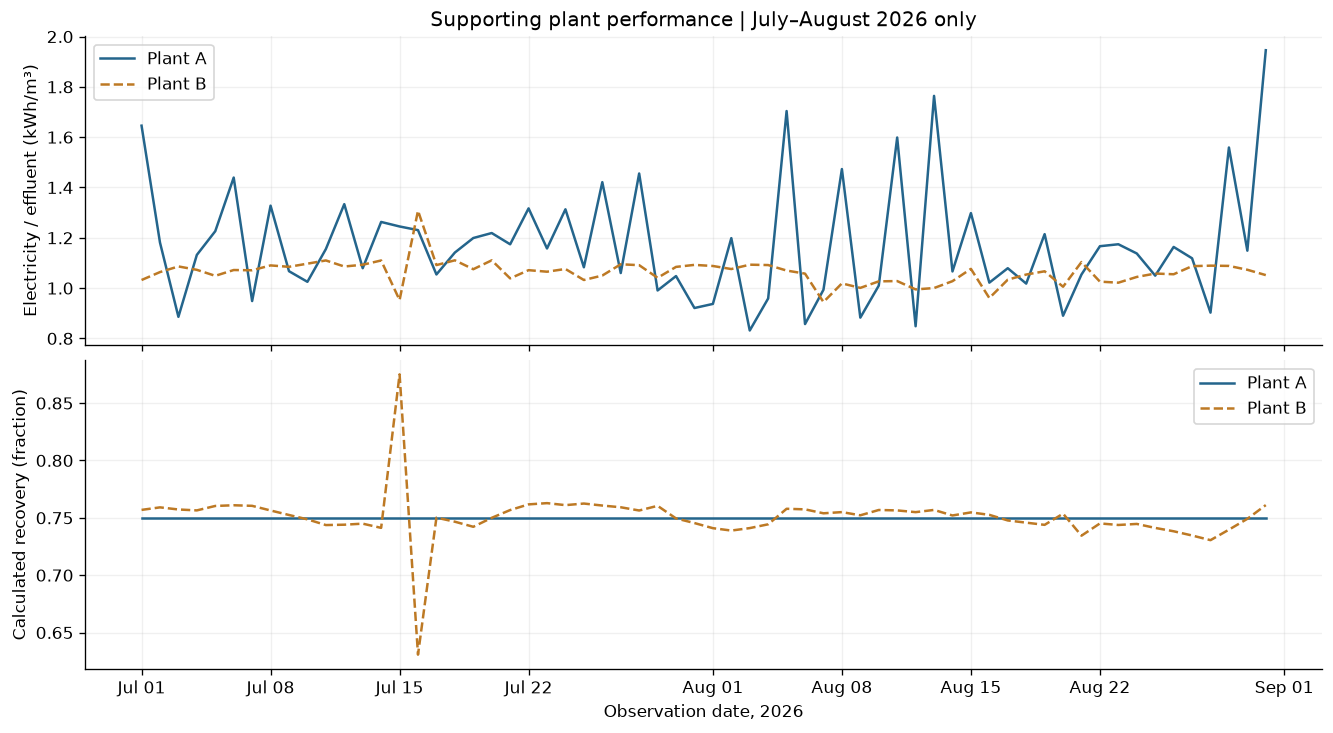

In [14]:
ratio_rows, recovery_events = [], []
for plant, frame in performance.groupby('plant'):
    sec = frame.daily_electricity_kwh.div(frame.effluent_volume_m3.where(frame.effluent_volume_m3.gt(0)))
    recovery = frame.effluent_volume_m3.div(frame.influent_volume_m3.where(frame.influent_volume_m3.gt(0)))
    valid_sec = sec.notna() & frame.reported_specific_energy_kwh_m3.notna()
    valid_recovery = recovery.notna() & frame.reported_recovery_rate.notna()
    sec_bad = valid_sec & ~np.isclose(sec, frame.reported_specific_energy_kwh_m3, rtol=1e-5, atol=1e-8)
    recovery_bad = valid_recovery & ~np.isclose(recovery, frame.reported_recovery_rate, rtol=1e-5, atol=1e-8)
    ratio_rows.append({'Plant': plant, 'SEC compared days': int(valid_sec.sum()), 'SEC mismatches': int(sec_bad.sum()),
                       'Recovery compared days': int(valid_recovery.sum()), 'Recovery mismatches': int(recovery_bad.sum()),
                       'Unique reported recovery': frame.reported_recovery_rate.nunique(),
                       'Effluent equals supply, all days': frame.effluent_volume_m3.equals(frame.reclaimed_supply_volume_m3),
                       'Effluent equals customer, all days': frame.effluent_volume_m3.equals(frame.customer_end_volume_m3)})
    recovery_events.append(frame.loc[recovery_bad, ['plant', 'date', 'reported_recovery_rate']].assign(Calculated_recovery=recovery[recovery_bad]))
display(pd.DataFrame(ratio_rows))
display(pd.concat(recovery_events, ignore_index=True))
a = performance.loc[performance.plant.eq('Plant A')]
print('Plant A max |influent - effluent / 0.75|:', (a.influent_volume_m3 - a.effluent_volume_m3 / .75).abs().max())
fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, layout='constrained')
for plant, frame in performance.groupby('plant'):
    axes[0].plot(frame.date, frame.daily_electricity_kwh / frame.effluent_volume_m3.where(frame.effluent_volume_m3.gt(0)), label=plant, linestyle='-' if plant == 'Plant A' else '--')
    axes[1].plot(frame.date, frame.effluent_volume_m3 / frame.influent_volume_m3.where(frame.influent_volume_m3.gt(0)), label=plant, linestyle='-' if plant == 'Plant A' else '--')
axes[0].set(title='Supporting plant performance | July–August 2026 only', ylabel='Electricity / effluent (kWh/m³)')
axes[1].set(ylabel='Calculated recovery (fraction)', xlabel='Observation date, 2026')
axes[0].legend(); axes[1].legend(); axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%b %d')); plt.show()

**Context interpretation:** all 62 performance dates per plant match equipment dates. Electricity and treated-water volumes are populated throughout the overlap. Arithmetic energy ratios reconcile, but linked/repeated volume columns are not independent evidence. Recovery disagreements and chemical missingness remain unresolved reference-data questions. We have not established a causal link between any pump alert and plant-level inefficiency.

## Takeaways

### What is ready to build
- A six-pump investigation view with signal trends, missingness, full-row repeat flags and counter-decrease events.
- Separate Plant A and Plant B baselines, with raw-unit labels and explicit unavailable states.
- Candidate change/relationship screens whose evidence and exclusions are visible. The chronological screen above is a feasibility probe; high flag rates or unstable relationships mean it needs redesign, not that many pumps are faulty.
- Plant-level electricity, recovery and quality context during July–August only.

### What needs caution
- Plant A's 183-day runtime flatness, counter decreases and frequency/power inconsistency make operating-state and consumption interpretations unreliable without clarification.
- Plant B's longer flat segments and ten full-row repeats need data-quality context even when frequency/response patterns look plausible.
- The simple early-period screen has poor coverage for Plant B Pumps 2 and 4 (ten in-range later pairs each), while Pump 1 flags 34/97 in-range pairs at cutoff 3.5 and is sensitive to the chosen threshold (52 at 3.0; 22 at 4.0). Review regime changes and baseline drift before deciding on a pump alert model.
- Temperature, vibration-like and UF tags can be explored, but the supplied dictionary does not validate their specific physical meanings, units or mappings. Do not silently rename them as confirmed measurements.
- Most chemicals have only two observations per plant; Plant B NaOH has 62. Chemical optimization is not supported broadly.
- Plant A's fixed 75% recovery and linked volumes may reflect calculations; Plant B's eight mismatches need reconciliation. Neither is a confirmed fault.

### Decisions before finalising the product
1. Prioritise explainable equipment changes and data-quality investigation; keep fault type, failure probability and savings claims out of the initial product promise.
2. Choose the actual pump signals after reviewing the inventory and plots, rather than treating every CSV column as a model input.
3. Resolve only questions that affect selected indicators: tag meaning/scales, daily aggregation, ambiguous equipment mappings and counter semantics. Continue relative-pattern analysis meanwhile.
4. Use chronological validation and an alert-review workflow. Demonstrated early-warning lead time needs dated maintenance/failure outcomes that are not supplied.

## Validation
The final cell checks dataset integrity, cleaning edge cases, score splits, source hashes and source-backed findings. The delivered notebook is executed top-to-bottom with outputs and figures saved. Execution does not verify physical sensor meanings or validate fault predictions.

Verified delivery: all 15 code cells completed without errors; eight embedded figures were inspected, along with the HTML-rendered summary, expandable inventory and takeaways. Source hashes were unchanged. The notebook format passed nbformat validation.

In [15]:
# Small boundary checks: missing markers differ from zero; counter decreases stay unavailable.
probe = pd.Series(['NULL', '/', '', '0', 'bad']).replace({'NULL': np.nan, '/': np.nan, '': np.nan})
parsed = pd.to_numeric(probe, errors='coerce')
assert parsed.isna().tolist() == [True, True, True, False, True] and parsed.iloc[3] == 0
probe_counter = pd.Series([10., 12., 2., 5., np.nan, 7.]).diff()
assert probe_counter.mask(probe_counter.lt(0)).isna().tolist() == [True, False, True, False, True, True]
assert all(len(frame) == 244 for frame in equipment.values())
assert len(performance) == 124
assert inventory.groupby('Plant')['Unique values'].apply(lambda values: int(values.gt(1).sum())).to_dict() == {'Plant A': 25, 'Plant B': 60}
assert {plant: int(mask.sum()) for plant, mask in repeat_masks.items()} == {'Plant A': 21, 'Plant B': 10}
assert flat_runs.loc[flat_runs.Field.str.contains('p_[12]_rohigh_pressure_pump_runtime_cumulative', regex=True), 'Longest identical populated run'].eq(183).all()
assert {row['Plant']: row['Recovery mismatches'] for row in ratio_rows} == {'Plant A': 0, 'Plant B': 8}
assert all(frame.where(frame.notna(), 0).ge(0).all().all() for frame in counter_deltas.values())
assert screen_summary.loc[screen_summary.Plant.eq('Plant B') & screen_summary.Pump.eq('RO pump 1'), 'Flagged days at 3.5'].iloc[0] == 34
for table in score_tables:
    assert table.date.min() >= pd.Timestamp('2026-04-01')
    plant = table.Plant.iloc[0]
    assert not repeat_masks[plant].reindex(table.date).any()
    assert not table.loc[~table['In training frequency range'], 'Flag'].any()
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in source_hashes.items())
print('PASS: source files unchanged; key findings, cleaning boundaries and chronological exclusions verified.')

PASS: source files unchanged; key findings, cleaning boundaries and chronological exclusions verified.


## Full daily archive

Stack the equipment histories and join plant-performance context on `plant` and `date`. This full archive retains all source signals for audit, not for routine browsing. Run All to regenerate `output/plant_daily_full.csv` and its matching dictionary. Missing markers are normalized, rates remain fractions, suspicious readings remain untouched, and source units are provisional. The focused table in the next section is the main dataset.


In [16]:
# Reuse the audited data; do not maintain a second cleaning implementation.
assert not parse_audit[['Unparsed values', 'Infinite values']].to_numpy().any(), 'Resolve invalid numeric readings before export'
equipment_daily = pd.concat([data[plant].assign(plant=plant) for plant in equipment], ignore_index=True)
keys = ['plant', 'date']
assert not (set(equipment_daily) & set(performance)) - set(keys), 'Resolve overlapping signal names before joining'
assert not equipment_daily.duplicated(keys).any()
context_keys = performance[keys].merge(equipment_daily[keys], on=keys, how='left', validate='one_to_one', indicator=True)
assert context_keys['_merge'].eq('both').all(), 'Performance dates without equipment must be resolved before export'
unified_daily = equipment_daily.merge(performance, on=keys, how='left', validate='one_to_one')
unified_daily = unified_daily[keys + [field for field in unified_daily if field not in keys]].sort_values(keys).reset_index(drop=True)
assert len(unified_daily) == sum(len(frame) for frame in equipment.values())

unified_dictionary = dictionary.loc[~dictionary['English column'].isin(keys), ['File', 'English column', 'Interpretation', 'Reported unit', 'Missingness', 'Notes']].copy()
unified_dictionary['Applicable plant'] = unified_dictionary['File'].map({names['Plant A']: 'Plant A', names['Plant B']: 'Plant B', names['Performance']: 'Plant A; Plant B'})
key_definitions = pd.DataFrame([
    {'File': 'All three CSVs', 'English column': 'plant', 'Interpretation': 'Anonymized plant identifier', 'Reported unit': 'text', 'Missingness': f'0/{len(unified_daily)} missing', 'Notes': 'Plant A or Plant B; equipment plant comes from the source filename', 'Applicable plant': 'Plant A; Plant B'},
    {'File': 'All three CSVs', 'English column': 'date', 'Interpretation': 'Daily observation date', 'Reported unit': 'YYYY-MM-DD', 'Missingness': f'0/{len(unified_daily)} missing', 'Notes': 'Normalized ISO date; join together with plant', 'Applicable plant': 'Plant A; Plant B'},
])
unified_dictionary = pd.concat([key_definitions, unified_dictionary], ignore_index=True)
unified_dictionary = unified_dictionary.set_index('English column').loc[list(unified_daily.columns)].reset_index()
assert unified_dictionary['English column'].is_unique
assert set(unified_dictionary['English column']) == set(unified_daily.columns)
assert unified_dictionary['Applicable plant'].notna().all()

export_dir = source_dir.parent / 'output'
export_dir.mkdir(exist_ok=True)
unified_path = export_dir / 'plant_daily_full.csv'
unified_daily.to_csv(unified_path, index=False, date_format='%Y-%m-%d', na_rep='')
unified_dictionary.to_csv(export_dir / 'plant_daily_full_dictionary.csv', index=False)

# Round-trip check protects source readings, including zeros and missing values.
round_trip = pd.read_csv(unified_path, parse_dates=['date'])
pd.testing.assert_frame_equal(round_trip, unified_daily, check_dtype=False)
for plant in equipment:
    restored = round_trip.loc[round_trip.plant.eq(plant)].set_index('date')[equipment[plant].columns]
    pd.testing.assert_frame_equal(restored, equipment[plant], check_dtype=False)
restored_context = round_trip.set_index(keys).loc[pd.MultiIndex.from_frame(performance[keys]), performance.columns.difference(keys)].reset_index()
pd.testing.assert_frame_equal(restored_context[performance.columns], performance, check_dtype=False)
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in source_hashes.items())
print(f'PASS: {len(unified_daily)} unique plant-days, {len(unified_daily.columns)} columns; all equipment and performance readings retained; originals unchanged.')
display(unified_daily[keys + ['daily_electricity_kwh', 'effluent_volume_m3']].groupby('plant').agg({'date': ['min', 'max', 'count'], 'daily_electricity_kwh': 'count', 'effluent_volume_m3': 'count'}))


PASS: 488 unique plant-days, 154 columns; all equipment and performance readings retained; originals unchanged.


date                  daily_electricity_kwh effluent_volume_m3
               min        max count                 count              count
plant                                                                       
Plant A 2026-01-01 2026-09-01   244                    62                 62
Plant B 2026-01-01 2026-09-01   244                    62                 62

## Focused daily dataset: 22 columns

The main `Dataset/plant_daily_unified.csv` keeps only the three signals per pump documented in `HISTORICAL_ANALYSIS.md` (frequency, response, cumulative runtime) plus six plant-level context fields: electricity, effluent volume, reported specific energy, reported recovery, effluent pH and conductivity. One row still represents one plant on one date. The matching `Dataset/plant_daily_unified_dictionary.csv` maps the shorter equipment names to exact source columns.

Plant A power-labelled readings and Plant B `a_out` readings have separate columns. No scaling, imputation or physical-equivalence assumption is introduced. Shared frequency/runtime column names identify signal roles; units and cross-plant comparability remain unconfirmed. Pumps 3–4 are only supplied for Plant B; performance context only covers July–August. Missing coverage stays blank, rates stay fractions. Cumulative runtime is a counter, not a daily total, and may be stale or reset. Empty/constant auxiliary fields, chemical fields and other sensor detail remain available in the originals and full archive rather than the main table. These are feature-selection choices for the pump prototype, not proof that excluded data is unimportant for other uses.


In [17]:
core_daily = unified_daily[keys].copy()
core_sources = {field: [('Plant A; Plant B', field)] for field in keys}
for pump in pumps:
    plant, number = pump['Plant'], pump['Pump'].split()[-1]
    mask = unified_daily.plant.eq(plant)
    runtime = f'p_{number}_rohigh_pressure_pump_runtime_cumulative' if plant == 'Plant A' else f'c_m_ro{number}_high_pressure_pump_runtime_cumulative'
    response_name = 'power_reading' if plant == 'Plant A' else 'a_out'
    mapping = {'frequency': pump['Frequency'], response_name: pump['Response'], 'runtime_counter': runtime}
    for role, original in mapping.items():
        field = f'pump{number}_{role}'
        core_daily.loc[mask, field] = unified_daily.loc[mask, original]
        core_sources.setdefault(field, []).append((plant, original))
        pd.testing.assert_series_equal(core_daily.loc[mask, field], unified_daily.loc[mask, original], check_names=False, check_dtype=False)
context_fields = ['daily_electricity_kwh', 'effluent_volume_m3', 'reported_specific_energy_kwh_m3', 'reported_recovery_rate', 'effluent_ph', 'effluent_conductivity_us_cm']
for field in context_fields:
    core_daily[field] = unified_daily[field]
    core_sources[field] = [('Plant A; Plant B', field)]
pump_fields = [f'pump{number}_{role}' for number in range(1, 5) for role in ['frequency', 'power_reading', 'a_out', 'runtime_counter'] if f'pump{number}_{role}' in core_daily]
core_daily = core_daily[keys + pump_fields + context_fields]
assert core_daily.shape == (len(unified_daily), 22)
assert not core_daily.duplicated(keys).any()
pd.testing.assert_frame_equal(core_daily[keys + context_fields], unified_daily[keys + context_fields])

field_definitions = unified_dictionary.set_index('English column')
core_dictionary_rows = []
for field in core_daily:
    origins = core_sources[field]
    definitions = field_definitions.loc[[original for _, original in origins]]
    purpose = 'Daily plant context' if field in context_fields else 'Daily key' if field in keys else 'Pump reading; provisional meaning and units'
    core_dictionary_rows.append({'column': field, 'purpose': purpose,
        'source_mapping': '; '.join(f'{plant}: {original}' for plant, original in origins),
        'reported_unit': '; '.join(definitions['Reported unit'].drop_duplicates()),
        'notes': '; '.join(definitions['Notes'].drop_duplicates())})
core_dictionary = pd.DataFrame(core_dictionary_rows)
assert core_dictionary.column.tolist() == core_daily.columns.tolist()

core_path = source_dir / 'plant_daily_unified.csv'
core_daily.to_csv(core_path, index=False, date_format='%Y-%m-%d', na_rep='')
core_dictionary.to_csv(source_dir / 'plant_daily_unified_dictionary.csv', index=False)
pd.testing.assert_frame_equal(pd.read_csv(core_path, parse_dates=['date']), core_daily, check_dtype=False)
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in source_hashes.items())
print(f'PASS: focused main dataset has {len(core_daily)} plant-days and 22 columns; source readings and missing coverage preserved.')
print('Full 154-column archive: output/plant_daily_full.csv')
display(core_daily.head(3))


PASS: focused main dataset has 488 plant-days and 22 columns; source readings and missing coverage preserved.
Full 154-column archive: output/plant_daily_full.csv


,plant,date,pump1_frequency,pump1_power_reading,pump1_a_out,pump1_runtime_counter,pump2_frequency,...,pump4_runtime_counter,daily_electricity_kwh,effluent_volume_m3,reported_specific_energy_kwh_m3,reported_recovery_rate,effluent_ph,effluent_conductivity_us_cm
0,Plant A,2026-01-01,40.164,170.000,NaN,988.467,48.365,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Plant A,2026-01-02,40.377,170.000,NaN,988.467,48.557,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Plant A,2026-01-03,40.978,170.000,NaN,988.467,46.973,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Historical operating patterns

This section compares the six pumps with their earlier readings. It also checks plant energy, production, and water quality in July and August.

A common historical pattern is not proof of healthy operation. A review flag is not proof of equipment damage. A new frequency range has no valid comparison with the fixed reference.

The reference uses January 1 to March 31, 2026. Later comparisons use April 1 to September 1. Each pump has a separate reference. The rule is an absolute review score greater than 3.5. Missing readings, zero frequency, full-reading repeats, and frequency outside the training range prevent comparison. See `HISTORICAL_ANALYSIS.md` for the calculations.

The energy review uses all 62 performance dates per plant. Its distribution limits describe this supplied period. They do not provide an early warning or an operating limit.


In [18]:
historical_dir = source_dir.parent / 'output' / 'historical'
historical_dir.mkdir(parents=True, exist_ok=True)
historical_rows, period_rows, episode_rows, daily_tables = [], [], [], []
training_ranges = {}
periods = {'Jan-Mar': ('2026-01-01', '2026-03-31'), 'Apr-Jun': ('2026-04-01', '2026-06-30'), 'Jul-Aug': ('2026-07-01', '2026-08-31')}
for pump in pumps:
    plant, label = pump['Plant'], pump['Pump']
    frame = equipment[plant]
    split = frame.index.min() + pd.Timedelta(days=90)
    fresh = frame.loc[frame[pump['Frequency']].gt(0) & ~repeat_masks[plant], [pump['Frequency'], pump['Response']]].dropna()
    train = fresh.loc[fresh.index < split]
    training_ranges[(plant, label)] = (train.iloc[:, 0].min(), train.iloc[:, 0].max())
    later = frame.loc[frame.index >= split]
    compared = scores.loc[scores.Plant.eq(plant) & scores.Pump.eq(label)].sort_values('date').set_index('date')
    status = pd.Series('Comparison unavailable', index=later.index)
    status.loc[later[pump['Frequency']].le(0)] = 'Zero frequency'
    status.loc[repeat_masks[plant].reindex(later.index)] = 'Repeated readings'
    status.loc[compared.index] = 'Outside reference frequency range'
    eligible = compared['In training frequency range']
    status.loc[compared.index[eligible & ~compared.Flag]] = 'Reference-consistent'
    status.loc[compared.index[compared.Flag]] = 'Review flag'
    counts = status.value_counts()
    assert len(status) == len(later) and counts.sum() == len(later)
    assert counts.get('Review flag', 0) == int(compared.Flag.sum())
    assert not compared.loc[~eligible, 'Flag'].any()
    historical_rows.append({'Plant': plant, 'Pump': label, 'Training pairs': len(train), 'Later dates': len(later),
        'Comparable later days': int(eligible.sum()), 'Reference-consistent days': int(counts.get('Reference-consistent', 0)),
        'Review days': int(compared.Flag.sum()), 'Outside reference range': int((~eligible).sum()),
        'Repeated later days': int(counts.get('Repeated readings', 0)), 'Zero-frequency later days': int(counts.get('Zero frequency', 0)),
        'Other unavailable days': int(counts.get('Comparison unavailable', 0)),
        'Fresh frequency-response correlation': fresh.corr().iloc[0, 1]})
    daily = pd.DataFrame({'Plant': plant, 'Pump': label, 'Status': status,
        'Frequency': later[pump['Frequency']], 'Observed response': later[pump['Response']],
        'Expected response': compared['Expected response'].where(eligible), 'Review score': compared['Residual score'].where(eligible)}, index=later.index)
    daily_tables.append(daily.reset_index())
    for period, (start, end) in periods.items():
        part = fresh.loc[start:end]
        period_rows.append({'Plant': plant, 'Pump': label, 'Period': period, 'Fresh pairs': len(part),
            'Median frequency': part.iloc[:, 0].median(), 'Median response': part.iloc[:, 1].median()})
    flagged = compared.loc[compared.Flag].reset_index()
    if not flagged.empty:
        # A date gap or direction change starts a new review period.
        flagged['Period'] = (flagged.date.diff().ne(pd.Timedelta(days=1)) | np.sign(flagged['Residual score']).ne(np.sign(flagged['Residual score'].shift()))).cumsum()
        for _, block in flagged.groupby('Period'):
            relative = (block['Observed response'] / block['Expected response'].where(block['Expected response'].gt(0)) - 1) * 100
            episode_rows.append({'Plant': plant, 'Pump': label, 'Start': block.date.min(), 'End': block.date.max(), 'Days': len(block),
                'Direction': 'Above expected' if block['Residual score'].iloc[0] > 0 else 'Below expected',
                'Median frequency': block.Frequency.median(), 'Median observed response': block['Observed response'].median(),
                'Median expected response': block['Expected response'].median(), 'Median response difference %': relative.median(),
                'Maximum absolute score': block['Residual score'].abs().max()})
historical_summary = pd.DataFrame(historical_rows)
historical_periods = pd.DataFrame(period_rows)
historical_episodes = pd.DataFrame(episode_rows).sort_values(['Days', 'Maximum absolute score'], ascending=False).reset_index(drop=True)
historical_daily = pd.concat(daily_tables, ignore_index=True)
assert historical_episodes.Days.sum() == historical_summary['Review days'].sum()
assert historical_daily.groupby(['Plant', 'Pump']).size().eq(154).all()
assert historical_daily.loc[historical_daily.Status.eq('Outside reference frequency range'), 'Review score'].isna().all()
# Boundary check: a missing date and a change of direction split periods.
probe_dates = pd.Series(pd.to_datetime(['2026-05-03', '2026-05-04', '2026-05-06', '2026-05-07']))
probe_scores = pd.Series([4., 4., -4., 4.])
probe_periods = (probe_dates.diff().ne(pd.Timedelta(days=1)) | np.sign(probe_scores).ne(np.sign(probe_scores.shift()))).cumsum()
assert probe_periods.tolist() == [1, 1, 2, 3]
for filename, table in [('pump_summary.csv', historical_summary), ('pump_periods.csv', historical_periods), ('review_periods.csv', historical_episodes), ('daily_comparisons.csv', historical_daily)]:
    table.to_csv(historical_dir / filename, index=False, date_format='%Y-%m-%d')
display(historical_summary.drop(columns='Fresh frequency-response correlation'))
display(historical_episodes.head(6))


,Plant,Pump,Training pairs,Later dates,Comparable later days,Reference-consistent days,Review days,Outside reference range,Repeated later days,Zero-frequency later days,Other unavailable days
0,Plant A,RO pump 1,67,154,104,104,0,1,21,28,0
1,Plant A,RO pump 2,68,154,95,94,1,1,21,37,0
2,Plant B,RO pump 1,81,154,97,63,34,40,9,8,0
3,Plant B,RO pump 2,75,154,10,10,0,113,9,22,0
4,Plant B,RO pump 3,86,154,131,124,7,0,9,14,0
5,Plant B,RO pump 4,78,154,10,10,0,128,9,7,0


,Plant,Pump,Start,End,Days,Direction,Median frequency,Median observed response,Median expected response,Median response difference %,Maximum absolute score
0,Plant B,RO pump 1,2026-05-03,2026-05-13,11,Above expected,46.892,230.362,201.931,14.052,5.159
1,Plant B,RO pump 1,2026-04-04,2026-04-08,5,Above expected,46.908,224.031,202.232,10.614,4.033
2,Plant B,RO pump 1,2026-05-22,2026-05-24,3,Above expected,46.860,226.466,201.329,12.485,4.175
3,Plant B,RO pump 1,2026-05-17,2026-05-18,2,Above expected,46.852,232.432,201.178,15.536,5.410
4,Plant B,RO pump 3,2026-06-24,2026-06-25,2,Above expected,45.931,228.049,209.304,8.956,3.836
5,Plant B,RO pump 1,2026-05-26,2026-05-26,1,Above expected,46.796,231.093,200.125,15.474,5.117


### Frequency history

Compare each pump with its own earlier readings. The shaded band shows its training frequency range. Zero readings and repeated readings remain visible.


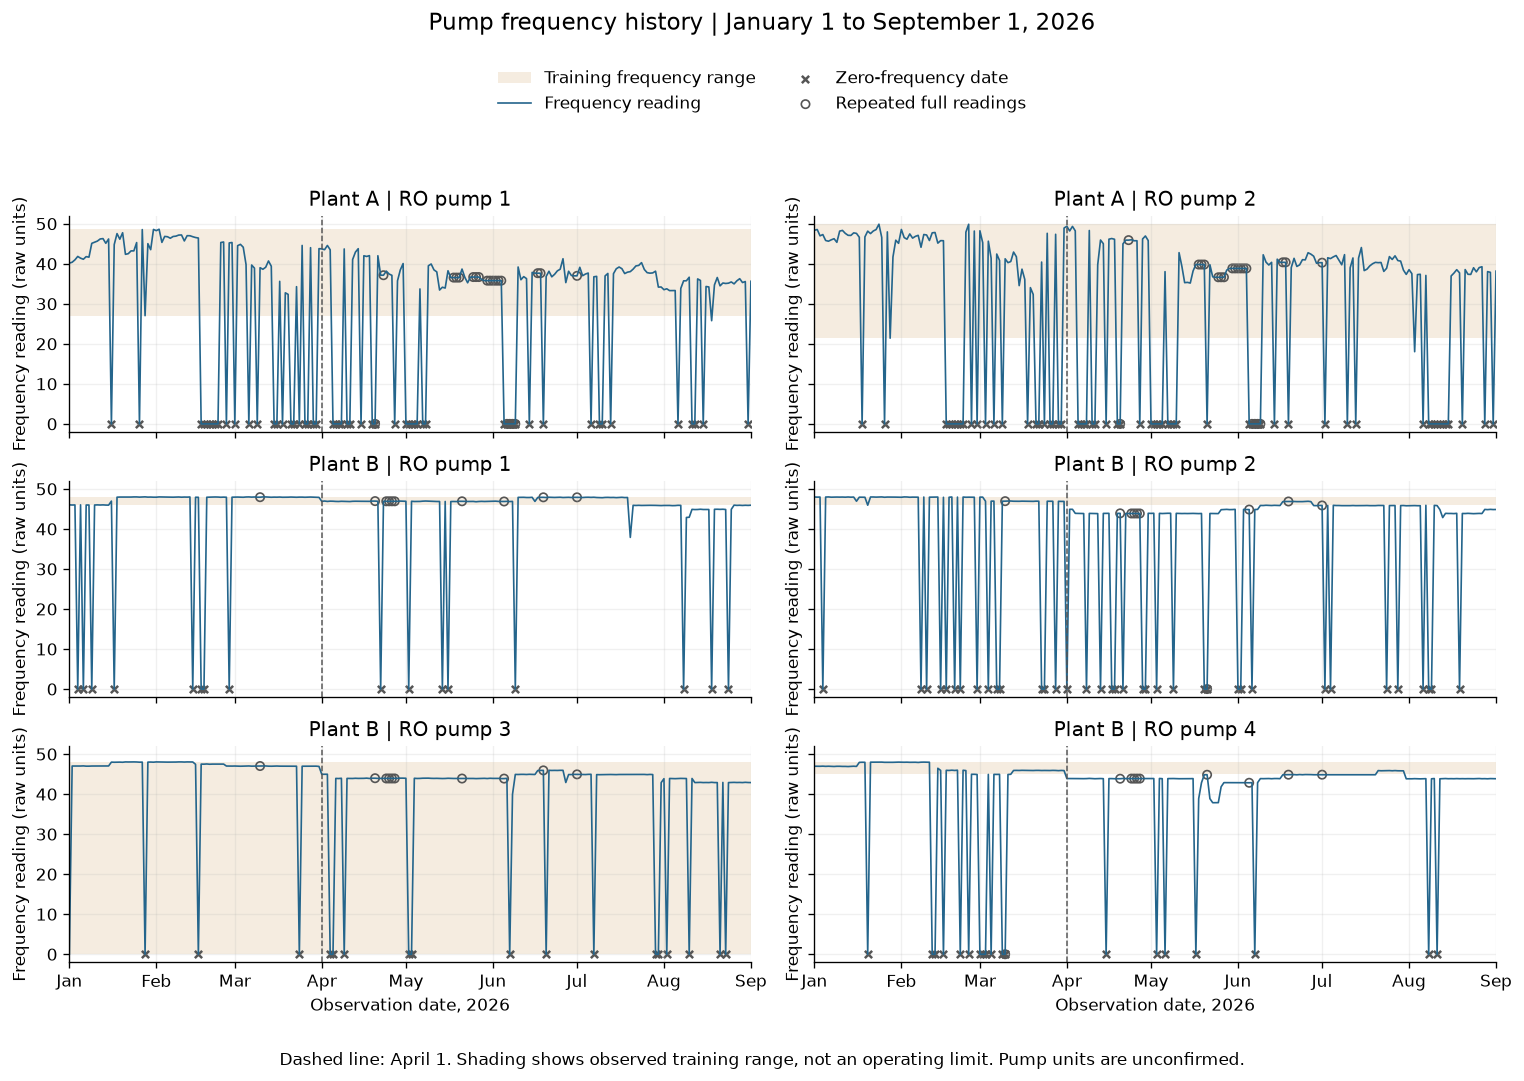

In [19]:
fig, axes = plt.subplots(3, 2, figsize=(12.8, 9), sharex=True, sharey=True)
for ax, pump in zip(axes.flat, pumps):
    plant, label = pump['Plant'], pump['Pump']
    frame = equipment[plant]
    frequency = frame[pump['Frequency']]
    lower, upper = training_ranges[(plant, label)]
    ax.axhspan(lower, upper, facecolor='#bd7924', alpha=.14, label='Training frequency range')
    ax.plot(frame.index, frequency, color='#24658c', linewidth=1, label='Frequency reading')
    zero = frequency.eq(0)
    ax.scatter(frame.index[zero], frequency[zero], color='#555555', marker='x', s=19, label='Zero-frequency date')
    repeated = repeat_masks[plant]
    ax.scatter(frame.index[repeated], frequency[repeated], facecolors='none', edgecolors='#555555', marker='o', s=25, label='Repeated full readings')
    ax.axvline(pd.Timestamp('2026-04-01'), color='#555555', linewidth=.9, linestyle='--')
    ax.set(title=f'{plant} | {label}', ylim=(-2, 52), ylabel='Frequency reading (raw units)')
    ax.set_xlim(pd.Timestamp('2026-01-01'), pd.Timestamp('2026-09-01'))
    ax.set_xticks(pd.date_range('2026-01-01', '2026-09-01', freq='MS'))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
for ax in axes[-1]: ax.set_xlabel('Observation date, 2026')
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .95), ncols=2, frameon=False)
fig.suptitle('Pump frequency history | January 1 to September 1, 2026', y=.99, fontsize=14)
fig.text(.5, .015, 'Dashed line: April 1. Shading shows observed training range, not an operating limit. Pump units are unconfirmed.', ha='center', fontsize=10)
fig.tight_layout(rect=(0, .045, 1, .88))
fig.savefig(historical_dir / 'pump_frequency_history.png', dpi=140, facecolor='white')
plt.show()


### Response review

A gap means that a comparison is unavailable. A flag identifies a difference from the earlier relationship. Counts use comparable later days as the denominator.


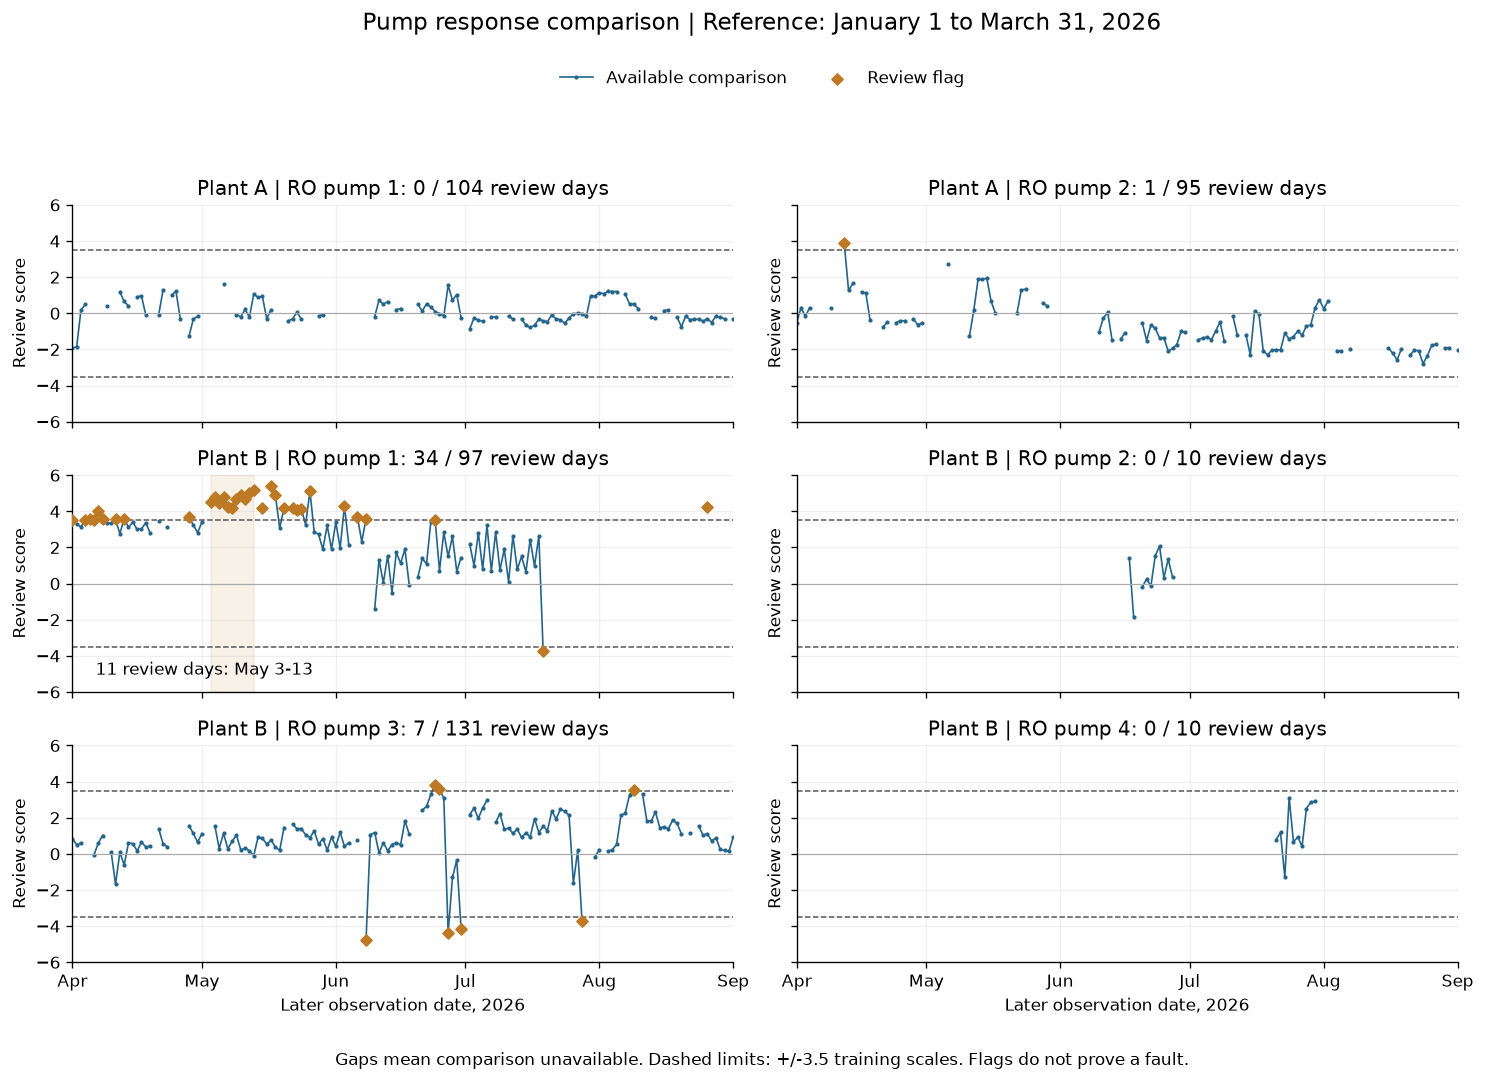

In [20]:
fig, axes = plt.subplots(3, 2, figsize=(12.8, 9), sharex=True, sharey=True)
for ax, pump in zip(axes.flat, pumps):
    plant, label = pump['Plant'], pump['Pump']
    daily = historical_daily.loc[historical_daily.Plant.eq(plant) & historical_daily.Pump.eq(label)].set_index('date')
    line = daily['Review score'].reindex(pd.date_range('2026-04-01', '2026-09-01'))
    ax.plot(line.index, line, color='#24658c', linewidth=1, marker='.', markersize=3, label='Available comparison')
    flagged = daily.Status.eq('Review flag')
    ax.scatter(daily.index[flagged], daily.loc[flagged, 'Review score'], color='#bd7924', marker='D', s=22, zorder=4, label='Review flag')
    for limit in [-3.5, 3.5]: ax.axhline(limit, color='#555555', linewidth=.9, linestyle='--')
    ax.axhline(0, color='#aaaaaa', linewidth=.7)
    summary_row = historical_summary.loc[historical_summary.Plant.eq(plant) & historical_summary.Pump.eq(label)].iloc[0]
    ax.set(title=f"{plant} | {label}: {summary_row['Review days']} / {summary_row['Comparable later days']} review days", ylim=(-6, 6), ylabel='Review score')
    ax.set_xlim(pd.Timestamp('2026-04-01'), pd.Timestamp('2026-09-01'))
    ax.set_xticks(pd.date_range('2026-04-01', '2026-09-01', freq='MS'))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    if plant == 'Plant B' and label == 'RO pump 1':
        ax.axvspan(pd.Timestamp('2026-05-03'), pd.Timestamp('2026-05-13'), color='#bd7924', alpha=.1)
        ax.text(.035, .08, '11 review days: May 3-13', transform=ax.transAxes, fontsize=10)
for ax in axes[-1]: ax.set_xlabel('Later observation date, 2026')
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(.5, .95), ncols=2, frameon=False)
fig.suptitle('Pump response comparison | Reference: January 1 to March 31, 2026', y=.99, fontsize=14)
fig.text(.5, .015, 'Gaps mean comparison unavailable. Dashed limits: +/-3.5 training scales. Flags do not prove a fault.', ha='center', fontsize=10)
fig.tight_layout(rect=(0, .045, .975, .89))
fig.savefig(historical_dir / 'pump_response_comparison.png', dpi=140, facecolor='white')
plt.show()


### Plant energy and production

Calculate each monthly ratio from matching electricity and water totals. Review daily ratios above the upper quartile plus 1.5 times the interquartile range. These retrospective limits are separate from pump flags.


In [21]:
historical_context = performance.copy()
valid_context = historical_context.daily_electricity_kwh.notna() & historical_context.effluent_volume_m3.gt(0)
assert valid_context.all(), 'Keep matching dates for electricity and water volume'
historical_context['Calculated specific energy'] = historical_context.daily_electricity_kwh / historical_context.effluent_volume_m3
historical_context['Month'] = historical_context.date.dt.strftime('%Y-%m')
energy_limits, energy_cases = [], []
for plant, frame in historical_context.groupby('plant'):
    q1, q3 = frame['Calculated specific energy'].quantile([.25, .75])
    limit = q3 + 1.5 * (q3 - q1)
    energy_limits.append({'Plant': plant, 'Lower quartile': q1, 'Upper quartile': q3, 'Upper review limit': limit})
    energy_cases.append(frame.loc[frame['Calculated specific energy'].gt(limit), ['plant', 'date', 'daily_electricity_kwh', 'effluent_volume_m3', 'Calculated specific energy', 'effluent_ph', 'effluent_conductivity_us_cm']].assign(**{'Upper review limit': limit}))
historical_energy_limits = pd.DataFrame(energy_limits).set_index('Plant')
historical_energy_cases = pd.concat(energy_cases, ignore_index=True)
historical_months = historical_context.groupby(['plant', 'Month']).agg(
    Days=('date', 'size'), Electricity_kwh=('daily_electricity_kwh', 'sum'), Water_m3=('effluent_volume_m3', 'sum'),
    Median_ph=('effluent_ph', 'median'), Conductivity_readings=('effluent_conductivity_us_cm', 'count'), Median_conductivity=('effluent_conductivity_us_cm', 'median')).reset_index()
historical_months['Specific energy kwh_m3'] = historical_months.Electricity_kwh / historical_months.Water_m3
monthly_changes = []
for plant, frame in historical_months.groupby('plant'):
    july = frame.loc[frame.Month.eq('2026-07')].iloc[0]
    august = frame.loc[frame.Month.eq('2026-08')].iloc[0]
    energy_ratio = august.Electricity_kwh / july.Electricity_kwh
    water_ratio = august.Water_m3 / july.Water_m3
    sec_ratio = august['Specific energy kwh_m3'] / july['Specific energy kwh_m3']
    assert july.Days == august.Days == 31
    assert np.isclose(sec_ratio, energy_ratio / water_ratio)
    monthly_changes.append({'Plant': plant, 'Electricity change %': 100*(energy_ratio-1), 'Production change %': 100*(water_ratio-1), 'Specific energy change %': 100*(sec_ratio-1)})
historical_changes = pd.DataFrame(monthly_changes)
for filename, table in [('plant_months.csv', historical_months), ('plant_month_changes.csv', historical_changes), ('high_specific_energy_dates.csv', historical_energy_cases), ('specific_energy_review_limits.csv', historical_energy_limits.reset_index())]:
    table.to_csv(historical_dir / filename, index=False, date_format='%Y-%m-%d')
display(historical_months)
display(historical_changes)
display(historical_energy_cases)

# Retrospective ranges describe these records; they are not physical operating limits.
assert np.isfinite(historical_context[['daily_electricity_kwh', 'effluent_volume_m3', 'influent_volume_m3']]).all().all()
assert historical_context.influent_volume_m3.gt(0).all()
assert not historical_context.duplicated(['plant', 'date']).any()
historical_context['Calculated recovery %'] = 100 * historical_context.effluent_volume_m3 / historical_context.influent_volume_m3
profile_rows, unusual_rows = [], []
profile_fields = [('Calculated specific energy', 'kWh/m³'), ('Calculated recovery %', '%'),
                  ('effluent_ph', 'pH'), ('effluent_conductivity_us_cm', 'µS/cm')]
for plant, frame in historical_context.groupby('plant'):
    for field, unit in profile_fields:
        values = frame[field].where(np.isfinite(frame[field])).dropna()
        q1, median, q3 = values.quantile([.25, .5, .75])
        constant = np.isclose(q1, q3, rtol=1e-9, atol=1e-12)
        lower, upper = (np.nan, np.nan) if constant else (q1 - 1.5*(q3-q1), q3 + 1.5*(q3-q1))
        profile_rows.append({'Plant': plant, 'Indicator': field, 'Unit': unit, 'Valid days': len(values),
                             'Missing days': len(frame)-len(values), 'Median': median,
                             'Lower quartile': q1, 'Upper quartile': q3, 'Lower fence': lower,
                             'Upper fence': upper, 'IQR screen': 'Unavailable: effectively constant IQR' if constant else 'Available'})
        outside = frame[field].lt(lower) | frame[field].gt(upper)
        for _, row in frame.loc[outside].iterrows():
            unusual_rows.append({'Plant': plant, 'date': row.date, 'Indicator': field, 'Value': row[field],
                                 'Unit': unit, 'Lower fence': lower, 'Upper fence': upper,
                                 'Direction': 'Below' if row[field] < lower else 'Above'})
historical_profile = pd.DataFrame(profile_rows)
historical_unusual = pd.DataFrame(unusual_rows).sort_values(['Plant', 'date', 'Indicator']).reset_index(drop=True)
recovery_different = ~np.isclose(historical_context['Calculated recovery %']/100,
                                 historical_context.reported_recovery_rate, rtol=1e-5, atol=1e-8)
historical_recovery_checks = historical_context.loc[recovery_different,
    ['plant', 'date', 'reported_recovery_rate', 'Calculated recovery %']].copy()
historical_recovery_checks['Difference pp'] = historical_recovery_checks['Calculated recovery %'] - 100*historical_recovery_checks.reported_recovery_rate
historical_profile.to_csv(historical_dir / 'plant_indicator_profile.csv', index=False)
historical_unusual.to_csv(historical_dir / 'unusual_plant_readings.csv', index=False, date_format='%Y-%m-%d')
historical_recovery_checks.to_csv(historical_dir / 'recovery_reconciliation.csv', index=False, date_format='%Y-%m-%d')
assert len(historical_profile) == 8
assert historical_profile.groupby('Plant')['Missing days'].sum().to_dict() == {'Plant A': 8, 'Plant B': 0}
assert len(historical_recovery_checks) == 8
assert historical_unusual.groupby('Indicator').size().to_dict() == {
    'Calculated recovery %': 2, 'Calculated specific energy': 7, 'effluent_conductivity_us_cm': 2, 'effluent_ph': 4}
# Strict fences, missing readings and constant ratios must not create extra review cases.
assert historical_profile.query('Plant == "Plant A" and Indicator == "Calculated recovery %"')['Upper fence'].isna().all()
assert not historical_unusual['Value'].isna().any()
assert (historical_unusual['Value'].lt(historical_unusual['Lower fence']) | historical_unusual['Value'].gt(historical_unusual['Upper fence'])).all()
display(historical_profile.round(3))
display(historical_unusual)
display(historical_recovery_checks)


,plant,Month,Days,Electricity_kwh,Water_m3,Median_ph,Conductivity_readings,Median_conductivity,Specific energy kwh_m3
0,Plant A,2026-07,31,150336,128903,6.700,30,105.000,1.166
1,Plant A,2026-08,31,126221,114855,6.700,24,80.000,1.099
2,Plant B,2026-07,31,640361,593727,7.000,31,98.000,1.079
3,Plant B,2026-08,31,589016,563234,7.000,31,106.000,1.046


,Plant,Electricity change %,Production change %,Specific energy change %
0,Plant A,-16.041,-10.898,-5.772
1,Plant B,-8.018,-5.136,-3.038


,plant,date,daily_electricity_kwh,effluent_volume_m3,Calculated specific energy,effluent_ph,effluent_conductivity_us_cm,Upper review limit
0,Plant A,2026-07-01,4261,2589,1.646,6.690,NaN,1.613
1,Plant A,2026-08-05,3062,1797,1.704,6.790,124.000,1.613
2,Plant A,2026-08-13,2701,1531,1.764,6.680,114.000,1.613
3,Plant A,2026-08-31,3660,1881,1.946,6.850,NaN,1.613
4,Plant B,2026-07-16,20389,15591,1.308,7.100,132.000,1.170


,Plant,Indicator,Unit,Valid days,Missing days,Median,Lower quartile,Upper quartile,Lower fence,Upper fence,IQR screen
0,Plant A,Calculated specific energy,kWh/m³,62,0,1.145,1.023,1.259,0.669,1.613,Available
1,Plant A,Calculated recovery %,%,62,0,75.000,75.000,75.000,NaN,NaN,Unavailable: effectively constant IQR
2,Plant A,effluent_ph,pH,62,0,6.700,6.630,6.850,6.300,7.180,Available
3,Plant A,effluent_conductivity_us_cm,µS/cm,54,8,96.500,82.750,115.750,33.250,165.250,Available
4,Plant B,Calculated specific energy,kWh/m³,62,0,1.071,1.035,1.089,0.954,1.170,Available
5,Plant B,Calculated recovery %,%,62,0,75.234,74.410,75.720,72.446,77.684,Available
6,Plant B,effluent_ph,pH,62,0,7.000,6.800,7.275,6.087,7.988,Available
7,Plant B,effluent_conductivity_us_cm,µS/cm,62,0,100.000,77.250,114.500,21.375,170.375,Available


,Plant,date,Indicator,Value,Unit,Lower fence,Upper fence,Direction
0,Plant A,2026-07-01,Calculated specific energy,1.646,kWh/m³,0.669,1.613,Above
1,Plant A,2026-07-03,effluent_ph,7.250,pH,6.300,7.180,Above
2,Plant A,2026-07-27,effluent_conductivity_us_cm,282.000,µS/cm,33.250,165.250,Above
3,Plant A,2026-08-03,effluent_ph,7.250,pH,6.300,7.180,Above
4,Plant A,2026-08-05,Calculated specific energy,1.704,kWh/m³,0.669,1.613,Above
5,Plant A,2026-08-13,Calculated specific energy,1.764,kWh/m³,0.669,1.613,Above
6,Plant A,2026-08-31,Calculated specific energy,1.946,kWh/m³,0.669,1.613,Above
7,Plant B,2026-07-15,Calculated recovery %,87.506,%,72.446,77.684,Above
8,Plant B,2026-07-15,Calculated specific energy,0.953,kWh/m³,0.954,1.170,Below
9,Plant B,2026-07-15,effluent_conductivity_us_cm,183.000,µS/cm,21.375,170.375,Above


,plant,date,reported_recovery_rate,Calculated recovery %,Difference pp
89,Plant B,2026-07-28,0.750,75.640,0.640
90,Plant B,2026-07-29,0.750,76.046,1.046
91,Plant B,2026-07-30,0.750,74.949,-0.051
92,Plant B,2026-07-31,0.750,74.546,-0.454
120,Plant B,2026-08-28,0.750,73.054,-1.946
121,Plant B,2026-08-29,0.750,73.970,-1.030
122,Plant B,2026-08-30,0.750,74.914,-0.086
123,Plant B,2026-08-31,0.750,76.111,1.111


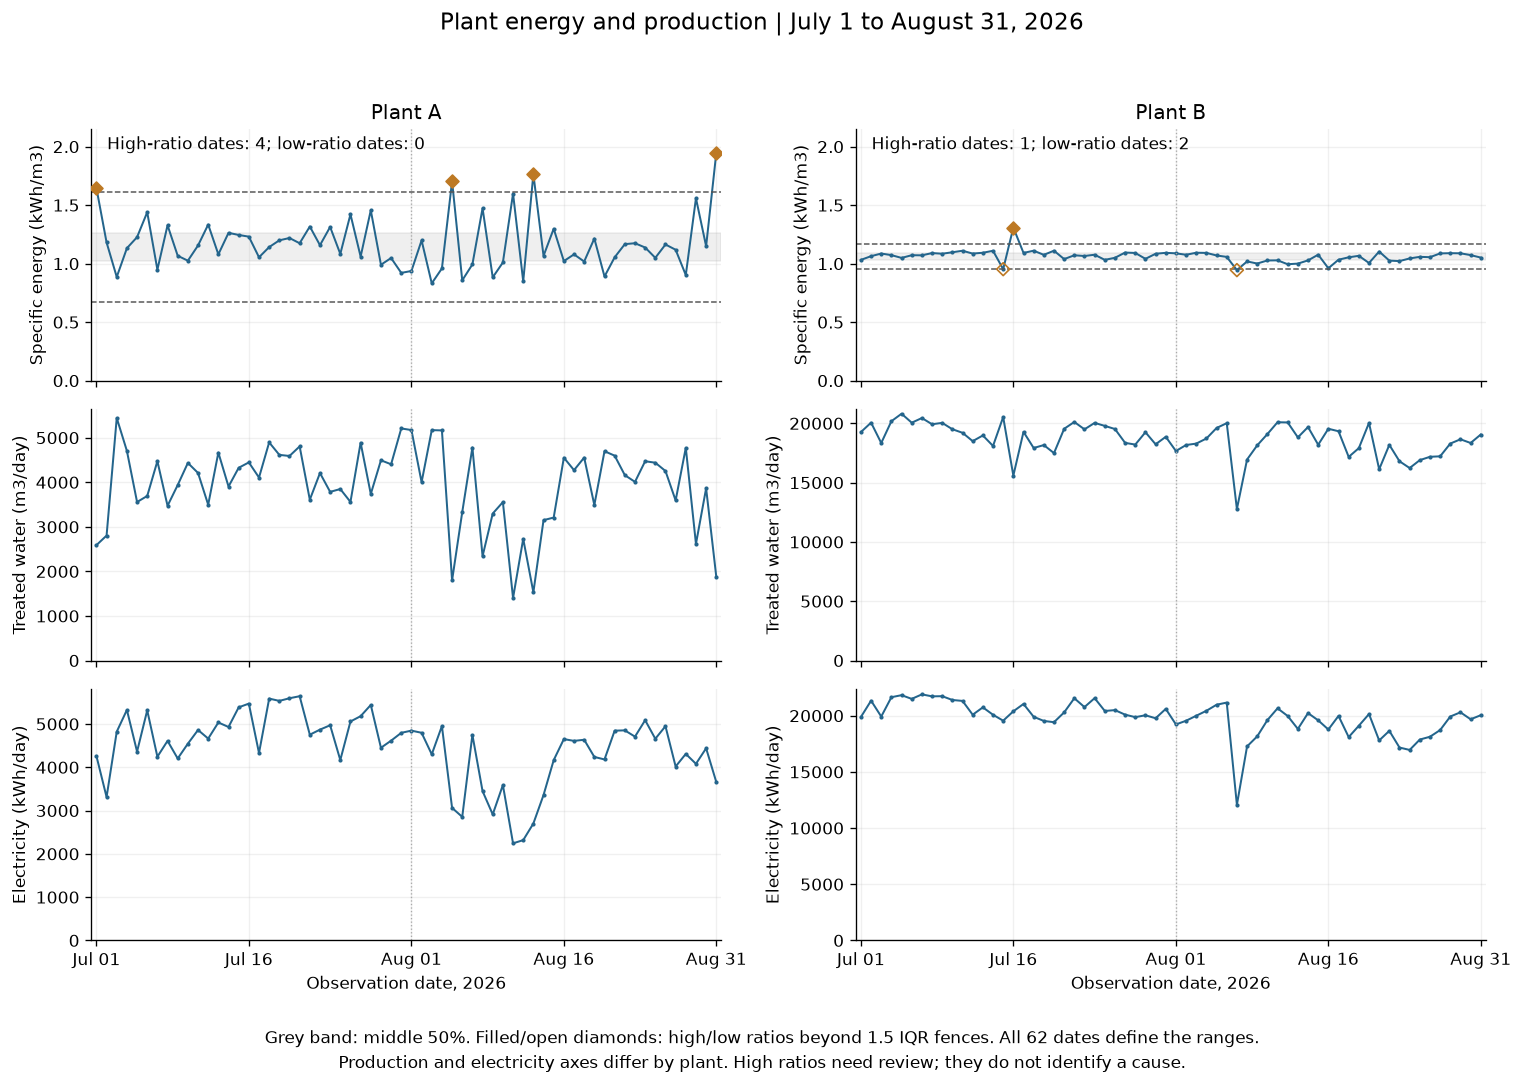

In [22]:
fig, axes = plt.subplots(3, 2, figsize=(12.8, 9), sharex=True)
for column, (plant, frame) in enumerate(historical_context.groupby('plant')):
    for row, (field, ylabel) in enumerate([('Calculated specific energy', 'Specific energy (kWh/m3)'), ('effluent_volume_m3', 'Treated water (m3/day)'), ('daily_electricity_kwh', 'Electricity (kWh/day)')]):
        ax = axes[row, column]
        ax.plot(frame.date, frame[field], color='#24658c', linewidth=1.2, marker='.', markersize=3)
        ax.axvline(pd.Timestamp('2026-08-01'), color='#aaaaaa', linewidth=.8, linestyle=':')
        ax.set(title=plant if row == 0 else '', ylabel=ylabel, ylim=(0, None))
        ax.set_xlim(pd.Timestamp('2026-07-01') - pd.Timedelta(hours=12), pd.Timestamp('2026-08-31') + pd.Timedelta(hours=12))
        ax.set_xticks(pd.to_datetime(['2026-07-01', '2026-07-16', '2026-08-01', '2026-08-16', '2026-08-31']))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
        if row == 0:
            reference = historical_energy_limits.loc[plant]
            ax.axhspan(reference['Lower quartile'], reference['Upper quartile'], color='#aaaaaa', alpha=.18)
            ax.axhline(reference['Upper review limit'], color='#555555', linewidth=.9, linestyle='--')
            high = frame[field].gt(reference['Upper review limit'])
            ax.scatter(frame.loc[high, 'date'], frame.loc[high, field], color='#bd7924', marker='D', s=30, zorder=4)
            lower_reference = historical_profile.loc[historical_profile.Plant.eq(plant) & historical_profile.Indicator.eq(field), 'Lower fence'].iloc[0]
            low = frame[field].lt(lower_reference)
            ax.axhline(lower_reference, color='#555555', linewidth=.9, linestyle='--')
            ax.scatter(frame.loc[low, 'date'], frame.loc[low, field], facecolors='none', edgecolors='#bd7924', marker='D', s=30, zorder=4)
            ax.set_ylim(0, 2.15)
            ax.text(.025, .92, f"High-ratio dates: {int(high.sum())}; low-ratio dates: {int(low.sum())}", transform=ax.transAxes, fontsize=10)
for ax in axes[-1]: ax.set_xlabel('Observation date, 2026')
fig.suptitle('Plant energy and production | July 1 to August 31, 2026', y=.99, fontsize=14)
fig.text(.5, .035, 'Grey band: middle 50%. Filled/open diamonds: high/low ratios beyond 1.5 IQR fences. All 62 dates define the ranges.', ha='center', fontsize=10)
fig.text(.5, .012, 'Production and electricity axes differ by plant. High ratios need review; they do not identify a cause.', ha='center', fontsize=10)
fig.tight_layout(rect=(0, .065, 1, .96))
fig.savefig(historical_dir / 'plant_energy_history.png', dpi=140, facecolor='white')
plt.show()


### Retrospective recovery and quality patterns

Compare each plant with its own history. The middle 50% describes commonly observed readings; outliers require investigation and do not establish a breach of site limits.

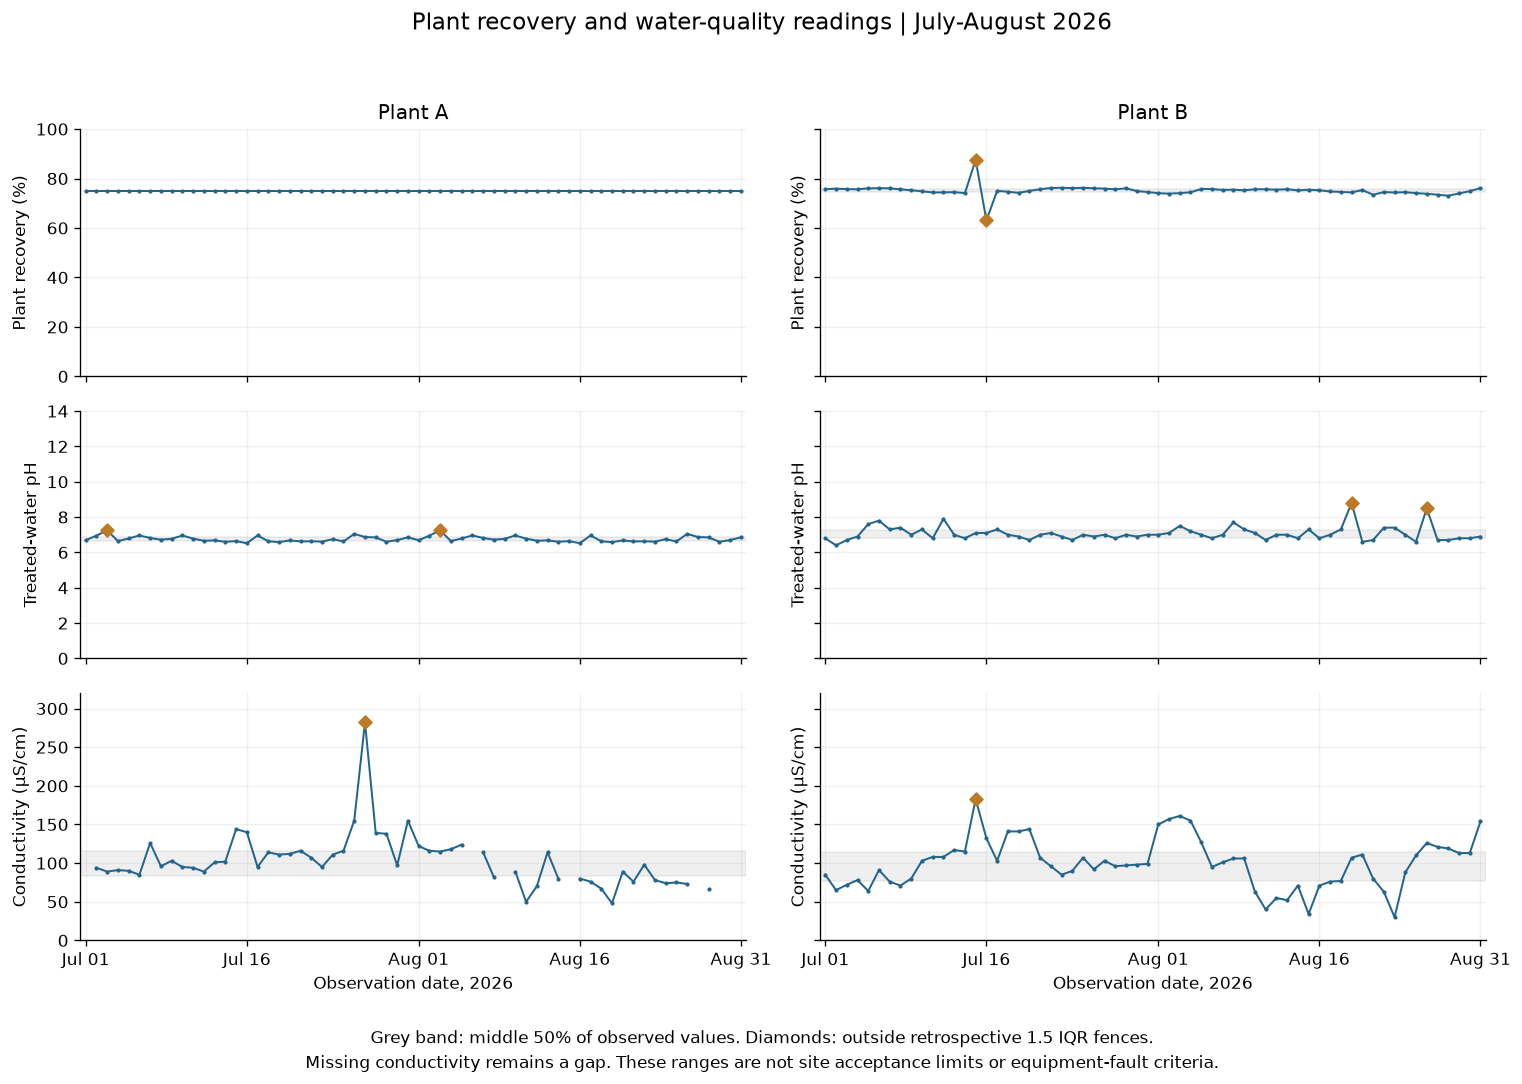

In [23]:
fig, axes = plt.subplots(3, 2, figsize=(12.8, 9), sharex=True, sharey='row')
quality_fields = [('Calculated recovery %', 'Plant recovery (%)', (0, 100)),
                  ('effluent_ph', 'Treated-water pH', (0, 14)),
                  ('effluent_conductivity_us_cm', 'Conductivity (µS/cm)', (0, 320))]
for column, (plant, frame) in enumerate(historical_context.groupby('plant')):
    for row, (field, ylabel, limits) in enumerate(quality_fields):
        ax = axes[row, column]
        reference = historical_profile.loc[historical_profile.Plant.eq(plant) & historical_profile.Indicator.eq(field)].iloc[0]
        ax.plot(frame.date, frame[field], color='#24658c', linewidth=1.2, marker='.', markersize=3)
        ax.axhspan(reference['Lower quartile'], reference['Upper quartile'], color='#aaaaaa', alpha=.18)
        cases = historical_unusual.loc[historical_unusual.Plant.eq(plant) & historical_unusual.Indicator.eq(field)]
        ax.scatter(cases.date, cases.Value, color='#bd7924', marker='D', s=30, zorder=4)
        ax.set(title=plant if row == 0 else '', ylabel=ylabel, ylim=limits)
        ax.set_xlim(pd.Timestamp('2026-07-01') - pd.Timedelta(hours=12), pd.Timestamp('2026-08-31') + pd.Timedelta(hours=12))
        ax.set_xticks(pd.to_datetime(['2026-07-01', '2026-07-16', '2026-08-01', '2026-08-16', '2026-08-31']))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
for ax in axes[-1]: ax.set_xlabel('Observation date, 2026')
fig.suptitle('Plant recovery and water-quality readings | July-August 2026', y=.99, fontsize=14)
fig.text(.5, .035, 'Grey band: middle 50% of observed values. Diamonds: outside retrospective 1.5 IQR fences.', ha='center', fontsize=10)
fig.text(.5, .012, 'Missing conductivity remains a gap. These ranges are not site acceptance limits or equipment-fault criteria.', ha='center', fontsize=10)
fig.tight_layout(rect=(0, .065, 1, .96))
fig.savefig(historical_dir / 'plant_quality_history.png', dpi=140, facecolor='white')
plt.show()


### Read the results

Plant A Pump 1 has no review flag on 104 comparable later days. Plant A Pump 2 has one review flag on 95 comparable later days. These results describe agreement with the earlier reference. They do not establish healthy operation.

Plant B Pump 1 has 34 review days on 97 comparable later days. Its longest continuous review period is May 3 to May 13. The response is above the expected value on all 11 dates. No plant-performance data is supplied for May. The data cannot establish the cause or an energy effect.

Plant B Pumps 2 and 4 each have only ten comparable later days. Most later positive-frequency readings are outside their training ranges. This is a change in operating pattern and a limit of the reference model.

August specific energy is lower than July specific energy for both plants. Electricity and production also decrease. The monthly ratio gives a valid consumption comparison. It does not establish savings caused by an intervention.

The data has high-energy dates in both plants. These dates need checks of production, readings, operating conditions, and available water quality. The energy review limits use the complete July-August period. They are retrospective.


In [24]:
status_columns = ['Reference-consistent days', 'Review days', 'Outside reference range', 'Repeated later days', 'Zero-frequency later days', 'Other unavailable days']
assert historical_summary[status_columns].sum(axis=1).equals(historical_summary['Later dates'])
assert historical_summary['Review days'].sum() == 42
assert historical_summary['Comparable later days'].sum() == 447
assert historical_episodes.iloc[0]['Days'] == 11
assert historical_episodes.iloc[0]['Start'] == pd.Timestamp('2026-05-03')
assert historical_episodes.iloc[0]['End'] == pd.Timestamp('2026-05-13')
assert historical_energy_cases.groupby('plant').size().to_dict() == {'Plant A': 4, 'Plant B': 1}
np.testing.assert_allclose(historical_context['Calculated specific energy'], historical_context.reported_specific_energy_kwh_m3, rtol=1e-5, atol=1e-8)
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in source_hashes.items())
print('PASS: historical day categories reconcile; review periods preserve all flagged days; energy totals and ratios reconcile; original source files are unchanged.')


PASS: historical day categories reconcile; review periods preserve all flagged days; energy totals and ratios reconcile; original source files are unchanged.


### Save the explanation

The following cell writes the results to `HISTORICAL_ANALYSIS.md`. It uses the result tables above.


In [25]:
def markdown_table(frame):
    header = '| ' + ' | '.join(map(str, frame.columns)) + ' |'
    rule = '| ' + ' | '.join(['---'] * len(frame.columns)) + ' |'
    rows = ['| ' + ' | '.join(map(str, row)) + ' |' for row in frame.itertuples(index=False, name=None)]
    return '\n'.join([header, rule] + rows)

pump_table = historical_summary[['Plant', 'Pump', 'Comparable later days', 'Reference-consistent days', 'Review days', 'Outside reference range']].rename(columns={'Reference-consistent days': 'No review flag', 'Outside reference range': 'Outside frequency range'})
period_table = historical_periods.loc[historical_periods.Plant.eq('Plant A') & historical_periods.Period.isin(['Jan-Mar', 'Jul-Aug']), ['Plant', 'Pump', 'Period', 'Fresh pairs', 'Median frequency', 'Median response']].copy()
for field in ['Median frequency', 'Median response']: period_table[field] = period_table[field].map(lambda value: f'{value:.2f}')
month_table = historical_months[['plant', 'Month', 'Days', 'Electricity_kwh', 'Water_m3', 'Specific energy kwh_m3']].rename(columns={'plant':'Plant', 'Electricity_kwh':'Electricity (kWh)', 'Water_m3':'Treated water (m³)', 'Specific energy kwh_m3':'Specific energy (kWh/m³)'}).copy()
month_table['Specific energy (kWh/m³)'] = month_table['Specific energy (kWh/m³)'].map(lambda value: f'{value:.3f}')
change_table = historical_changes.copy()
for field in change_table.columns.difference(['Plant']): change_table[field] = change_table[field].map(lambda value: f'{value:+.1f}%')
energy_table = historical_energy_cases[['plant', 'date', 'daily_electricity_kwh', 'effluent_volume_m3', 'Calculated specific energy']].rename(columns={'plant':'Plant','date':'Date','daily_electricity_kwh':'Electricity (kWh)','effluent_volume_m3':'Treated water (m³)','Calculated specific energy':'Specific energy (kWh/m³)'}).copy()
energy_table.Date = energy_table.Date.dt.strftime('%Y-%m-%d')
energy_table['Specific energy (kWh/m³)'] = energy_table['Specific energy (kWh/m³)'].map(lambda value: f'{value:.3f}')
quality_table = historical_months[['plant', 'Month', 'Median_ph', 'Conductivity_readings', 'Median_conductivity']].rename(columns={'plant':'Plant','Median_ph':'Median pH','Conductivity_readings':'Conductivity readings','Median_conductivity':'Median conductivity (µS/cm)'}).copy()
case = historical_episodes.iloc[0]
context_days = performance.loc[performance.plant.eq(case.Plant) & performance.date.between(case.Start, case.End)].shape[0]
sensitivity = pd.DataFrame(sensitivity_rows)
pump1_sensitivity = sensitivity.loc[sensitivity.Plant.eq('Plant B') & sensitivity.Pump.eq('RO pump 1')]
low_flags, high_flags = int(pump1_sensitivity['Flagged days'].min()), int(pump1_sensitivity['Flagged days'].max())
repeat_counts = {plant:int(mask.sum()) for plant,mask in repeat_masks.items()}
profile_display = historical_profile[['Plant', 'Indicator', 'Valid days', 'Median', 'Lower quartile', 'Upper quartile']].copy()
profile_display['Indicator'] = profile_display.Indicator.map({'Calculated specific energy':'Specific energy (kWh/m³)', 'Calculated recovery %':'Plant recovery (%)', 'effluent_ph':'Treated-water pH', 'effluent_conductivity_us_cm':'Conductivity (µS/cm)'})
for field in ['Median', 'Lower quartile', 'Upper quartile']: profile_display[field] = profile_display[field].map(lambda value: f'{value:.3f}')
quality_cases = historical_unusual.loc[historical_unusual.Indicator.ne('Calculated specific energy'), ['Plant', 'date', 'Indicator', 'Value', 'Unit']].copy()
quality_cases['date'] = quality_cases.date.dt.strftime('%Y-%m-%d')
quality_cases['Value'] = quality_cases.Value.map(lambda value: f'{value:.3f}')
quality_cases['Indicator'] = quality_cases.Indicator.map({'Calculated recovery %':'Plant recovery', 'effluent_ph':'Treated-water pH', 'effluent_conductivity_us_cm':'Conductivity'})
low_energy_table = historical_unusual.loc[historical_unusual.Indicator.eq('Calculated specific energy') & historical_unusual.Direction.eq('Below'), ['Plant', 'date', 'Value']].copy()
low_energy_table['date'] = low_energy_table.date.dt.strftime('%Y-%m-%d')
low_energy_table['Value'] = low_energy_table.Value.map(lambda value: f'{value:.3f}')
low_energy_table = low_energy_table.rename(columns={'date':'Date', 'Value':'Specific energy (kWh/m³)'})
text = f'''# Historical operating patterns

The question is what was commonly observed and which dates depart from that history. Reference-consistent readings are not verified healthy operation; unusual readings are investigation cases, not confirmed faults.

## Data and calculations

Equipment history covers 244 daily dates per plant, 1 January-1 September 2026. Plant A has two supplied RO pumps and Plant B has four. Interpretable plant-performance records cover 62 dates per plant, 1 July-31 August. All 124 plant/date keys are unique; comparisons and ratios use matching plant/date records.

| Available input | Source field | Use |
| --- | --- | --- |
| Daily electricity | `daily_electricity_kwh` | Energy consumption |
| Treated-water volume | `effluent_volume_m3` | Production and energy per unit of output |
| Incoming-water volume | `influent_volume_m3` | Plant water recovery |
| Treated-water conductivity | `effluent_conductivity_us_cm` | Water-quality trends |
| Treated-water pH | `effluent_ph` | Water-chemistry trends |

- Daily specific energy = electricity / treated-water volume, in kWh/m³.
- Daily plant recovery = treated-water volume / incoming-water volume × 100, in %.
- Period specific energy = total electricity / total treated-water volume over the same eligible dates. Do not average daily ratios for this period result.

Use paired finite readings and positive denominator volumes. Plant quantities cannot establish an individual pump's efficiency or RO-stage recovery. Electricity, both volumes and pH are complete; Plant A has eight missing conductivity readings. Chemical records remain too sparse and insufficiently defined for reliable dosing comparisons.

## Commonly observed patterns

The median and middle 50% (lower to upper quartile) describe each plant's supplied July-August history. They are descriptive ranges, not physical operating limits. A value outside the middle 50% alone is not classified as abnormal.

{markdown_table(profile_display)}

Plant A's calculated recovery remains effectively 75% throughout. This agrees with the reported value but does not establish independent variation or validated process performance. Monthly median pH is 6.7 for Plant A and 7.0 for Plant B in both months; individual spikes still occur.

### Energy and production changed together

{markdown_table(month_table)}

{markdown_table(change_table)}

August specific energy is lower than July by 5.8% in Plant A and 3.0% in Plant B. Electricity falls more than production in both plants. This explains the ratio change mathematically; its operational cause and any attributable savings are unverified. Conductivity medians change from 105 to 80 µS/cm in Plant A and from 98 to 106 µS/cm in Plant B. Missing values and unknown quality limits prevent a conclusion that treatment quality improved or remained acceptable.

![Actual plant energy and production history](output/historical/plant_energy_history.png)

## Unusual plant readings to investigate

Use strict retrospective fences below Q1 − 1.5 × IQR or above Q3 + 1.5 × IQR, calculated separately for each plant and indicator from all available July-August dates. Missing values are excluded. An effectively constant IQR has no usable outlier screen. These full-history fences describe this dataset and must not be presented as prospective early-warning thresholds.

### High electricity per unit of water

{markdown_table(energy_table)}

Upper historical fences are 1.613 kWh/m³ for Plant A and 1.170 for Plant B. The highest Plant A case is 31 August: 3,660 kWh / 1,881 m³ = 1.946 kWh/m³. Its absolute electricity use is below Plant A's daily median, while output is also below the median. Review low production and operating conditions before attributing the high ratio to increased equipment consumption.

### Low electricity per unit of water

{markdown_table(low_energy_table)}

The Plant B lower fence is 0.954 kWh/m³. These two small lower-end departures do not establish improved efficiency. Check water output and quality together; the 15 July record also has unusual recovery and conductivity.

### Recovery, pH and conductivity

{markdown_table(quality_cases)}

Plant B's 15 July record combines unusually high calculated recovery (87.506%) with high conductivity (183 µS/cm). On 16 July, recovery is unusually low (63.075%) and specific energy is high (1.308 kWh/m³). This date alignment warrants checking source records and operating conditions; it does not establish a causal link.

Verify the pH spikes and conductivity spikes against instrument records and site limits. Statistical unusualness does not establish a water-quality violation.

![Actual plant recovery and quality history](output/historical/plant_quality_history.png)

## Data-quality findings

- Plant A has 21 adjacent full-equipment-reading repeats; Plant B has 10. They may be legitimate repeated operation or collection problems and need verification.
- Both Plant A runtime counters have a 183-day identical period and decrease on 3 July. Do not interpret negative counter differences as consumption or operating hours.
- Plant A has positive power-labelled readings on its zero-frequency dates. Check signal definitions, timing and aggregation; neither reading alone establishes an off/on state.
- Plant B has eight reported-versus-calculated recovery differences on 28-31 July and 28-31 August. Keep these reconciliation cases separate from the two recovery outliers above; rounding or reporting rules need clarification.
- Missing Plant A conductivity remains unavailable, not zero.

## Existing equipment patterns: exploratory only

The previous analysis uses frequency-labelled readings against Plant A power-labelled readings and Plant B `a_out`. Their source mappings are in `Dataset/plant_daily_unified_dictionary.csv`; physical meanings, scales and aggregation remain provisional. `a_out` is not a selected physical efficiency indicator. These results document the existing experiment rather than validate it as an operational degradation detector.

Fit a separate least-squares line `a + b × frequency` from each pump's first 90 calendar days, using finite positive-frequency pairs without adjacent full-row repeats. At least 30 pairs and three distinct frequency readings are required; the supplied histories have 67-86 training pairs. Set `c` to the median training residual and `s` to 1.4826 times the residual median absolute deviation. Expected response is `a + b × frequency + c`; comparison score is `(response − expected) / s`.

The supplied reference covers 1 January-31 March; later evaluation covers 1 April-1 September. Missing/invalid pairs, repeated rows, nonpositive frequency, out-of-range frequency and unusable residual scales have unavailable comparisons. The fixed reference is historical, not verified healthy operation; frequency alone does not account for flow, pressure, feed conditions or loading.

{markdown_table(pump_table)}

There are 447 comparable later pump-dates and 42 single-day review dates under the existing absolute score > 3.5 rule. Plant B pump 1's longest contiguous review period is 3-13 May (11 dates), with a median response difference of 14.1% above expected. No plant-performance records overlap that May case, so an energy effect cannot be established. Plant B pumps 2 and 4 each permit comparison on only 10 of 154 later dates (6.5%); unavailable comparisons do not establish stable operation.

See [DETECTION_APPROACH.md](DETECTION_APPROACH.md) for the chosen detection target, proposed method and status of the existing experiment. This historical report does not implement a replacement detector or operational alarm thresholds.

## Evidence and checks

Reproduce the analysis by running [data_review.ipynb](data_review.ipynb) top-to-bottom with the project Python environment. Inputs are the original equipment CSVs, plant-performance CSV and dictionary in `Dataset/`; source-file SHA-256 hashes are checked before and after execution.

Inspect the exported [indicator ranges](output/historical/plant_indicator_profile.csv), [unusual plant readings](output/historical/unusual_plant_readings.csv), [recovery reconciliation](output/historical/recovery_reconciliation.csv), [monthly totals](output/historical/plant_months.csv), [monthly changes](output/historical/plant_month_changes.csv), [high-energy dates](output/historical/high_specific_energy_dates.csv), and [equipment summary](output/historical/pump_summary.csv).

Checks cover unique daily keys, finite ratio inputs, positive denominators, missing-versus-zero handling, strict outlier fences, constant recovery, monthly ratio reconciliation and equipment-day categories. No verified fault labels, maintenance history or site quality limits are supplied; the findings support investigation rather than confirmed degradation or compliance conclusions.
'''
assert len(pump_table) == 6 and len(month_table) == 4
assert len(energy_table) == 5 and len(low_energy_table) == 2 and len(quality_cases) == 8
assert context_days == 0
assert all(hashlib.sha256(p.read_bytes()).hexdigest() == digest for p, digest in source_hashes.items())
report_path = source_dir.parent / 'HISTORICAL_ANALYSIS.md'
report_path.write_text(text, encoding='utf-8')
print('Saved HISTORICAL_ANALYSIS.md from the executed result tables.')


Saved HISTORICAL_ANALYSIS.md from the executed result tables.


## Existing telemetry experiment: exploratory only

The following cells preserve the frequency-response experiment and its constructed checks. They do not implement the electricity-versus-output target described in [DETECTION_APPROACH.md](DETECTION_APPROACH.md).

Three consecutive eligible days beyond the same signed threshold confirm a pattern change on day three; this does not establish performance degradation.


In [26]:
import sys
if str(source_dir.parent) not in sys.path:
    sys.path.insert(0, str(source_dir.parent))
from detection_rules import persistent_warnings, ewma_scores
import json

warning_dir = source_dir.parent / 'output' / 'detection'
warning_dir.mkdir(parents=True, exist_ok=True)
warning_daily_tables, warning_summary_rows, warning_period_rows, warning_evidence_rows = [], [], [], []
warning_sensitivity_rows, reference_rows = [], []
for pump in pumps:
    plant, label = pump['Plant'], pump['Pump']
    reference = pump_references[(plant, label)]
    training_dates = pd.date_range(reference['Training start'], reference['Training end'])
    training_score = reference['Training scores'].reindex(training_dates)
    initial = float(training_score.dropna().median())
    training_ewma = ewma_scores(training_score, initial=initial)
    limit = float((training_ewma - initial).abs().dropna().quantile(.99))
    assert np.isfinite(limit) and limit > 0, 'EWMA needs a usable training limit'
    reference_rows.append({'Plant': plant, 'Pump': label,
        **{key: value for key, value in reference.items() if key != 'Training scores'},
        'EWMA weight': .2, 'EWMA initial': initial, 'EWMA limit': limit, 'EWMA calibration percentile': .99})
    daily = historical_daily.loc[historical_daily.Plant.eq(plant) & historical_daily.Pump.eq(label)].set_index('date').copy()
    daily_score = daily['Review score']
    rule = persistent_warnings(daily_score)
    daily = daily.join(rule)
    daily['Single-day review'] = daily_score.abs().gt(3.5)
    daily['EWMA score'] = ewma_scores(daily_score, initial=initial)
    daily['EWMA review'] = (daily['EWMA score'] - initial).abs().gt(limit)
    daily['Warning state'] = np.where(daily_score.isna(), 'Comparison unavailable', np.where(daily.Warning, 'Review persistent change', 'No warning'))
    assert not daily.loc[daily_score.isna(), ['Warning', 'Single-day review', 'EWMA review']].any().any()
    confirmed = daily.loc[daily.Warning]
    for onset, block in confirmed.groupby('Candidate onset'):
        confirmation = block['Confirmation date'].iloc[0]
        supporting = daily.loc[onset:confirmation]
        assert len(supporting) == 3
        assert supporting['Review score'].notna().all()
        assert supporting.index.to_series().diff().iloc[1:].eq(pd.Timedelta(days=1)).all()
        assert supporting['Review score'].gt(2).all() or supporting['Review score'].lt(-2).all()
        warning_period_rows.append({'Plant': plant, 'Pump': label, 'Candidate onset': onset,
            'First warning': confirmation, 'Last supporting day': block.index.max(),
            'Supporting days': int(block['Streak days'].iloc[-1]), 'Warning days': len(block),
            'Direction': block.Direction.iloc[0], 'Threshold': 2.,
            'Median observed response': supporting['Observed response'].median(),
            'Median expected response': supporting['Expected response'].median(),
            'Initial score 1': supporting['Review score'].iloc[0], 'Initial score 2': supporting['Review score'].iloc[1], 'Initial score 3': supporting['Review score'].iloc[2]})
        raw_dates = pd.to_datetime(raw[plant]['date'], format='mixed')
        for date, row in supporting.iterrows():
            source_row = int(np.flatnonzero(raw_dates.eq(date).to_numpy())[0]) + 1
            warning_evidence_rows.append({'Plant': plant, 'Pump': label, 'Candidate onset': onset, 'First warning': confirmation,
                'Evidence date': date, 'Frequency': row.Frequency, 'Observed response': row['Observed response'],
                'Expected response': row['Expected response'], 'Review score': row['Review score'],
                'Source file': names[plant], 'Source row': source_row,
                'Frequency field': pump['Frequency'], 'Response field': pump['Response']})
    for threshold in [1.5, 2., 2.5]:
        sensitivity_result = persistent_warnings(daily_score, threshold=threshold)
        warning_sensitivity_rows.append({'Plant': plant, 'Pump': label, 'Threshold': threshold,
            'Warning periods': sensitivity_result.loc[sensitivity_result.Warning, 'Candidate onset'].nunique(),
            'Warning days': int(sensitivity_result.Warning.sum()), 'Comparable days': int(daily_score.notna().sum())})
    ewma_starts = daily['EWMA review'] & ~daily['EWMA review'].shift(fill_value=False)
    warning_summary_rows.append({'Plant': plant, 'Pump': label, 'Later dates': len(daily),
        'Comparable days': int(daily_score.notna().sum()), 'Coverage %': 100*daily_score.notna().mean(),
        'Warning periods': confirmed['Candidate onset'].nunique(), 'Warning days': int(daily.Warning.sum()),
        'First warning': confirmed['Confirmation date'].min(),
        'Single-day review days': int(daily['Single-day review'].sum()),
        'EWMA review periods': int(ewma_starts.sum()), 'EWMA review days': int(daily['EWMA review'].sum()), 'EWMA limit': limit})
    # Replay checks include every confirmation boundary and the final date.
    replay_lengths = {1, 2, 3, len(daily)}
    for confirmation in confirmed['Confirmation date'].drop_duplicates():
        length = daily.index.get_loc(confirmation) + 1
        replay_lengths.update([length - 1, length, min(length + 1, len(daily))])
    for length in sorted(replay_lengths):
        if length > 0:
            pd.testing.assert_frame_equal(persistent_warnings(daily_score.iloc[:length]), rule.iloc[:length], check_dtype=False)
            pd.testing.assert_series_equal(ewma_scores(daily_score.iloc[:length], initial=initial), daily['EWMA score'].iloc[:length])
    warning_daily_tables.append(daily.reset_index())
warning_daily = pd.concat(warning_daily_tables, ignore_index=True)
warning_summary = pd.DataFrame(warning_summary_rows)
warning_periods = pd.DataFrame(warning_period_rows).sort_values(['First warning', 'Plant', 'Pump']).reset_index(drop=True)
warning_evidence = pd.DataFrame(warning_evidence_rows)
warning_sensitivity = pd.DataFrame(warning_sensitivity_rows)
warning_references = pd.DataFrame(reference_rows)
assert warning_summary['Comparable days'].sum() == historical_summary['Comparable later days'].sum()
assert warning_summary['Single-day review days'].sum() == historical_summary['Review days'].sum()
assert len(warning_evidence) == 3 * len(warning_periods)
assert warning_periods['First warning'].sub(warning_periods['Candidate onset']).eq(pd.Timedelta(days=2)).all()
for filename, table in [('daily_warnings.csv', warning_daily), ('warning_summary.csv', warning_summary),
    ('warning_periods.csv', warning_periods), ('warning_evidence.csv', warning_evidence),
    ('warning_sensitivity.csv', warning_sensitivity), ('reference_parameters.csv', warning_references)]:
    table.to_csv(warning_dir / filename, index=False, date_format='%Y-%m-%d')
(warning_dir / 'source_hashes.json').write_text(json.dumps({path.name:digest for path,digest in source_hashes.items()}, indent=2), encoding='utf-8')
display(warning_summary[['Plant', 'Pump', 'Comparable days', 'Coverage %', 'Warning periods', 'Warning days', 'First warning', 'Single-day review days', 'EWMA review days']])
display(warning_periods[['Plant', 'Pump', 'Candidate onset', 'First warning', 'Last supporting day', 'Supporting days', 'Direction']])
display(warning_sensitivity)


,Plant,Pump,Comparable days,Coverage %,Warning periods,Warning days,First warning,Single-day review days,EWMA review days
0,Plant A,RO pump 1,104,67.532,0,0,NaT,0,0
1,Plant A,RO pump 2,95,61.688,2,6,2026-07-20,1,0
2,Plant B,RO pump 1,97,62.987,6,36,2026-04-03,34,63
3,Plant B,RO pump 2,10,6.494,0,0,NaT,0,0
4,Plant B,RO pump 3,131,85.065,3,7,2026-06-23,7,25
5,Plant B,RO pump 4,10,6.494,1,1,2026-07-30,0,1


,Plant,Pump,Candidate onset,First warning,Last supporting day,Supporting days,Direction
0,Plant B,RO pump 1,2026-04-01,2026-04-03,2026-04-19,19,Above expected
1,Plant B,RO pump 1,2026-04-28,2026-04-30,2026-05-01,4,Above expected
2,Plant B,RO pump 1,2026-05-03,2026-05-05,2026-05-13,11,Above expected
3,Plant B,RO pump 1,2026-05-17,2026-05-19,2026-05-20,4,Above expected
4,Plant B,RO pump 1,2026-05-22,2026-05-24,2026-05-28,7,Above expected
5,Plant B,RO pump 1,2026-06-06,2026-06-08,2026-06-08,3,Above expected
6,Plant B,RO pump 3,2026-06-21,2026-06-23,2026-06-26,6,Above expected
7,Plant A,RO pump 2,2026-07-18,2026-07-20,2026-07-22,5,Below expected
8,Plant B,RO pump 3,2026-07-23,2026-07-25,2026-07-25,3,Above expected
9,Plant B,RO pump 4,2026-07-28,2026-07-30,2026-07-30,3,Above expected


,Plant,Pump,Threshold,Warning periods,Warning days,Comparable days
0,Plant A,RO pump 1,1.500,0,0,104
1,Plant A,RO pump 1,2.000,0,0,104
2,Plant A,RO pump 1,2.500,0,0,104
3,Plant A,RO pump 2,1.500,5,12,95
4,Plant A,RO pump 2,2.000,2,6,95
5,Plant A,RO pump 2,2.500,0,0,95
6,Plant B,RO pump 1,1.500,7,44,97
7,Plant B,RO pump 1,2.000,6,36,97
8,Plant B,RO pump 1,2.500,5,35,97
9,Plant B,RO pump 2,1.500,0,0,10


### Constructed changes

Use a fixed random seed and 90 earlier score observations to calibrate the EWMA limit. Compare both methods on 60 later constructed dates. Report pre-change reviews as well as delay.


In [27]:
# Construct score-level changes; these are not plant readings or failure labels.
rng = np.random.default_rng(20261013)
synthetic_train_raw = rng.normal(size=90)
synthetic_center, synthetic_scale = residual_scale(synthetic_train_raw)
synthetic_training = pd.Series((synthetic_train_raw-synthetic_center)/synthetic_scale, index=pd.date_range('2026-01-01', periods=90))
synthetic_initial = float(synthetic_training.median())
synthetic_limit = float((ewma_scores(synthetic_training, initial=synthetic_initial)-synthetic_initial).abs().quantile(.99))
synthetic_dates = pd.date_range('2026-04-01', periods=60)
synthetic_base = (rng.normal(size=60)-synthetic_center)/synthetic_scale
change_position = 20
change_date = synthetic_dates[change_position]
synthetic_cases = {'No injected change': pd.Series(synthetic_base.copy(), index=synthetic_dates)}
for label, sign in [('Step up', 1), ('Step down', -1), ('Gradual up', 1), ('Gradual down', -1)]:
    values = synthetic_base.copy()
    values[change_position:] += sign*(3 if label.startswith('Step') else np.linspace(.1, 3.5, 60-change_position))
    synthetic_cases[label] = pd.Series(values, index=synthetic_dates)
spike = synthetic_base.copy(); spike[change_position] += 5
synthetic_cases['One isolated spike'] = pd.Series(spike, index=synthetic_dates)
step = synthetic_cases['Step up']
synthetic_cases['Step with date gap'] = step.drop(synthetic_dates[change_position+1])
synthetic_cases['Step with excluded reading'] = step.copy()
synthetic_cases['Step with excluded reading'].iloc[change_position+1] = np.nan
synthetic_rows = []
synthetic_method_outputs = {}
for label, values in synthetic_cases.items():
    persistence = persistent_warnings(values)
    moving = ewma_scores(values, initial=synthetic_initial)
    ewma_review = (moving-synthetic_initial).abs().gt(synthetic_limit)
    outputs = {'Three-day rule': persistence.Warning, 'EWMA candidate': ewma_review}
    synthetic_method_outputs[label] = (values, persistence, moving, ewma_review)
    for method, flags in outputs.items():
        consecutive = flags.index.to_series().diff().eq(pd.Timedelta(days=1))
        starts = flags & (~flags.shift(fill_value=False) | ~consecutive)
        after_change = starts.loc[starts.index >= change_date] if label != 'No injected change' else starts.iloc[:0]
        first = after_change.index[after_change].min() if after_change.any() else pd.NaT
        before = flags.loc[flags.index < change_date] if label != 'No injected change' else flags
        synthetic_rows.append({'Case': label, 'Method': method,
            'Pre-change review days': int(before.sum()), 'Review days': int(flags.sum()), 'Review periods': int(starts.sum()),
            'First new review after change': first,
            'Delay days': (first-change_date).days if pd.notna(first) else np.nan,
            'Limit': 2. if method == 'Three-day rule' else synthetic_limit})
synthetic_results = pd.DataFrame(synthetic_rows)
synthetic_results.to_csv(warning_dir / 'constructed_change_comparison.csv', index=False, date_format='%Y-%m-%d')
display(synthetic_results[['Case', 'Method', 'Pre-change review days', 'Review days', 'Review periods', 'Delay days']])
print('Constructed checks compare algorithm behavior. They do not measure real failure accuracy or failure lead time.')


,Case,Method,Pre-change review days,Review days,Review periods,Delay days
0,No injected change,Three-day rule,0,0,0,NaN
1,No injected change,EWMA candidate,2,2,1,NaN
2,Step up,Three-day rule,0,20,4,1.000
3,Step up,EWMA candidate,0,39,1,1.000
4,Step down,Three-day rule,0,31,3,2.000
5,Step down,EWMA candidate,0,39,1,1.000
6,Gradual up,Three-day rule,0,10,2,27.000
7,Gradual up,EWMA candidate,0,21,1,19.000
8,Gradual down,Three-day rule,0,17,3,15.000
9,Gradual down,EWMA candidate,0,30,1,10.000


Constructed checks compare algorithm behavior. They do not measure real failure accuracy or failure lead time.


### Warning dates

A triangle shows the first available warning date. It does not show the first change date. Single-day review items remain separate.


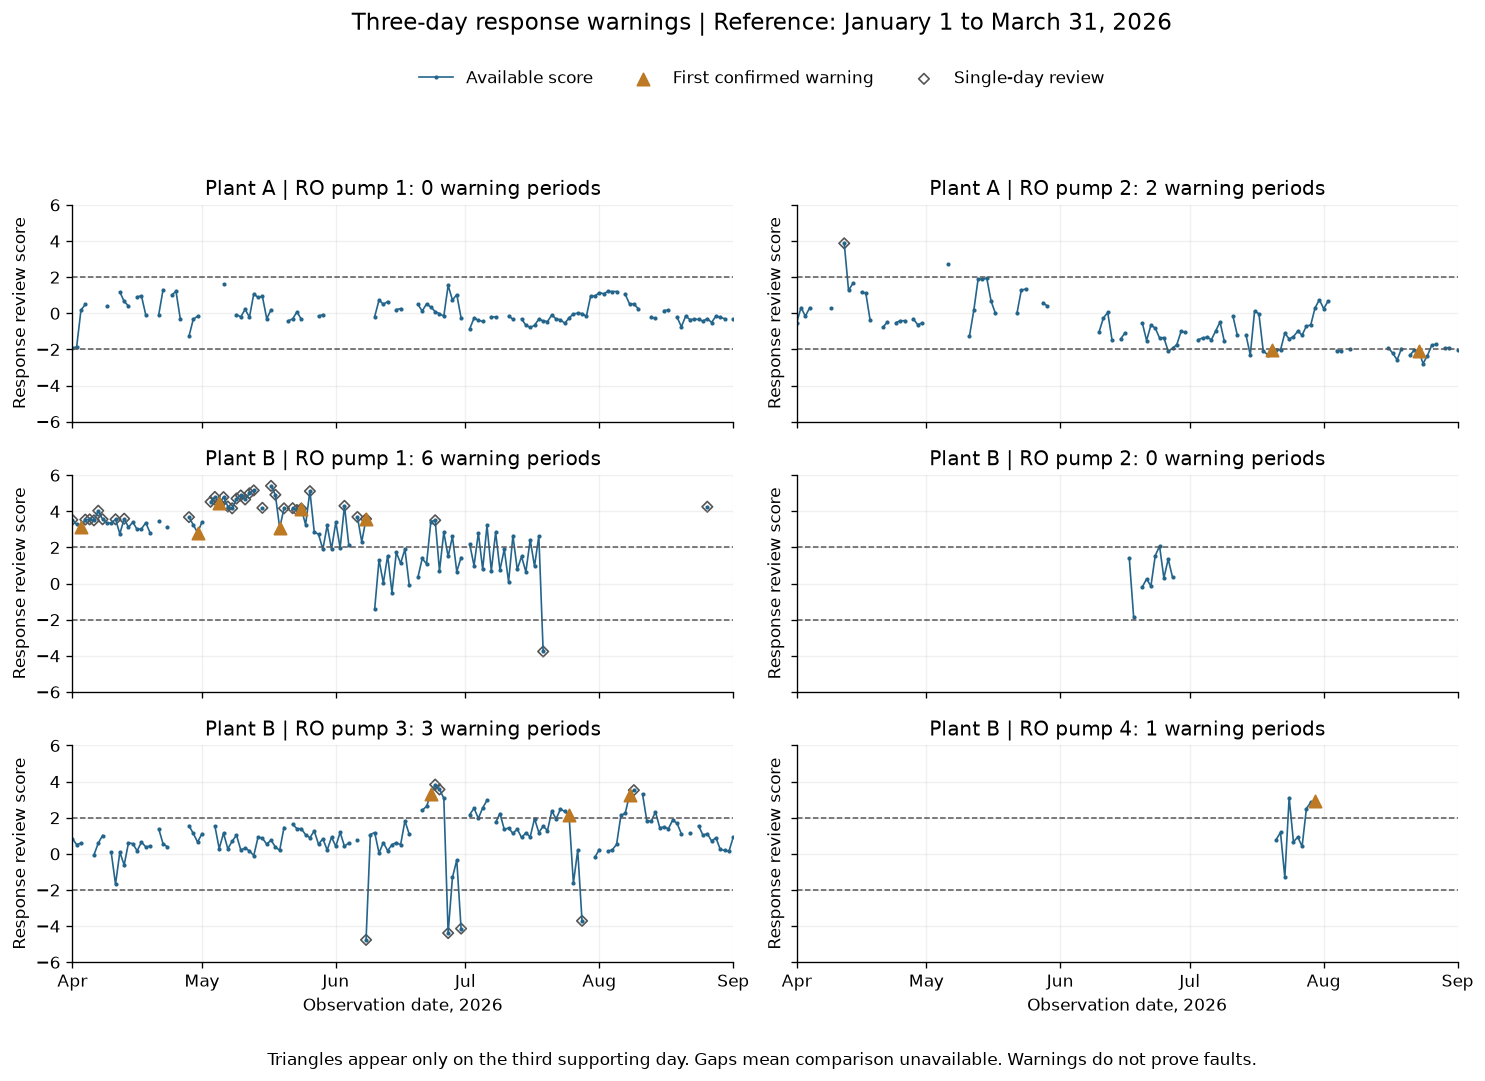

In [28]:
fig, axes = plt.subplots(3, 2, figsize=(12.8, 9), sharex=True, sharey=True)
for ax, pump in zip(axes.flat, pumps):
    plant, label = pump['Plant'], pump['Pump']
    daily = warning_daily.loc[warning_daily.Plant.eq(plant) & warning_daily.Pump.eq(label)].set_index('date')
    ax.plot(daily.index, daily['Review score'], color='#24658c', linewidth=1, marker='.', markersize=3, label='Available score')
    for limit in [-2, 2]: ax.axhline(limit, color='#555555', linestyle='--', linewidth=.9)
    first = daily.Warning & daily.index.to_series().eq(daily['Confirmation date'])
    ax.scatter(daily.index[first], daily.loc[first, 'Review score'], color='#bd7924', marker='^', s=55, zorder=5, label='First confirmed warning')
    single = daily['Single-day review']
    ax.scatter(daily.index[single], daily.loc[single, 'Review score'], facecolors='none', edgecolors='#555555', marker='D', s=20, label='Single-day review')
    count = int(warning_summary.loc[warning_summary.Plant.eq(plant) & warning_summary.Pump.eq(label), 'Warning periods'].iloc[0])
    ax.set(title=f'{plant} | {label}: {count} warning periods', ylim=(-6,6), ylabel='Response review score')
    ax.set_xlim(pd.Timestamp('2026-04-01'), pd.Timestamp('2026-09-01'))
    ax.set_xticks(pd.date_range('2026-04-01','2026-09-01',freq='MS'))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
for ax in axes[-1]: ax.set_xlabel('Observation date, 2026')
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles,labels,loc='upper center',bbox_to_anchor=(.5,.95),ncols=3,frameon=False)
fig.suptitle('Three-day response warnings | Reference: January 1 to March 31, 2026',y=.99,fontsize=14)
fig.text(.5,.015,'Triangles appear only on the third supporting day. Gaps mean comparison unavailable. Warnings do not prove faults.',ha='center',fontsize=10)
fig.tight_layout(rect=(0,.045,.975,.89))
fig.savefig(warning_dir/'persistent_change_warnings.png',dpi=140,facecolor='white')
plt.show()


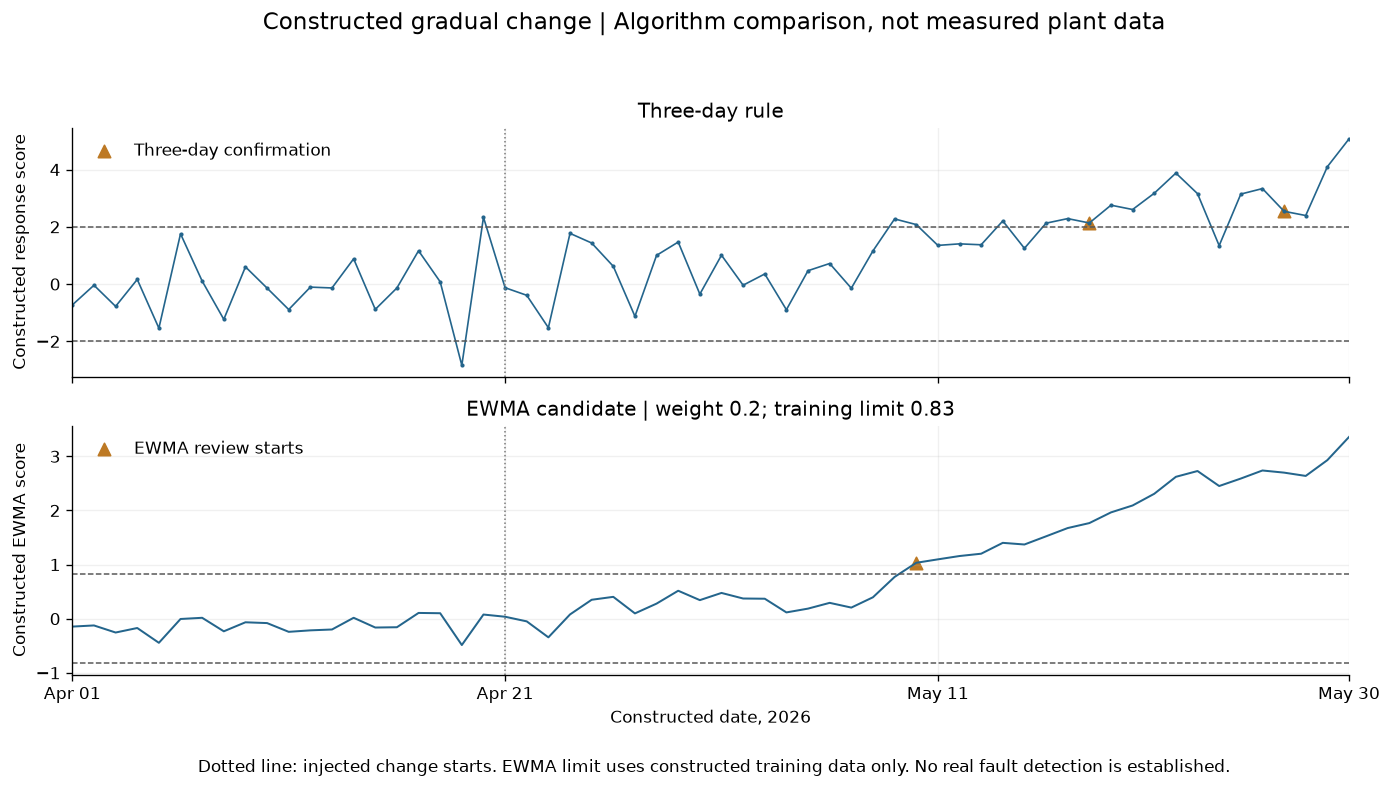

In [29]:
values, persistence, moving, ewma_review = synthetic_method_outputs['Gradual up']
fig, axes = plt.subplots(2,1,figsize=(12,6.5),sharex=True)
axes[0].plot(values.index,values,color='#24658c',linewidth=1,marker='.',markersize=3)
for limit in [-2,2]: axes[0].axhline(limit,color='#555555',linestyle='--',linewidth=.9)
first = persistence.Warning & persistence.index.to_series().eq(persistence['Confirmation date'])
axes[0].scatter(values.index[first],values.loc[first],color='#bd7924',marker='^',s=55,label='Three-day confirmation')
axes[0].set(ylabel='Constructed response score',title='Three-day rule')
axes[0].legend(loc='upper left',frameon=False)
axes[1].plot(moving.index,moving,color='#24658c',linewidth=1.2)
for limit in [-synthetic_limit,synthetic_limit]: axes[1].axhline(synthetic_initial+limit,color='#555555',linestyle='--',linewidth=.9)
ewma_start = ewma_review & ~ewma_review.shift(fill_value=False)
axes[1].scatter(moving.index[ewma_start],moving.loc[ewma_start],color='#bd7924',marker='^',s=55,label='EWMA review starts')
axes[1].set(ylabel='Constructed EWMA score',title=f'EWMA candidate | weight 0.2; training limit {synthetic_limit:.2f}',xlabel='Constructed date, 2026')
axes[1].legend(loc='upper left',frameon=False)
for ax in axes:
    ax.axvline(change_date,color='#777777',linestyle=':',linewidth=.9)
    ax.set_xlim(values.index.min(),values.index.max())
    ax.set_xticks(pd.to_datetime(['2026-04-01','2026-04-21','2026-05-11','2026-05-30']))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
fig.suptitle('Constructed gradual change | Algorithm comparison, not measured plant data',y=.99,fontsize=14)
fig.text(.5,.015,'Dotted line: injected change starts. EWMA limit uses constructed training data only. No real fault detection is established.',ha='center',fontsize=10)
fig.tight_layout(rect=(0,.05,.975,.95))
fig.savefig(warning_dir/'constructed_gradual_change.png',dpi=140,facecolor='white')
plt.show()


In [30]:
assert len(warning_daily) == len(historical_daily)
assert warning_daily.groupby(['Plant','Pump']).size().eq(154).all()
assert warning_summary['Warning periods'].sum() == len(warning_periods)
assert warning_summary['Warning days'].sum() == warning_periods['Warning days'].sum()
assert warning_evidence.groupby(['Plant','Pump','First warning']).size().eq(3).all()
for _, event in warning_periods.iterrows():
    pump_daily = warning_daily.loc[warning_daily.Plant.eq(event.Plant) & warning_daily.Pump.eq(event.Pump)].set_index('date')
    assert not pump_daily.loc[event['Candidate onset']:event['First warning']].Warning.iloc[:2].any()
    assert pump_daily.loc[event['First warning'], 'Warning']
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path,digest in source_hashes.items())
print(f"PASS: {len(warning_periods)} persistent-change periods; first-warning evidence, coverage, sensitivity, replay and source hashes checked.")
print('The default remains the three-day rule. EWMA is a comparison candidate, not a verified fault detector.')


PASS: 12 persistent-change periods; first-warning evidence, coverage, sensitivity, replay and source hashes checked.
The default remains the three-day rule. EWMA is a comparison candidate, not a verified fault detector.


In [31]:
# Retain executed evidence for the old telemetry experiment without regenerating retired documents.
assert int(warning_summary['Warning periods'].sum()) == 12
assert int(warning_summary['Warning days'].sum()) == 50
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in source_hashes.items())
display(warning_summary[['Plant', 'Pump', 'Comparable days', 'Coverage %', 'Warning periods', 'Warning days']])
display(synthetic_results)
print('Exploratory telemetry results retained in output/detection/. The electricity-versus-output target in DETECTION_APPROACH.md remains unimplemented.')


,Plant,Pump,Comparable days,Coverage %,Warning periods,Warning days
0,Plant A,RO pump 1,104,67.532,0,0
1,Plant A,RO pump 2,95,61.688,2,6
2,Plant B,RO pump 1,97,62.987,6,36
3,Plant B,RO pump 2,10,6.494,0,0
4,Plant B,RO pump 3,131,85.065,3,7
5,Plant B,RO pump 4,10,6.494,1,1


,Case,Method,Pre-change review days,Review days,Review periods,First new review after change,Delay days,Limit
0,No injected change,Three-day rule,0,0,0,NaT,NaN,2.000
1,No injected change,EWMA candidate,2,2,1,NaT,NaN,0.825
2,Step up,Three-day rule,0,20,4,2026-04-22,1.000,2.000
3,Step up,EWMA candidate,0,39,1,2026-04-22,1.000,0.825
4,Step down,Three-day rule,0,31,3,2026-04-23,2.000,2.000
5,Step down,EWMA candidate,0,39,1,2026-04-22,1.000,0.825
6,Gradual up,Three-day rule,0,10,2,2026-05-18,27.000,2.000
7,Gradual up,EWMA candidate,0,21,1,2026-05-10,19.000,0.825
8,Gradual down,Three-day rule,0,17,3,2026-05-06,15.000,2.000
9,Gradual down,EWMA candidate,0,30,1,2026-05-01,10.000,0.825


Exploratory telemetry results retained in output/detection/. The electricity-versus-output target in DETECTION_APPROACH.md remains unimplemented.


## Energy-baseline feasibility

Fit July electricity against treated-water volume separately for each plant; replay the already-inspected August with fixed parameters. Compare against July's aggregate kWh/m³ predictor on the same eligible dates. July is an unverified reference, not known healthy operation. The following prototype implements the candidate even though its baseline adequacy is not established.

In [32]:
from detection_rules import fit_energy_baseline, score_energy, cusum_scores
energy_models, energy_references = {}, {}
# Independent coefficient and benchmark checks accompany the shared model implementation.
energy_baseline_metrics = []
for plant, frame in performance.groupby('plant'):
    train = frame.loc[frame.date.between('2026-07-01', '2026-07-31')].sort_values('date')
    test = frame.loc[frame.date.between('2026-08-01', '2026-08-31')].sort_values('date')
    assert len(train) == len(test) == 31
    x = train.effluent_volume_m3.to_numpy()
    y = train.daily_electricity_kwh.to_numpy()
    assert np.isfinite(train[['effluent_volume_m3', 'daily_electricity_kwh']]).all().all()
    assert np.isfinite(test[['effluent_volume_m3', 'daily_electricity_kwh']]).all().all()
    assert (x > 0).all() and test.effluent_volume_m3.gt(0).all() and np.ptp(x) > 0
    model = fit_energy_baseline(train.set_index('date'))
    energy_models[plant] = model
    energy_references[plant] = train.set_index('date')
    intercept, slope = model['intercept_kwh'], model['slope_kwh_per_m3']
    closed_slope = np.sum((x-x.mean())*(y-y.mean())) / np.sum((x-x.mean())**2)
    np.testing.assert_allclose([intercept, slope], [y.mean()-closed_slope*x.mean(), closed_slope], rtol=1e-12)
    residual = y - (intercept + slope*x)
    scale = 1.4826 * np.median(np.abs(residual - np.median(residual)))
    assert np.isfinite(scale) and scale > 0
    predicted = intercept + slope*test.effluent_volume_m3.to_numpy()
    observed = test.daily_electricity_kwh.to_numpy()
    in_range = test.effluent_volume_m3.between(x.min(), x.max()).to_numpy()
    assert in_range.any()
    ratio_predicted = (y.sum()/x.sum()) * test.effluent_volume_m3.to_numpy()
    all_rmse = np.sqrt(np.mean((observed-predicted)**2))
    in_range_rmse = np.sqrt(np.mean((observed[in_range]-predicted[in_range])**2))
    benchmark_rmse = np.sqrt(np.mean((observed[in_range]-ratio_predicted[in_range])**2))
    train_r2 = 1 - np.sum(residual**2)/np.sum((y-y.mean())**2)
    all_r2 = 1 - np.sum((observed-predicted)**2)/np.sum((observed-observed.mean())**2)
    in_range_r2 = 1 - np.sum((observed[in_range]-predicted[in_range])**2)/np.sum((observed[in_range]-observed[in_range].mean())**2)
    energy_baseline_metrics.append({'Plant': plant, 'Train days': len(train), 'Test days': len(test),
        'Intercept kWh': intercept, 'Slope kWh/m3': slope, 'July R2': train_r2,
        'August R2 (all diagnostic)': all_r2, 'August in-range R2': in_range_r2,
        'August days inside July output range': int(in_range.sum()),
        'August RMSE (all diagnostic)': all_rmse, 'August in-range RMSE': in_range_rmse,
        'July kWh/m3 benchmark in-range RMSE': benchmark_rmse, 'MAD scale kWh': scale,
        'July residual lag1 correlation': pd.Series(residual).autocorr(1),
        'July output min m3': x.min(), 'July output max m3': x.max()})
energy_baseline_feasibility = pd.DataFrame(energy_baseline_metrics)
assert energy_baseline_feasibility['August days inside July output range'].tolist() == [26, 30]
assert all(hashlib.sha256(path.read_bytes()).hexdigest() == digest for path, digest in source_hashes.items())
energy_baseline_feasibility.to_csv(source_dir.parent / 'output/detection/energy_baseline_feasibility.csv', index=False)
display(energy_baseline_feasibility[['Plant', 'July R2', 'August days inside July output range', 'August in-range RMSE', 'July kWh/m3 benchmark in-range RMSE']].round(3))
print('Volume-only regression remains a candidate with limited predictive performance. Continue below to compare both baselines and select a provisional investigation reference.')


,Plant,July R2,August days inside July output range,August in-range RMSE,July kWh/m3 benchmark in-range RMSE
0,Plant A,0.260,26,759.741,771.736
1,Plant B,0.398,30,"1,291.990",871.179


Volume-only regression remains a candidate with limited predictive performance. Continue below to compare both baselines and select a provisional investigation reference.


## Choose a provisional energy baseline

Compare two explicit references: **regression**, `expected kWh = a + b × volume`; and **fixed specific energy**, `expected kWh = c × volume`, where `c = total reference electricity / total reference output`. The latter is a volume-weighted reference, not the average of daily ratios or a zero-intercept least-squares fit.

Use two expanding July splits: train 1–14 July / test 15–21 July; train 1–21 July / test 22–31 July. Each prediction uses only earlier observations. Both models must use the same valid dates inside their reference output range. Pool squared errors over comparable predictions, not averages of fold RMSEs. Tiny folds assess consistency; they do not establish seasonal adequacy.

August has already been inspected. It is an **exploratory replay**, not a new independent test set. Provisional model choice is a transparent judgement from the comparison and simplicity, not an accuracy claim or statistical significance test.

In [33]:
energy_dir = source_dir.parent / 'output' / 'detection'
baseline_names = {'regression':'Regression', 'specific_energy':'Fixed specific energy'}
cv_predictions, cv_rows = [], []
energy_candidates = {}
for plant, frame in performance.groupby('plant'):
    for train_end, test_end in [('2026-07-14','2026-07-21'),('2026-07-21','2026-07-31')]:
        reference = frame.loc[frame.date.between('2026-07-01',train_end)].set_index('date').sort_index()
        test = frame.loc[frame.date.gt(train_end) & frame.date.le(test_end)].set_index('date').sort_index()
        paired = {}
        for method in baseline_names:
            model = fit_energy_baseline(reference,method=method)
            result = score_energy(test,model)
            assert pd.Timestamp(model['trained_through']) < result.index.min()
            for end in range(1,len(test)+1):
                pd.testing.assert_frame_equal(score_energy(test.iloc[:end],model),result.iloc[:end])
            paired[method] = result
            eligible = result.loc[result.eligible]
            assert len(eligible) > 0
            cv_rows.append({'Plant':plant,'Baseline':baseline_names[method], 'train_end':train_end,
                'test_end':test_end,'test_days':len(test),'eligible_days':len(eligible),
                'RMSE_kwh_day':np.sqrt(np.mean(eligible.excess_electricity_kwh**2)),
                'mean_error_kwh_day':eligible.excess_electricity_kwh.mean(),
                'SSE':np.sum(eligible.excess_electricity_kwh**2)})
            result['Plant'],result['Baseline'],result['train_end'] = plant,baseline_names[method],train_end
            cv_predictions.append(result.rename_axis('date').reset_index())
        pd.testing.assert_series_equal(paired['regression'].eligible,paired['specific_energy'].eligible)
    for method in baseline_names:
        energy_candidates[(plant,method)] = fit_energy_baseline(energy_references[plant],method=method)
energy_cv_results = pd.DataFrame(cv_rows)
energy_cv_pooled = energy_cv_results.groupby(['Plant','Baseline'],as_index=False).agg(
    comparable_days=('eligible_days','sum'),squared_error=('SSE','sum'))
energy_cv_pooled['RMSE_kwh_day'] = np.sqrt(energy_cv_pooled.squared_error/energy_cv_pooled.comparable_days)
energy_cv_results.to_csv(energy_dir/'energy_chronological_comparison.csv',index=False)
pd.concat(cv_predictions,ignore_index=True).to_csv(energy_dir/'energy_chronological_predictions.csv',index=False)
energy_cv_pooled.to_csv(energy_dir/'energy_chronological_pooled.csv',index=False)
display(energy_cv_results[['Plant','Baseline','train_end','eligible_days','test_days','RMSE_kwh_day']].round(1))
display(energy_cv_pooled[['Plant','Baseline','comparable_days','RMSE_kwh_day']].round(1))

,Plant,Baseline,train_end,eligible_days,test_days,RMSE_kwh_day
0,Plant A,Regression,2026-07-14,7,7,649.200
1,Plant A,Fixed specific energy,2026-07-14,7,7,271.400
2,Plant A,Regression,2026-07-21,10,10,482.000
3,Plant A,Fixed specific energy,2026-07-21,10,10,744.800
4,Plant B,Regression,2026-07-14,4,7,"1,257.200"
5,Plant B,Fixed specific energy,2026-07-14,4,7,"1,366.700"
6,Plant B,Regression,2026-07-21,10,10,453.400
7,Plant B,Fixed specific energy,2026-07-21,10,10,486.400


,Plant,Baseline,comparable_days,RMSE_kwh_day
0,Plant A,Fixed specific energy,17,597.200
1,Plant A,Regression,17,556.900
2,Plant B,Fixed specific energy,14,838.200
3,Plant B,Regression,14,773.600


### CUSUM parameter comparison

Fit each candidate on July only. Its residual scale is `1.4826 × median(abs(residual − median(residual)))`. Both use positive CUSUM, `C = max(0, previous C + residual / scale − k)`; review above `h`, restarting the next day after a crossing, calendar gap or unavailable score.

Compare the same 12 `(k,h)` choices using 300 simulated 31-day paths per model. Resample non-circular three-day July residual blocks with identical block positions for both baselines. The provisional workload budget is no more than 10% of simulated no-change paths with any crossing. Within that budget, prefer detection within 14 days of an added daily kWh amount equal to **10% of July mean electricity**. This is the same physical increase for both models at a plant, rather than different model-specific scale shifts. The budget and shift are demonstration assumptions requiring operator agreement.

In [34]:
calibration_paths, evaluation_paths = 300, 400
simulation_dates = pd.date_range('2026-08-01',periods=31)
change_day = 7
parameter_grid = [(k,h) for k in [.25,.5,1.] for h in [3.,5.,8.,12.]]

def residual_paths(reference, model, seed, count, block_days=3):
    residual = (reference.daily_electricity_kwh-model['intercept_kwh']-
                model['slope_kwh_per_m3']*reference.effluent_volume_m3).to_numpy()
    residual = (residual-residual.mean())/model['residual_scale_kwh']
    generator = np.random.default_rng(seed)
    starts = generator.integers(0,len(residual)-block_days+1,
        size=(count,int(np.ceil(31/block_days))))
    return residual[starts[...,None]+np.arange(block_days)].reshape(count,-1)[:,:31]

def simulation_metrics(paths, k, h, method='CUSUM', onset=None):
    any_review, counts, delays, pre_change = [], [], [], []
    for values in paths:
        scores = pd.Series(values, index=simulation_dates)
        if method == 'CUSUM':
            flags = cusum_scores(scores, allowance=k, decision_limit=h).review_flag.to_numpy()
        else:
            # The old rule is signed; this energy target uses only its positive direction.
            old = persistent_warnings(scores)
            flags = (old.Warning & old.Direction.eq('Above expected')).to_numpy(dtype=bool)
            flags = flags & ~np.r_[False, flags[:-1]]  # compare distinct review starts
        any_review.append(bool(flags.any()))
        counts.append(int(flags.sum()))
        if onset is not None:
            after = np.flatnonzero(flags[onset:])
            delays.append(float(after[0]+1) if len(after) else np.nan)
            pre_change.append(bool(flags[:onset].any()))
    finite_delays = np.array(delays)[np.isfinite(delays)]
    return {'paths': len(paths), 'fraction_with_any_review': np.mean(any_review),
            'mean_review_events': np.mean(counts),
            'detection_within_14_days': np.mean(np.array(delays) <= 14) if onset is not None else np.nan,
            'median_delay_days_detected': np.median(finite_delays) if len(finite_delays) else np.nan,
            'fraction_review_before_change': np.mean(pre_change) if onset is not None else np.nan}

energy_parameters, sensitivity_rows = {}, []
target_shifts = {plant:.10*frame.daily_electricity_kwh.mean() for plant,frame in energy_references.items()}
for number, plant in enumerate(energy_references):
    for method in baseline_names:
        key = (plant,method)
        model = energy_candidates[key]
        noise = residual_paths(energy_references[plant],model,721+number,calibration_paths)
        changed = noise.copy()
        changed[:,change_day:] += target_shifts[plant]/model['residual_scale_kwh']
        for k,h in parameter_grid:
            no_change = simulation_metrics(noise,k,h)
            sustained = simulation_metrics(changed,k,h,onset=change_day)
            sensitivity_rows.append({'Plant':plant,'Baseline':baseline_names[method], 'allowance_k':k,
                'decision_limit_h':h,'target_shift_kwh_day':target_shifts[plant],
                'calibration_no_change_review_fraction':no_change['fraction_with_any_review'],
                'calibration_detection_14d':sustained['detection_within_14_days'],
                'calibration_median_delay_days_detected':sustained['median_delay_days_detected']})
        candidates = pd.DataFrame(sensitivity_rows)
        candidates = candidates.loc[candidates.Plant.eq(plant) & candidates.Baseline.eq(baseline_names[method])]
        within_budget = candidates.loc[candidates.calibration_no_change_review_fraction.le(.10)]
        assert not within_budget.empty,'No candidate meets the prototype workload budget'
        chosen = within_budget.sort_values(['calibration_detection_14d','calibration_median_delay_days_detected',
            'calibration_no_change_review_fraction'],ascending=[False,True,True]).iloc[0]
        energy_parameters[key] = {'allowance_k':float(chosen.allowance_k),'decision_limit_h':float(chosen.decision_limit_h)}
energy_parameter_sensitivity = pd.DataFrame(sensitivity_rows)
energy_parameter_sensitivity.to_csv(energy_dir/'energy_parameter_sensitivity.csv',index=False)
energy_candidate_models = pd.DataFrame([{'Plant':plant,'Baseline':baseline_names[method],**model,
    **energy_parameters[(plant,method)]} for (plant,method),model in energy_candidates.items()])
energy_candidate_models.to_csv(energy_dir/'energy_candidate_models.csv',index=False)
display(energy_candidate_models[['Plant','Baseline','slope_kwh_per_m3','residual_scale_kwh','allowance_k','decision_limit_h']].round(3))

,Plant,Baseline,slope_kwh_per_m3,residual_scale_kwh,allowance_k,decision_limit_h
0,Plant A,Regression,0.424,612.265,0.250,5.000
1,Plant A,Fixed specific energy,1.166,738.002,0.250,3.000
2,Plant B,Regression,0.459,701.576,0.500,3.000
3,Plant B,Fixed specific energy,1.079,381.513,1.000,12.000


### Constructed detection and workload checks

Use 400 independently seeded paths per model/scenario from the same July residual source. Sustained shifts add 10% or 20% of July mean electricity at unchanged output; a gradual shift reaches 20% over 14 days. Also test a single 20% spike and a three-day interruption during a sustained 10% increase. Constructed no-change reviews are simulated false alerts; real replay truth labels are unknown.

Delay is inclusive calendar days from simulated day 8. Undetected paths stay in the detection-rate denominator; median delay uses detected paths only. Repeat no-change and 10% checks with seven-day residual blocks to assess sensitivity to longer short-term dependence. This does not capture seasonality, model fitting uncertainty or prove that July was healthy.

In [35]:
simulation_rows = []
for number,plant in enumerate(energy_references):
    for method in baseline_names:
        key = (plant,method)
        model,settings = energy_candidates[key],energy_parameters[key]
        shift = target_shifts[plant]/model['residual_scale_kwh']
        for block_days in [3,7]:
            noise = residual_paths(energy_references[plant],model,822+number,evaluation_paths,block_days=block_days)
            scenarios = {'No change':noise.copy(),'Sustained +10% July mean':noise.copy()}
            scenarios['Sustained +10% July mean'][:,change_day:] += shift
            if block_days == 3:
                scenarios.update({name:noise.copy() for name in ['Sustained +20% July mean','Gradual to +20% July mean',
                    'Isolated +20% spike','Sustained +10% with 3-day gap']})
                scenarios['Sustained +20% July mean'][:,change_day:] += 2*shift
                scenarios['Gradual to +20% July mean'][:,change_day:] += np.minimum(np.arange(31-change_day)/13.,1.)*2*shift
                scenarios['Isolated +20% spike'][:,change_day] += 2*shift
                scenarios['Sustained +10% with 3-day gap'][:,change_day:] += shift
                scenarios['Sustained +10% with 3-day gap'][:,11:14] = np.nan
            for scenario,paths in scenarios.items():
                onset = change_day if scenario.startswith(('Sustained','Gradual')) else None
                for monitor in ['CUSUM','Three-day >2 scales'] if block_days==3 else ['CUSUM']:
                    metrics = simulation_metrics(paths,settings['allowance_k'],settings['decision_limit_h'],method=monitor,onset=onset)
                    simulation_rows.append({'Plant':plant,'Baseline':baseline_names[method],'Scenario':scenario,
                        'Method':monitor,'residual_block_days':block_days,**metrics})
energy_simulation_checks = pd.DataFrame(simulation_rows)
energy_simulation_checks.to_csv(energy_dir/'energy_simulation_checks.csv',index=False)
shown = energy_simulation_checks.loc[energy_simulation_checks.Method.eq('CUSUM') &
    energy_simulation_checks.residual_block_days.eq(3) & energy_simulation_checks.Scenario.isin(['No change','Sustained +10% July mean'])]
display(shown[['Plant','Baseline','Scenario','fraction_with_any_review','detection_within_14_days','median_delay_days_detected']].round(3))

,Plant,Baseline,Scenario,fraction_with_any_review,detection_within_14_days,median_delay_days_detected
0,Plant A,Regression,No change,0.042,NaN,NaN
2,Plant A,Regression,Sustained +10% July mean,0.992,0.905,8.000
14,Plant A,Fixed specific energy,No change,0.068,NaN,NaN
16,Plant A,Fixed specific energy,Sustained +10% July mean,1.000,0.952,6.000
28,Plant B,Regression,No change,0.095,NaN,NaN
30,Plant B,Regression,Sustained +10% July mean,1.000,1.000,2.000
42,Plant B,Fixed specific energy,No change,0.075,NaN,NaN
44,Plant B,Fixed specific energy,Sustained +10% July mean,1.000,1.000,3.000


### Exploratory August replay of both candidates

August was already examined, so these comparisons inform judgement but cannot establish independent validation. Both methods use July-fitted parameters, their own July-only simulated limits, identical output-range exclusions and zero CUSUM at the August start. No August observations fit the model or calibrate limits. Review evidence reports actual and expected electricity, daily excess, supporting dates and the limit crossed.

In [36]:
candidate_frames, candidate_summary = [], []
for (plant,method),model in energy_candidates.items():
    key = (plant,method)
    frame = performance.loc[performance.plant.eq(plant) & performance.date.between('2026-08-01','2026-08-31')].set_index('date').sort_index().reindex(simulation_dates)
    result = score_energy(frame,model)
    settings = energy_parameters[key]
    chart = cusum_scores(result.residual_score,allowance=settings['allowance_k'],decision_limit=settings['decision_limit_h'])
    for end in range(1,len(frame)+1):
        early = score_energy(frame.iloc[:end],model)
        pd.testing.assert_frame_equal(early,result.iloc[:end])
        pd.testing.assert_frame_equal(cusum_scores(early.residual_score,allowance=settings['allowance_k'],
            decision_limit=settings['decision_limit_h']),chart.iloc[:end])
    result = result.join(chart)
    result['Plant'],result['Baseline'] = plant,baseline_names[method]
    result['allowance_k'],result['decision_limit_h'] = settings.values()
    result['status'] = 'Experimental investigation reference; not confirmed degradation'
    assert result.loc[~result.eligible,['residual_score','cusum_score']].isna().all().all()
    eligible = result.loc[result.eligible]
    candidate_summary.append({'Plant':plant,'Baseline':baseline_names[method],'August days':len(result),
        'Eligible days':int(result.eligible.sum()),'Unavailable days':int((~result.eligible).sum()),
        'CUSUM review events':int(result.review_flag.sum()),'RMSE kWh/day':np.sqrt(np.mean(eligible.excess_electricity_kwh**2)),
        'Mean error kWh/day':eligible.excess_electricity_kwh.mean()})
    candidate_frames.append(result.rename_axis('date').reset_index())
energy_candidate_replay = pd.concat(candidate_frames,ignore_index=True)
energy_candidate_replay_summary = pd.DataFrame(candidate_summary)
assert len(energy_candidate_replay)==124 and not energy_candidate_replay.duplicated(['Plant','Baseline','date']).any()
energy_candidate_replay.to_csv(energy_dir/'energy_candidate_replay.csv',index=False)
energy_candidate_replay_summary.to_csv(energy_dir/'energy_candidate_replay_summary.csv',index=False)
display(energy_candidate_replay_summary.round(1))

,Plant,Baseline,August days,Eligible days,Unavailable days,CUSUM review events,RMSE kWh/day,Mean error kWh/day
0,Plant A,Regression,31,26,5,0,759.700,-540.200
1,Plant A,Fixed specific energy,31,26,5,0,771.700,-477.100
2,Plant B,Regression,31,30,1,0,"1,292.000","-1,056.500"
3,Plant B,Fixed specific energy,31,30,1,0,871.200,-558.200


### Provisional recommendation

Use **fixed specific energy + positive CUSUM** as the simplest transparent investigation reference for both plants. This is a judgement, not a proven prediction winner: Plant A's July results are mixed; Plant B regression is better in short July checks but much worse in the already-observed August replay. Neither candidate supports a stable, validated degradation model. The fixed ratio makes the energy/output assumption explicit and avoids an uncertain fitted fixed-load intercept.

Treat the following limits as research-prototype review thresholds. They do not establish safety, compliance, efficiency savings or a physical fault. Preserve the comparison outputs, including evidence favouring regression, rather than hiding the tradeoff.

In [37]:
selected_methods = {plant:'specific_energy' for plant in energy_references}
energy_models = {plant:energy_candidates[(plant,method)] for plant,method in selected_methods.items()}
selected_settings = {plant:energy_parameters[(plant,method)] for plant,method in selected_methods.items()}
energy_replay = energy_candidate_replay.loc[energy_candidate_replay.Baseline.eq('Fixed specific energy')].copy()
energy_replay_summary = energy_candidate_replay_summary.loc[energy_candidate_replay_summary.Baseline.eq('Fixed specific energy')].copy()
energy_model_table = pd.DataFrame([{'Plant':plant,'Baseline':baseline_names[selected_methods[plant]],**model,
    **selected_settings[plant],'target_shift_kwh_day':target_shifts[plant],
    'status':'Provisional investigation reference; operational validation required'} for plant,model in energy_models.items()])
assert len(energy_replay)==62 and not energy_replay.duplicated(['Plant','date']).any()
energy_model_table.to_csv(energy_dir/'energy_models.csv',index=False)
energy_replay.to_csv(energy_dir/'energy_replay.csv',index=False)
energy_replay_summary.to_csv(energy_dir/'energy_replay_summary.csv',index=False)
energy_replay.loc[energy_replay.review_flag].to_csv(energy_dir/'energy_warning_evidence.csv',index=False)
display(energy_model_table[['Plant','slope_kwh_per_m3','residual_scale_kwh','allowance_k','decision_limit_h','target_shift_kwh_day']].round(3))
evidence = energy_replay.loc[energy_replay.review_flag,['Plant','date','evidence_start','recorded_electricity_kwh',
    'expected_electricity_kwh','excess_electricity_kwh','cusum_score']]
if evidence.empty:
    print('No candidate review crossings on comparable August days. Unavailable days are not evidence of normal operation.')
else:
    display(evidence.round({column:2 for column in evidence.select_dtypes(include='number').columns}))

,Plant,slope_kwh_per_m3,residual_scale_kwh,allowance_k,decision_limit_h,target_shift_kwh_day
0,Plant A,1.166,738.002,0.250,3.000,484.955
1,Plant B,1.079,381.513,1.000,12.000,"2,065.681"


No candidate review crossings on comparable August days. Unavailable days are not evidence of normal operation.


### Selected-reference replay

Top panels show recorded electricity and the fixed-July-specific-energy prediction on comparable August dates. Bottom panels show CUSUM and review limits. Crosses mark unavailable days, which reset evidence; triangles mark review crossings. A flat CUSUM means the positive evidence did not accumulate under this reference, not that the plant is verified healthy.

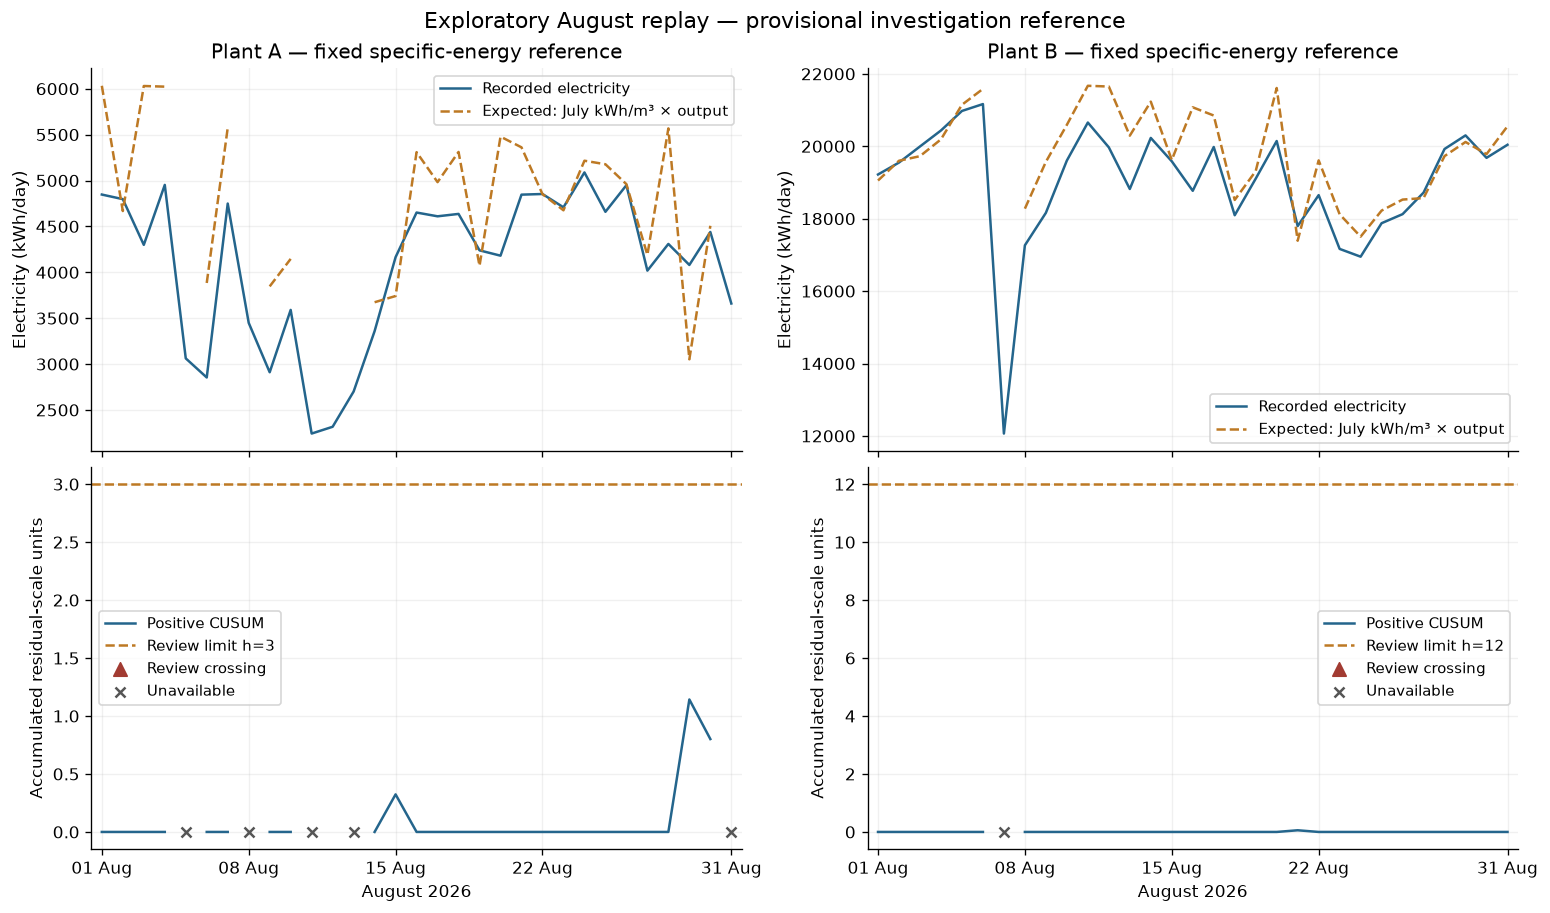

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(12.8, 7.5), sharex=True, layout='constrained')
for column, (plant, frame) in enumerate(energy_replay.groupby('Plant')):
    top, bottom = axes[:, column]
    top.plot(frame.date, frame.recorded_electricity_kwh, color='#24658c', label='Recorded electricity')
    top.plot(frame.date, frame.expected_electricity_kwh, '--', color='#bd7924', label='Expected: July kWh/m³ × output')
    top.set(title=plant+' — fixed specific-energy reference', ylabel='Electricity (kWh/day)')
    top.legend(fontsize=9)
    bottom.plot(frame.date, frame.cusum_score, color='#24658c', label='Positive CUSUM')
    limit = selected_settings[plant]['decision_limit_h']
    bottom.axhline(limit, ls='--', color='#bd7924', label=f'Review limit h={limit:g}')
    flagged, unavailable = frame.loc[frame.review_flag], frame.loc[~frame.eligible]
    bottom.scatter(flagged.date, flagged.cusum_score, marker='^', color='#a23b32', s=65, label='Review crossing', zorder=4)
    bottom.scatter(unavailable.date, np.zeros(len(unavailable)), marker='x', color='#555555', label='Unavailable', zorder=4)
    bottom.set(ylabel='Accumulated residual-scale units', xlabel='August 2026')
    bottom.legend(fontsize=9)
    bottom.xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1,8,15,22,31]))
    bottom.xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    bottom.set_xlim(pd.Timestamp('2026-08-01')-pd.Timedelta(hours=12), pd.Timestamp('2026-08-31')+pd.Timedelta(hours=12))
fig.suptitle('Exploratory August replay — provisional investigation reference', fontsize=13)
fig.savefig(energy_dir / 'energy_cusum_replay.png', dpi=160)
plt.show()

### Constructed response of the selected reference

Each displayed path is the first independently seeded evaluation path, with daily excess equal to 10% of July mean electricity added from simulated day 8 at unchanged output. Generated scores are not plant observations. Repeated triangles reflect the prototype's automatic restart after a crossing.

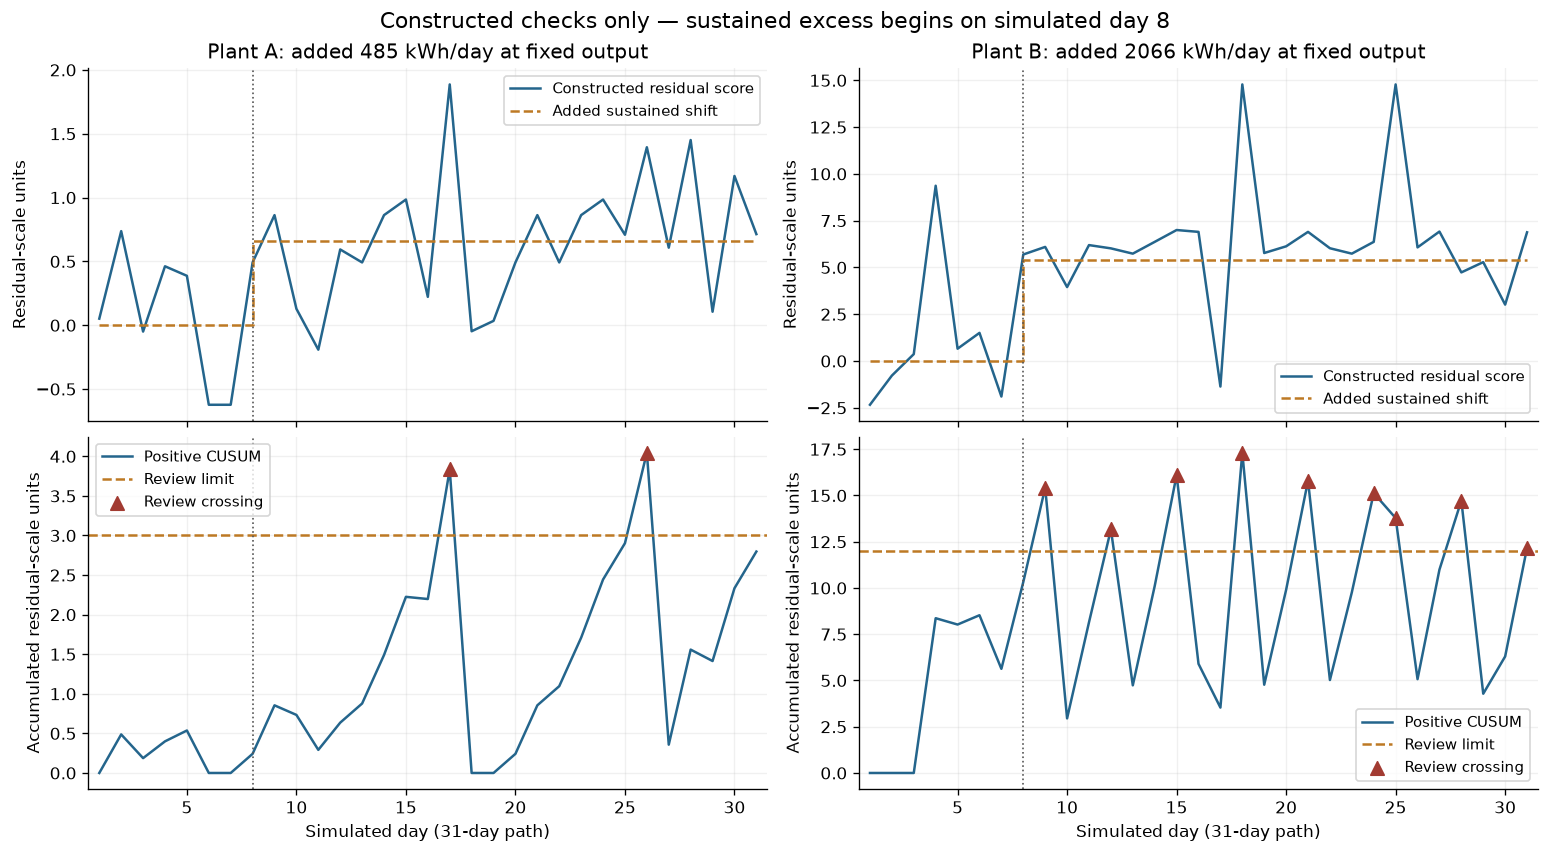

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(12.8, 7), sharex=True, layout='constrained')
for column, plant in enumerate(energy_models):
    model, settings = energy_models[plant], selected_settings[plant]
    noise = residual_paths(energy_references[plant], model, 822+column, evaluation_paths)[0]
    added = np.r_[np.zeros(change_day), np.ones(31-change_day)*target_shifts[plant]/model['residual_scale_kwh']]
    values = noise+added
    chart = cusum_scores(pd.Series(values,index=simulation_dates), allowance=settings['allowance_k'], decision_limit=settings['decision_limit_h'])
    days = np.arange(1,32)
    axes[0,column].plot(days,values,color='#24658c',label='Constructed residual score')
    axes[0,column].step(days,added,where='post',ls='--',color='#bd7924',label='Added sustained shift')
    axes[0,column].set(title=f"{plant}: added {target_shifts[plant]:.0f} kWh/day at fixed output",ylabel='Residual-scale units')
    axes[0,column].legend(fontsize=9)
    axes[1,column].plot(days,chart.cusum_score,color='#24658c',label='Positive CUSUM')
    axes[1,column].axhline(settings['decision_limit_h'],ls='--',color='#bd7924',label='Review limit')
    flags=chart.review_flag.to_numpy()
    axes[1,column].scatter(days[flags],chart.cusum_score[flags],marker='^',color='#a23b32',s=65,label='Review crossing',zorder=4)
    axes[1,column].set(xlabel='Simulated day (31-day path)',ylabel='Accumulated residual-scale units',xlim=(.5,31.5))
    axes[1,column].legend(fontsize=9)
    for ax in axes[:,column]:
        ax.axvline(change_day+1,color='#555555',ls=':',lw=1)
fig.suptitle('Constructed checks only — sustained excess begins on simulated day 8',fontsize=13)
fig.savefig(energy_dir/'energy_constructed_check.png',dpi=160)
plt.show()

### Selected-reference diagnostics

Inspect output/energy relationships, residuals versus predictions and residuals over time. August out-of-range points remain diagnostic only. Shifted means, time dependence or output-dependent noise limit the interpretation of simulation-derived thresholds.

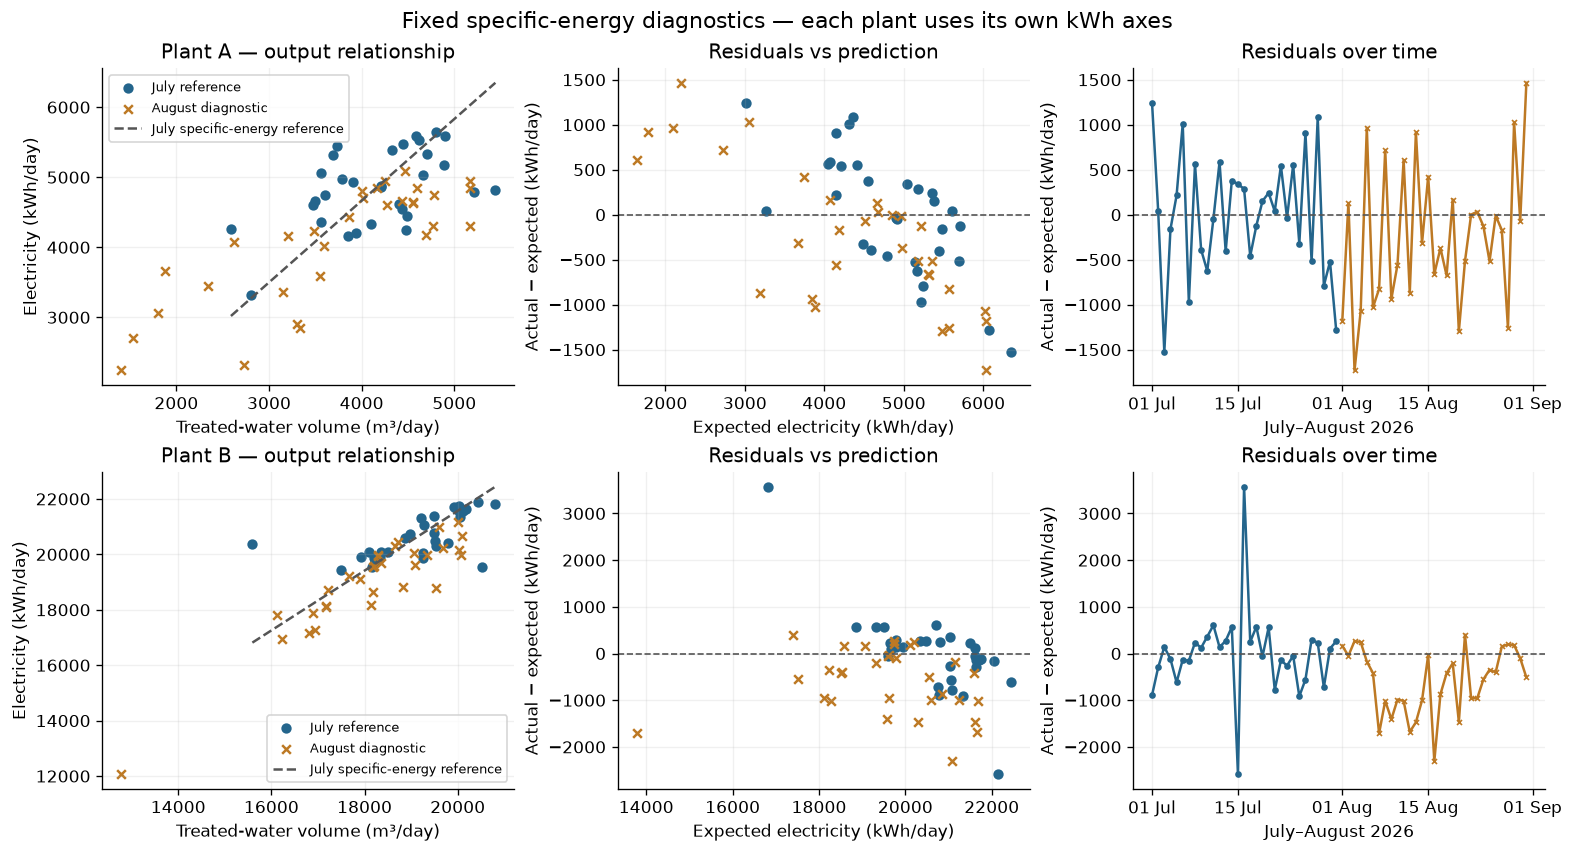

,Plant,Period,days,mean_residual_kwh,residual_sd_kwh,lag1_residual_correlation,abs_residual_vs_prediction_correlation
0,Plant A,July reference,31,0.000,669.068,-0.216,0.012
1,Plant A,August diagnostic,31,-249.394,782.369,-0.316,-0.029
2,Plant B,July reference,31,-0.000,914.346,-0.359,-0.358
3,Plant B,August diagnostic,31,-595.385,700.102,0.318,0.073


In [40]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
energy_diagnostic_rows = []
for row, (plant, model) in enumerate(energy_models.items()):
    for month, label, marker, color in [(7,'July reference','o','#24658c'),(8,'August diagnostic','x','#bd7924')]:
        frame = performance.loc[performance.plant.eq(plant) & performance.date.dt.month.eq(month)].sort_values('date')
        predicted = model['intercept_kwh']+model['slope_kwh_per_m3']*frame.effluent_volume_m3
        residual = frame.daily_electricity_kwh-predicted
        axes[row,0].scatter(frame.effluent_volume_m3, frame.daily_electricity_kwh, marker=marker, color=color, label=label, s=27)
        axes[row,1].scatter(predicted, residual, marker=marker, color=color, label=label, s=27)
        axes[row,2].plot(frame.date, residual, marker=marker, ms=3, color=color, label=label)
        energy_diagnostic_rows.append({'Plant': plant, 'Period': label, 'days': len(frame),
            'mean_residual_kwh': residual.mean(), 'residual_sd_kwh': residual.std(ddof=1),
            'lag1_residual_correlation': residual.reset_index(drop=True).autocorr(1),
            'abs_residual_vs_prediction_correlation': abs(residual).corr(predicted)})
    domain = np.array([model['output_min_m3'],model['output_max_m3']])
    axes[row,0].plot(domain,model['intercept_kwh']+model['slope_kwh_per_m3']*domain,'--',color='#555555',label='July specific-energy reference')
    axes[row,0].set(title=plant+' — output relationship',xlabel='Treated-water volume (m³/day)',ylabel='Electricity (kWh/day)')
    axes[row,1].set(title='Residuals vs prediction',xlabel='Expected electricity (kWh/day)',ylabel='Actual − expected (kWh/day)')
    axes[row,2].set(title='Residuals over time',xlabel='July–August 2026',ylabel='Actual − expected (kWh/day)')
    for ax in axes[row,1:]:
        ax.axhline(0,color='#555555',ls='--',lw=1)
    axes[row,2].xaxis.set_major_locator(mdates.DayLocator(bymonthday=[1,15]))
    axes[row,2].xaxis.set_major_formatter(mdates.DateFormatter('%d %b'))
    axes[row,0].legend(fontsize=8)
fig.suptitle('Fixed specific-energy diagnostics — each plant uses its own kWh axes',fontsize=13)
fig.savefig(energy_dir / 'energy_model_diagnostics.png',dpi=160)
plt.show()
energy_model_diagnostics = pd.DataFrame(energy_diagnostic_rows)
energy_model_diagnostics.to_csv(energy_dir / 'energy_model_diagnostics.csv',index=False)
display(energy_model_diagnostics.round(3))

### Practical indicators and review rule

- **Specific energy (kWh/m³):** daily electricity / treated-water volume, shown with output so low production is visible.
- **Expected electricity and daily excess (kWh/day):** fixed July kWh/m³ × today's output; actual minus expected.
- **CUSUM evidence:** accumulated positive scaled excess. Investigate when it exceeds the displayed plant limit; one crossing can result from a large isolated spike.
- **Comparison status:** valid, inside reference output range, or unavailable. Missing/invalid/out-of-range days reset evidence and must not be called normal.

Review wording: **“Electricity above the production-adjusted reference; check readings, loading, treatment settings and operating records.”** Show supporting dates, actual/expected kWh, excess, output and comparison status. Do not automatically change operating settings. Restart after each crossing is a demonstration policy; operators must agree reference periods, practical target shift, review workload and acknowledgement/reset handling before adoption.

In [41]:
for plant,model in energy_models.items():
    summary = energy_replay_summary.loc[energy_replay_summary.Plant.eq(plant)].iloc[0]
    checks = energy_simulation_checks.loc[energy_simulation_checks.Plant.eq(plant) &
        energy_simulation_checks.Baseline.eq('Fixed specific energy') & energy_simulation_checks.Method.eq('CUSUM')]
    standard = checks.loc[checks.residual_block_days.eq(3)].set_index('Scenario')
    longer = checks.loc[checks.residual_block_days.eq(7)].set_index('Scenario')
    settings = selected_settings[plant]
    print(f"{plant}: expected kWh = {model['slope_kwh_per_m3']:.4f} × output m³; k={settings['allowance_k']:g}, h={settings['decision_limit_h']:g}.")
    print(f"  August: {summary['Eligible days']:.0f}/31 comparable days, {summary['CUSUM review events']:.0f} candidate reviews; RMSE {summary['RMSE kWh/day']:.0f} kWh/day.")
    print(f"  Constructed +{target_shifts[plant]:.0f} kWh/day: {standard.loc['Sustained +10% July mean','detection_within_14_days']:.1%} detected within 14 days; "
        f"median detected delay {standard.loc['Sustained +10% July mean','median_delay_days_detected']:g} days.")
    print(f"  Simulated no-change paths with review: 3-day blocks {standard.loc['No change','fraction_with_any_review']:.1%}, "
        f"7-day blocks {longer.loc['No change','fraction_with_any_review']:.1%}. These are conditional simulation results, not site false-alert rates.")
assert all(hashlib.sha256(path.read_bytes()).hexdigest()==digest for path,digest in source_hashes.items())
assert not (source_dir.parent/'EARLY_DETECTION.md').exists() and not (source_dir.parent/'OPERATOR_ALERTS.md').exists()
print('Chronological prefixes, paired comparison coverage and source preservation checked; fresh records and operator validation remain required.')

Plant A: expected kWh = 1.1663 × output m³; k=0.25, h=3.
  August: 26/31 comparable days, 0 candidate reviews; RMSE 772 kWh/day.
  Constructed +485 kWh/day: 95.2% detected within 14 days; median detected delay 6 days.
  Simulated no-change paths with review: 3-day blocks 6.8%, 7-day blocks 0.5%. These are conditional simulation results, not site false-alert rates.
Plant B: expected kWh = 1.0785 × output m³; k=1, h=12.
  August: 30/31 comparable days, 0 candidate reviews; RMSE 871 kWh/day.
  Constructed +2066 kWh/day: 100.0% detected within 14 days; median detected delay 3 days.
  Simulated no-change paths with review: 3-day blocks 7.5%, 7-day blocks 2.5%. These are conditional simulation results, not site false-alert rates.
Chronological prefixes, paired comparison coverage and source preservation checked; fresh records and operator validation remain required.
